In [1]:
import pandas as pd
import numpy as np
import sys
import xarray as xr
import seaborn as sns
from scipy import stats
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LogNorm
from IPython.display import Image, display
import glob
# set warning to ignore
import warnings
warnings.filterwarnings("ignore", category=UserWarning, append=True)
sns.set_context("talk", font_scale=0.7)

In [2]:
sys.path.append('./../../../ectools/')
from ectools import ecio
from ectools import ecplot as ecplt

stratus_regions = {
    'SEA': {'lat': (-22.5, -5), 'lon': (-5, 15)}, # 'lat': (-20, -10), 'lon': (0, 10) original SEA from Klein and Hartmann
    'NEA': {'lat': (10, 30), 'lon': (-40, -20)},
    'SEP': {'lat': (-22.5, -5), 'lon': (-95, -75)},
    'NEP': {'lat': (15, 35), 'lon': (-135, -115)},
}
stratus_region_names = {
    0: 'SEA',
    1: 'NEA',
    2: 'SEP',
    3: 'NEP',
}

In [ ]:
sys.path.append('./../')
sys.path.append('/home/jmayer/ACI_research/Code/lwp_adjustments/src')
import functions as fct
import utils_analysis as uana

# Read in combined dataset

In [ ]:
dataset_filename = '/home/jmayer/ACI_research/Code/resources/ACMCAP_XMET_judge_StCu_Jun-Aug.h5'
df = pd.read_hdf(dataset_filename, key='StCu')

## Filter dataset

<Axes: ylabel='Frequency'>

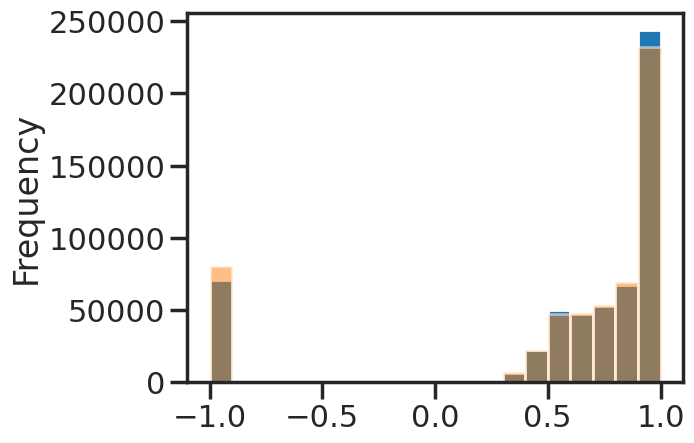

In [5]:
df.cert_0.plot.hist(bins=20)
df.cert_1.plot.hist(bins=20, alpha=0.5)

<Axes: ylabel='Frequency'>

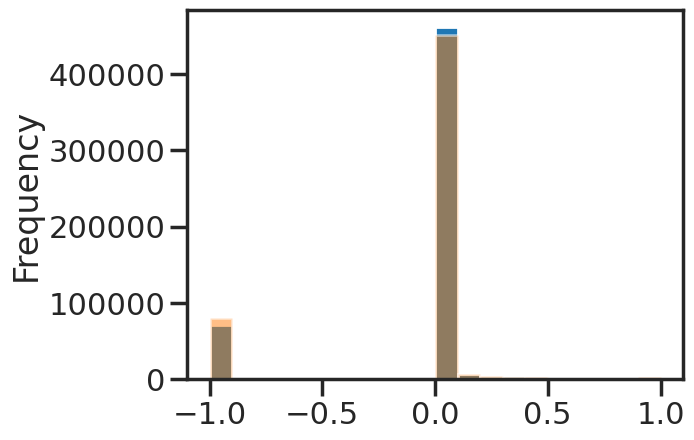

In [6]:
df['ice_flag_0'].astype(float).plot.hist(bins=20)
df['ice_flag_1'].astype(float).plot.hist(bins=20, alpha=0.5)

In [7]:
df

,along_track,time,latitude,longitude,stratus_region_index,lwp,ER,ER_passive_perspective,Nd,lwp_error,...,ice_flag_1,scene_id_0,scene_id_1,MCOP_cloud_cover_judge_0,MCOP_cloud_cover_judge_1,MCOP_cwp_skew_judge_0,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1,ocean_mask
0,2981,2025-06-01 13:26:02.599795968,-5.001905,7.111185,0,0.000051,8.760879e-07,8.760849e-07,54752600.00,0.478148,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
1,2982,2025-06-01 13:26:02.736145920,-5.010733,7.109528,0,0.007185,4.358948e-06,4.684363e-06,55660160.00,0.330290,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
2,2983,2025-06-01 13:26:02.872495872,-5.019562,7.107870,0,0.000300,1.552164e-06,1.558314e-06,57090188.00,0.479258,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
3,2984,2025-06-01 13:26:03.008845952,-5.028391,7.106212,0,0.011196,4.916011e-06,5.970363e-06,62343752.00,0.341860,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
4,2985,2025-06-01 13:26:03.190764032,-5.040170,7.104001,0,0.025249,6.399618e-06,6.650821e-06,65047464.00,0.376912,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
452588,815,2025-08-31 22:38:59.105735936,15.043125,-128.786007,3,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
452589,816,2025-08-31 22:38:59.240677504,15.034392,-128.787718,3,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
452590,817,2025-08-31 22:38:59.375615872,15.025658,-128.789429,3,0.009169,1.312405e-05,1.326506e-05,2855815.25,0.088560,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
452591,818,2025-08-31 22:38:59.510556032,15.016924,-128.791140,3,0.027764,1.224727e-05,1.237362e-05,8873747.00,0.370534,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True


In [5]:
# we always filter out ocean pixels
df = df[(df.ocean_mask == 1)]

In [6]:
dffil = df.copy()

variables = ['time', 'N_high_cc', 'along_track',
       'latitude', 'longitude', 'daytime', 'lwp', 'ER', 'Nd', 'lwp_error',
       'Nd_error', 'liquid_classification_mean', 'liquid_optical_depth', 'cth',
       'cbh', 'cth_m', 'cbh_m', 'cth_all_clouds', 'multilayer',
       'N_cloudy_pixels', 'rain_rate_surface', 'rain_rate_cbh',
       'rain_rate_max', 'rain_rate_subcloud', 'doppler_velocity_mean', 'cbh_minus_lcl', 'coupled_fraction',
       'boundary_layer_height', 'sea_surface_temperature', 'lower_tropospheric_stability',
       'inversion_strength', 
       'MCOP_cwp_skew_200', 'MCOP_cwp_inhomogeneity_200', 'MCOP_cloud_cover_200',
       'orbit', 'stratus_region_index', 'ocean_mask',
       'lwc_profile', 'rain_rate_profile', 'rain_rate_below_cloud_profile'
       ]

variables = ['time', 'N_high_cc', 'along_track',
       'latitude', 'longitude', 'daytime', 'lwp', 'ER', 'Nd', 'lwp_error',
       'Nd_error', 'liquid_classification_mean', 'liquid_optical_depth', 'cth',
       'cbh', 'cth_m', 'cbh_m', 'cth_all_clouds', 'multilayer',
       'N_cloudy_pixels', 'rain_rate_surface', 'rain_rate_cbh',
       'rain_rate_max', 'rain_rate_subcloud', 'doppler_velocity_mean', 'cbh_minus_lcl',
       'boundary_layer_height', 'sea_surface_temperature', 'lower_tropospheric_stability',
       'inversion_strength', 
       'MCOP_cwp_skew_256', 'MCOP_cwp_inhomogeneity_256', 'MCOP_cloud_cover_256',
       'orbit', 'stratus_region_index', 'ocean_mask',
       'lwc_profile', 'rain_rate_profile', 'rain_rate_below_cloud_profile'
       ]
# filters:
# 1) matching judge scene exists; 2) ice-free; 3) high confidence; 4) at least 10% cloud cover in MCOP
dffil_0 = dffil[
    (dffil.scene_id_0 != -1) &
    (dffil.ice_flag_0 == 0) &
    (dffil.cert_0 > 0.75) & 
    (dffil.MCOP_cloud_cover_judge_0 >= 0.1)
              ][variables + ['cats_0', 'cert_0', 'ice_flag_0', 'scene_id_0',
                            'MCOP_cloud_cover_judge_0', 'MCOP_cwp_skew_judge_0',
                            'MCOP_cwp_inhomogeneity_judge_0']]

dffil_1 = dffil[
    (dffil.scene_id_1 != -1) &
    (dffil.ice_flag_1 == 0) &
    (dffil.cert_1 > 0.75) & 
    (dffil.MCOP_cloud_cover_judge_1 >= 0.1)
              ][variables + ['cats_1', 'cert_1', 'ice_flag_1', 'scene_id_1',
                            'MCOP_cloud_cover_judge_1', 'MCOP_cwp_skew_judge_1',
                            'MCOP_cwp_inhomogeneity_judge_1']]

In [7]:
dffil_0.rename(columns={col: col.replace('_0','') for col in dffil_0.columns if col.endswith('_0') and col != 'scene_id_0'}, inplace=True)
dffil_1.rename(columns={col: col.replace('_1','') for col in dffil_1.columns if col.endswith('_1') and col != 'scene_id_1'}, inplace=True)

In [8]:
dffil = pd.concat([dffil_0, dffil_1], axis=0, ignore_index=True)
dffil['scene_id'] = np.where(~np.isnan(dffil.scene_id_0), dffil.scene_id_0, dffil.scene_id_1 + dffil.scene_id_0.max() + dffil.scene_id_1.min())

In [9]:
dffil.scene_id.unique()

array([0.0000e+00, 4.0000e+00, 6.0000e+00, ..., 1.7196e+04, 1.7198e+04,
       1.7200e+04], shape=(4511,))

In [10]:
(((dffil.scene_id_0 != -1)).sum()/len(df), 
 ((dffil.ice_flag == 0)).sum()/len(df), 
 ((dffil.cert > 0.75)).sum()/len(df), 
 ((dffil.MCOP_cloud_cover_judge >= 0.1)).sum()/len(df), 
 len(dffil)/len(df))

(np.float64(0.9551630511372711),
 np.float64(0.9551630511372711),
 np.float64(0.9551630511372711),
 np.float64(0.9551630511372711),
 0.9551630511372711)

In [11]:
df

,along_track,time,latitude,longitude,stratus_region_index,lwp,ER,ER_passive_perspective,Nd,lwp_error,...,ice_flag_1,scene_id_0,scene_id_1,MCOP_cloud_cover_judge_0,MCOP_cloud_cover_judge_1,MCOP_cwp_skew_judge_0,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1,ocean_mask
0,2981,2025-06-01 13:26:02.599795968,-5.001905,7.111185,0,0.000051,8.760879e-07,8.760849e-07,54752600.00,0.478148,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
1,2982,2025-06-01 13:26:02.736145920,-5.010733,7.109528,0,0.007185,4.358948e-06,4.684363e-06,55660160.00,0.330290,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
2,2983,2025-06-01 13:26:02.872495872,-5.019562,7.107870,0,0.000300,1.552164e-06,1.558314e-06,57090188.00,0.479258,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
3,2984,2025-06-01 13:26:03.008845952,-5.028391,7.106212,0,0.011196,4.916011e-06,5.970363e-06,62343752.00,0.341860,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
4,2985,2025-06-01 13:26:03.190764032,-5.040170,7.104001,0,0.025249,6.399618e-06,6.650821e-06,65047464.00,0.376912,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
452588,815,2025-08-31 22:38:59.105735936,15.043125,-128.786007,3,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
452589,816,2025-08-31 22:38:59.240677504,15.034392,-128.787718,3,0.000000,NaN,NaN,NaN,NaN,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
452590,817,2025-08-31 22:38:59.375615872,15.025658,-128.789429,3,0.009169,1.312405e-05,1.326506e-05,2855815.25,0.088560,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True
452591,818,2025-08-31 22:38:59.510556032,15.016924,-128.791140,3,0.027764,1.224727e-05,1.237362e-05,8873747.00,0.370534,...,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,True


In [12]:
dffil

,time,N_high_cc,along_track,latitude,longitude,daytime,lwp,ER,Nd,lwp_error,...,rain_rate_below_cloud_profile,cats,cert,ice_flag,scene_id_0,MCOP_cloud_cover_judge,MCOP_cwp_skew_judge,MCOP_cwp_inhomogeneity_judge,scene_id_1,scene_id
0,2025-06-01 13:26:03.463464192,7.0,2987,-5.057828,7.100684,1,0.001280,2.155813e-06,63439672.0,0.283856,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.996926,0.0,0.0,0.352478,3.850699,0.837963,NaN,0.0
1,2025-06-01 13:26:03.599814144,6.0,2988,-5.066657,7.099025,1,0.000253,1.316005e-06,62802676.0,0.424500,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.996926,0.0,0.0,0.352478,3.850699,0.837963,NaN,0.0
2,2025-06-01 13:26:03.736166016,6.0,2989,-5.075486,7.097367,1,0.000051,8.385292e-07,62447560.0,0.573121,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.996926,0.0,0.0,0.352478,3.850699,0.837963,NaN,0.0
3,2025-06-01 13:26:03.872514048,6.0,2990,-5.084315,7.095709,1,0.036758,7.267364e-06,64207960.0,0.180810,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.996926,0.0,0.0,0.352478,3.850699,0.837963,NaN,0.0
4,2025-06-01 13:26:04.008864128,6.0,2991,-5.093143,7.094050,1,0.002043,2.736670e-06,66933144.0,0.441301,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.996926,0.0,0.0,0.352478,3.850699,0.837963,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
508328,2025-08-31 22:37:44.239626752,1.0,291,19.886969,-127.821561,1,0.000010,8.233781e-07,65955332.0,1.542368,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.997707,0.0,NaN,0.370422,7.760601,1.172843,8602.0,17200.0
508329,2025-08-31 22:37:44.374648320,2.0,292,19.878238,-127.823336,1,0.000000,NaN,NaN,NaN,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.997707,0.0,NaN,0.370422,7.760601,1.172843,8602.0,17200.0
508330,2025-08-31 22:37:44.509668096,2.0,293,19.869507,-127.825111,1,0.000000,NaN,NaN,NaN,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.997707,0.0,NaN,0.370422,7.760601,1.172843,8602.0,17200.0
508331,2025-08-31 22:37:44.644688256,2.0,294,19.860776,-127.826886,1,0.000021,7.931145e-07,73797248.0,1.031383,...,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5,0.997707,0.0,NaN,0.370422,7.760601,1.172843,8602.0,17200.0


In [13]:
(dffil.lwp == 0).sum()

np.int64(131601)

# Analysis

## functions and computation of needed variables

In [14]:
sns.set_context("talk", font_scale=0.8)
sns.set_style('white')

In [15]:
# get 6 distinct colors from the viridis colormap
cmap = matplotlib.cm.get_cmap('viridis', 6)
catcolors = [cmap(i) for i in range(cmap.N)]

#colors = ['#1f77b4', '#2ca02c', '#ff7f0e',  '#d62728', '#e377c2', '#8c564b', 'black']

line_styles = [(0, (3, 1, 1, 1)), '-', '--', '-.', (0,(3,1,1,1,1,1)), ':']

In [16]:
cats_names = {
    0: 'Solid Stratus',
    1: 'Closed MCC',
    2: 'Open MCC',
    3: 'Disorg. MCC',
    4: 'Clustered Cu',
    5: 'Suppr. Cu'
    }

palette_catscolors = {i: catcolors[i] for i in range(6)}
palette_catscolors[6] = 'lightgray'  # for unclassified

In [17]:
from matplotlib.lines import Line2D

# Custom legend with line styles
legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in range(6)
]

In [18]:
from matplotlib import colors
from mpl_toolkits.basemap import Basemap

In [19]:
def bmap(ax=None, drawlines=True, llr=None, par_labs=[1, 0, 0, 0], mer_labs=[0, 0, 0, 1], 
         merspace=5, parspace=5, **kwargs):

    if ax is None:
        fig, ax = plt.subplots()

    lat_range = llr['lat']
    lon_range = llr['lon']
    
    if 'projection' not in kwargs.keys():
        kwargs['projection'] = 'cyl'
        kwargs['rsphere'] =(6378137.00, 6356752.3142)
    m = Basemap(llcrnrlon=lon_range[0], llcrnrlat=lat_range[0],
                urcrnrlon=lon_range[1],  urcrnrlat=lat_range[1],
                ax=ax, resolution='l', **kwargs)
    if drawlines:
        m.drawparallels(np.arange(-90., 90., parspace), labels=par_labs, fontsize=14)
        m.drawmeridians(np.arange(-180., 180., merspace), labels=mer_labs, fontsize=14)
    m.drawcoastlines()
    m.fillcontinents(color="white", lake_color="white")

    return m

In [20]:
dffil['rain_rate_cbh_113'] = dffil.groupby(['orbit', 'scene_id'])['rain_rate_cbh'].transform(lambda x: np.nanmean(x))
dffil['rain_rate_cbh_everywhere_113'] = dffil.groupby(['orbit', 'scene_id'])['rain_rate_cbh'].transform(lambda x: np.mean(x.fillna(0)))

In [21]:
dffil['rain_rate_cbh_std_113'] = dffil.groupby(['orbit', 'scene_id'])['rain_rate_cbh'].transform(lambda x: np.nanstd(x.fillna(0)))

## transitions

In [23]:
# TODO find a better way to combine cats_0 and cats_1
# TODO maybe we should combine cats 0 and 1 into one category, as well as cats 3, 4 and 5??

In [24]:
df['cats'] = df['cats_0']
df['cert'] = df['cert_0']
df['scene_id'] = df['scene_id_0']
df['ice_flag'] = df['ice_flag_0']
df['MCOP_cloud_cover_judge'] = df['MCOP_cloud_cover_judge_0']

In [25]:
# new column with orbit without last letter
df['orbit_base'] = df['orbit'].str[:-1]

In [26]:
# sort df by orbit_base and time
df = df.sort_values(by=['orbit_base', 'time'])

In [27]:
df = df.reset_index()

In [28]:
df

,index,along_track,time,latitude,longitude,stratus_region_index,lwp,ER,ER_passive_perspective,Nd,...,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1,ocean_mask,cats,cert,scene_id,ice_flag,MCOP_cloud_cover_judge,orbit_base
0,0,2981,2025-06-01 13:26:02.599795968,-5.001905,7.111185,0,0.000051,8.760879e-07,8.760849e-07,54752600.00,...,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0,05735
1,1,2982,2025-06-01 13:26:02.736145920,-5.010733,7.109528,0,0.007185,4.358948e-06,4.684363e-06,55660160.00,...,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0,05735
2,2,2983,2025-06-01 13:26:02.872495872,-5.019562,7.107870,0,0.000300,1.552164e-06,1.558314e-06,57090188.00,...,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0,05735
3,3,2984,2025-06-01 13:26:03.008845952,-5.028391,7.106212,0,0.011196,4.916011e-06,5.970363e-06,62343752.00,...,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0,05735
4,4,2985,2025-06-01 13:26:03.190764032,-5.040170,7.104001,0,0.025249,6.399618e-06,6.650821e-06,65047464.00,...,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0,05735
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
532190,452588,815,2025-08-31 22:38:59.105735936,15.043125,-128.786007,3,0.000000,NaN,NaN,NaN,...,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0,07157
532191,452589,816,2025-08-31 22:38:59.240677504,15.034392,-128.787718,3,0.000000,NaN,NaN,NaN,...,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0,07157
532192,452590,817,2025-08-31 22:38:59.375615872,15.025658,-128.789429,3,0.009169,1.312405e-05,1.326506e-05,2855815.25,...,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0,07157
532193,452591,818,2025-08-31 22:38:59.510556032,15.016924,-128.791140,3,0.027764,1.224727e-05,1.237362e-05,8873747.00,...,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0,07157


In [29]:
#df.drop(columns=['level_0'], inplace=True)

### CC

In [ ]:
# get transitions from cats = 1 to cats = 2 or the other way round
trans_cc = []
for i in range(1, len(df)):
    if (df.cats.iloc[i-1] == 1 and df.cats.iloc[i] == 1 and df.cert.iloc[i-1] >= 0.9 and df.cert.iloc[i] >= 0.9):
        trans_cc.append(df.index[i])

In [ ]:
df.loc[trans_cc]

,Unnamed: 0.1,time,N_high_cc,Unnamed: 0,along_track,latitude,longitude,daytime,lwp,ER,...,MCOP_cloud_cover_judge_1,MCOP_cwp_skew_judge_0,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1,ocean_mask,cats,cert,ice_flag,MCOP_cloud_cover_judge
6566,6566,2025-05-02 13:11:06.661523968,4,6566,4344,-17.581944,9.314750,True,0.000119,0.000001,...,0.744019,1.152102,1.412928,0.527519,0.522850,True,1,0.951153,0.0,0.754456
6567,6567,2025-05-02 13:11:06.799061888,4,6567,4345,-17.590830,9.312984,True,0.001466,0.000002,...,0.744019,1.152102,1.412928,0.527519,0.522850,True,1,0.951153,0.0,0.754456
6568,6568,2025-05-02 13:11:06.936600064,4,6568,4346,-17.599717,9.311217,True,0.003946,0.000002,...,0.744019,1.152102,1.412928,0.527519,0.522850,True,1,0.951153,0.0,0.754456
6569,6569,2025-05-02 13:11:07.074136320,4,6569,4347,-17.608603,9.309450,True,0.000708,0.000002,...,0.744019,1.152102,1.412928,0.527519,0.522850,True,1,0.951153,0.0,0.754456
6570,6570,2025-05-02 13:11:07.211675904,4,6570,4348,-17.617488,9.307682,True,0.002518,0.000002,...,0.744019,1.152102,1.412928,0.527519,0.522850,True,1,0.951153,0.0,0.754456
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1009547,1009547,2025-07-30 22:30:18.381391616,6,1009547,236,20.407512,-125.847750,True,0.021518,0.000005,...,0.907898,1.268729,1.288550,0.405332,0.478246,True,1,0.999952,0.0,0.945312
1009548,1009548,2025-07-30 22:30:18.516571776,6,1009548,237,20.398773,-125.849535,True,0.046473,0.000007,...,0.907898,1.268729,1.288550,0.405332,0.478246,True,1,0.999952,0.0,0.945312
1009549,1009549,2025-07-30 22:30:18.705509120,6,1009549,238,20.386558,-125.852029,True,0.013234,0.000005,...,0.907898,1.268729,1.288550,0.405332,0.478246,True,1,0.999952,0.0,0.945312
1009550,1009550,2025-07-30 22:30:18.840689152,6,1009550,239,20.377818,-125.853814,True,0.020719,0.000007,...,0.907898,1.268729,1.288550,0.405332,0.478246,True,1,0.999952,0.0,0.945312


In [ ]:
# create a new dataframe combining all transitions
# select randomly 100 transitions
sel_i = np.random.choice(len(trans_cc), size=100, replace=False)
dfall_trans_cc = None
for i in sel_i:
    print(f'Transition {i+1} at index {trans_cc[i]}')
    df_trans_cc = df.loc[trans_cc[i] - 113 : trans_cc[i] + 112].reset_index(drop=True)
    # make a column for the index
    df_trans_cc['transition'] = df_trans_cc.index - 113
    if dfall_trans_cc is None:
        dfall_trans_cc = df_trans_cc
    else:
        dfall_trans_cc = pd.concat([dfall_trans_cc, df_trans_cc], axis=0)
dfall_trans_cc.reset_index(inplace=True)

Transition 39626 at index 946161
Transition 5399 at index 108541
Transition 43019 at index 1008614
Transition 36739 at index 898976
Transition 23559 at index 452372
Transition 22064 at index 443316
Transition 42524 at index 997595
Transition 35184 at index 893986
Transition 33063 at index 877593
Transition 11664 at index 210593
Transition 25774 at index 637017
Transition 21418 at index 435648
Transition 36058 at index 898295
Transition 36983 at index 901551
Transition 30283 at index 832519
Transition 33941 at index 881567
Transition 7300 at index 137761
Transition 37126 at index 905014
Transition 13368 at index 232572
Transition 29437 at index 806882
Transition 9076 at index 176334
Transition 31649 at index 863951
Transition 5836 at index 111099
Transition 28900 at index 805664
Transition 4614 at index 97981
Transition 16300 at index 358317
Transition 21259 at index 434924
Transition 2414 at index 66943
Transition 14298 at index 288117
Transition 26861 at index 716222
Transition 7142 a

In [ ]:
dfall_trans_cc

,index,Unnamed: 0.1,time,N_high_cc,Unnamed: 0,along_track,latitude,longitude,daytime,lwp,...,MCOP_cwp_skew_judge_0,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1,ocean_mask,cats,cert,ice_flag,MCOP_cloud_cover_judge,transition
0,0,946048,2025-07-12 22:34:36.346339456,4,946048,3770,33.414839,-124.871533,True,0.050765,...,1.237092,1.374515,0.574506,0.531198,True,1,0.999402,0.0,0.994019,-113
1,1,946049,2025-07-12 22:34:36.532397184,4,946049,3771,33.402859,-124.874418,True,0.049826,...,1.237092,1.374515,0.574506,0.531198,True,1,0.999402,0.0,0.994019,-112
2,2,946050,2025-07-12 22:34:36.668056832,4,946050,3772,33.394123,-124.876522,True,0.039847,...,1.237092,1.374515,0.574506,0.531198,True,1,0.999402,0.0,0.994019,-111
3,3,946051,2025-07-12 22:34:36.803717248,4,946051,3773,33.385387,-124.878625,True,0.031450,...,1.237092,1.341200,0.574506,0.600879,True,1,0.999402,0.0,0.994019,-110
4,4,946052,2025-07-12 22:34:36.939375360,4,946052,3774,33.376651,-124.880728,True,0.042714,...,1.237092,1.341200,0.574506,0.600879,True,1,0.999402,0.0,0.994019,-109
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22513,221,447557,2025-07-28 19:47:00.410813568,4,447557,4715,-21.019128,-90.325043,True,0.042882,...,1.398182,2.242505,0.841907,0.809210,True,3,0.985053,0.0,0.634277,108
22514,222,447558,2025-07-28 19:47:00.547773696,4,447558,4716,-21.027969,-90.326854,True,0.059968,...,1.398182,2.242505,0.841907,0.809210,True,3,0.985053,0.0,0.634277,109
22515,223,447559,2025-07-28 19:47:00.684733568,4,447559,4717,-21.036809,-90.328665,True,0.070536,...,1.398182,2.242505,0.841907,0.809210,True,3,0.985053,0.0,0.634277,110
22516,224,447560,2025-07-28 19:47:00.821693696,4,447560,4718,-21.045649,-90.330477,True,0.093207,...,1.398182,2.242505,0.841907,0.809210,True,3,0.985053,0.0,0.634277,111


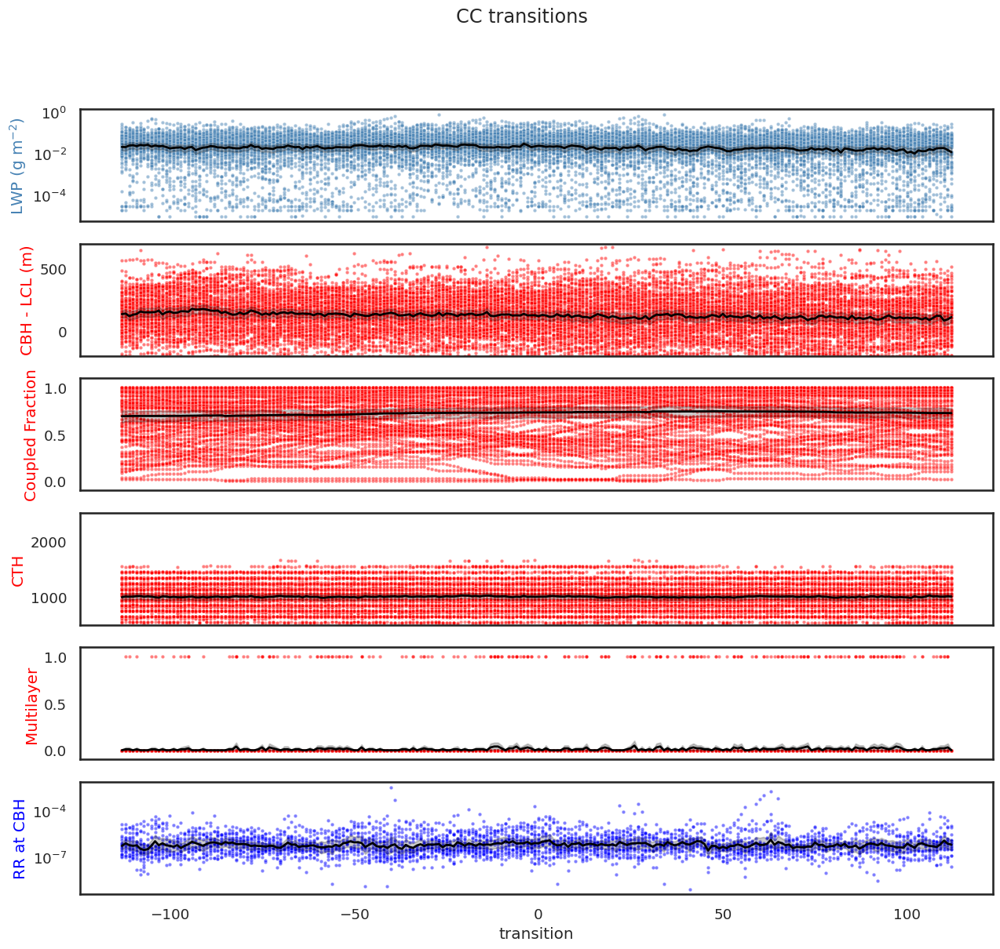

In [ ]:
fig, axs = plt.subplots(6,1, figsize=(15,13), sharex=True)
plt.suptitle('CC transitions')
ax=axs[0]
sns.scatterplot(ax=ax, data=dfall_trans_cc[dfall_trans_cc['lwp']>0], x='transition', y='lwp', color='steelblue', s=10, alpha=0.5).set(yscale='log')
sns.lineplot(ax=ax, data=dfall_trans_cc[dfall_trans_cc['lwp']>0], x='transition', y='lwp', color='black', linewidth=2)
ax.set_ylabel('LWP (g m$^{-2}$)', color='steelblue')

ax=axs[1]
sns.scatterplot(ax=ax, data=dfall_trans_cc, x='transition', y='cbh_minus_lcl', color='red', s=10, alpha=0.5).set(ylim=(-200,700))
sns.lineplot(ax=ax, data=dfall_trans_cc, x='transition', y='cbh_minus_lcl', color='black', linewidth=2)
ax.set_ylabel('CBH - LCL (m)', color='red')

ax=axs[2]
sns.scatterplot(ax=ax, data=dfall_trans_cc, x='transition', y='coupled_fraction', color='red', s=10, alpha=0.5).set(ylim=(-0.1,1.1))
sns.lineplot(ax=ax, data=dfall_trans_cc, x='transition', y='coupled_fraction', color='black', linewidth=2)
ax.set_ylabel('Coupled Fraction', color='red')

ax=axs[3]
sns.scatterplot(ax=ax, data=dfall_trans_cc, x='transition', y='cth_m', color='red', s=10, alpha=0.5).set(ylim=(500,2500))
sns.lineplot(ax=ax, data=dfall_trans_cc, x='transition', y='cth_m', color='black', linewidth=2)
ax.set_ylabel('CTH', color='red')

ax=axs[4]
sns.scatterplot(ax=ax, data=dfall_trans_cc, x='transition', y='multilayer', color='red', s=10, alpha=0.5).set(ylim=(-0.1,1.1))
sns.lineplot(ax=ax, data=dfall_trans_cc, x='transition', y='multilayer', color='black', linewidth=2)
ax.set_ylabel('Multilayer', color='red')

ax=axs[5]
sns.scatterplot(ax=ax, data=dfall_trans_cc[dfall_trans_cc['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='blue', s=10, alpha=0.5).set(yscale='log')
sns.lineplot(ax=ax, data=dfall_trans_cc[dfall_trans_cc['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='black', linewidth=2)
ax.set_ylabel('RR at CBH', color='blue')
plt.show()

Text(0, 0.5, 'LTS')

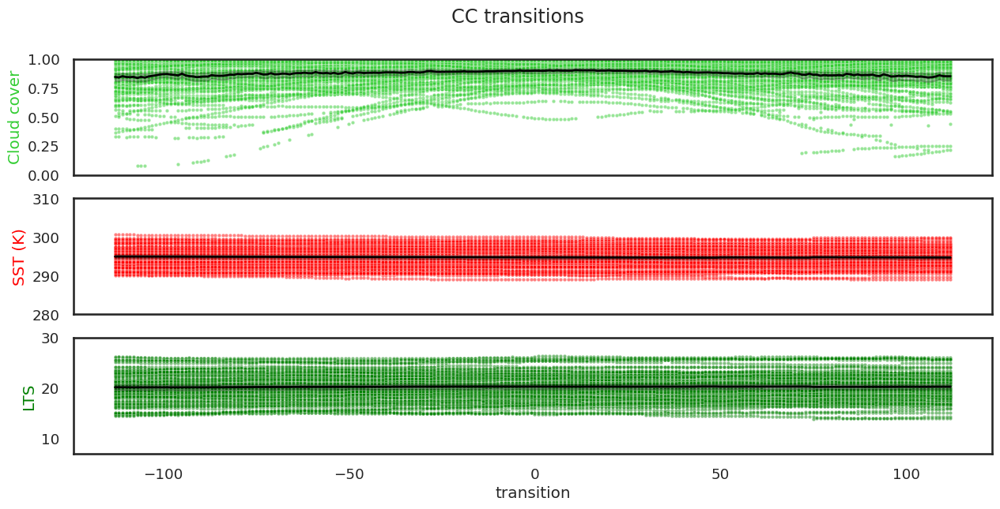

In [ ]:
fig, axs = plt.subplots(3,1, figsize=(15,6.5), sharex=True)
plt.suptitle('CC transitions')
ax=axs[0]
sns.scatterplot(ax=ax, data=dfall_trans_cc, x='transition', y='MCOP_cloud_cover_200', color='limegreen', s=10, alpha=0.5).set(ylim=(0,1))
sns.lineplot(ax=ax, data=dfall_trans_cc, x='transition', y='MCOP_cloud_cover_200', color='black', linewidth=2)
ax.set_ylabel('Cloud cover', color='limegreen')

ax=axs[1]
sns.scatterplot(ax=ax, data=dfall_trans_cc, x='transition', y='sea_surface_temperature', color='red', s=10, alpha=0.5).set(ylim=(280,310))
sns.lineplot(ax=ax, data=dfall_trans_cc, x='transition', y='sea_surface_temperature', color='black', linewidth=2)
ax.set_ylabel('SST (K)', color='red')

ax=axs[2]
sns.scatterplot(ax=ax, data=dfall_trans_cc, x='transition', y='lower_tropospheric_stability', color='green', s=10, alpha=0.5).set(ylim=(7,30))
sns.lineplot(ax=ax, data=dfall_trans_cc, x='transition', y='lower_tropospheric_stability', color='black', linewidth=2)
ax.set_ylabel('LTS', color='green')

### CD

In [ ]:
trans_cd = []
trans_dc = []
trans_cd_nonvalid = []
trans_dc_nonvalid = []
for _, dforbit in df.groupby('orbit_base'):
    dfscenes = dforbit.groupby('scene_id')[['orbit_base','orbit','scene_id','cats','cert','ice_flag','ocean_mask']].first()
    dfscenes['cats'] = np.where((dfscenes.cert > 0.75) & (dfscenes.ice_flag == 0) & (dfscenes.ocean_mask == 1), dfscenes.cats, -1) # (dfscenes.cert > 0.75) & 
    for i in range(1, len(dfscenes)-1):
        if (dfscenes.cats.iloc[i-1] == 1 and (dfscenes.cats.iloc[i] in [3,4])):
            if not dfscenes.cats.iloc[max(1,i-5) : i].isin([0,1,2,-1,6]).all(): # before the transiton there should be at least 5 consecutive scenes of cats = 0,1,2 (or uncertain)
                trans_cd_nonvalid.append(dfscenes.scene_id.iloc[i])
                continue
            if not dfscenes.cats.iloc[i : min(len(dfscenes), i+5)].isin([3,4,5,-1,6]).all(): # after the transition there should be at least 5 consecutive scenes of cats = 3,4,5 (or uncertain)
                trans_cd_nonvalid.append(dfscenes.scene_id.iloc[i])
                continue
            else:
                trans_cd.append(dfscenes.scene_id.iloc[i])
        elif ((dfscenes.cats.iloc[i-1] in [3,4]) and dfscenes.cats.iloc[i] == 1):
            if not dfscenes.cats.iloc[max(1,i-5) : i].isin([3,4,5,-1,6]).all():
                trans_dc_nonvalid.append(dfscenes.scene_id.iloc[i])
                continue
            if not dfscenes.cats.iloc[i : min(len(dfscenes), i+5)].isin([0,1,2,-1,6]).all(): 
                trans_dc_nonvalid.append(dfscenes.scene_id.iloc[i])
                continue
            else:
                trans_dc.append(dfscenes.scene_id.iloc[i])

Orbit 05897D
Transition 1 at scene_id 4089 at latitude 32.8596821934611





ValueError: Could not interpret value `MCOP_cloud_cover_200` for `y`. An entry with this name does not appear in `data`.

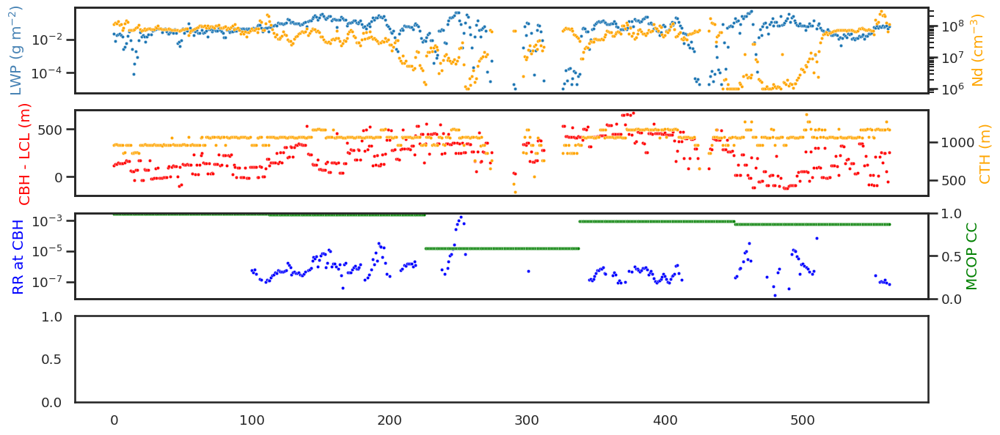

In [ ]:
from PIL import Image
for i in range(len(trans_cd)):

    orbit = df[df.scene_id == trans_cd[i]].orbit.iloc[0]
    lat = df[df.scene_id == trans_cd[i]].latitude.iloc[0]

    print(f'Orbit {orbit}')
    print(f'Transition {i+1} at scene_id {trans_cd[i]} at latitude {lat}')
    dforbit = df[df.orbit == orbit]
    df_trans_cd = dforbit[(dforbit.scene_id >= trans_cd[i]-5) & (df.scene_id <= trans_cd[i]+5)].reset_index(drop=True)

    img = glob.glob(f'./../figures_judge/judge_{orbit}_*.png'.format(orbit=orbit))[0]
    Image.open(img).show()
    
    fig, ax = plt.subplots(4,1, figsize=(15,7), sharex=True)
    sns.scatterplot(ax=ax[0], data=df_trans_cd[df_trans_cd['lwp']>0], x=df_trans_cd[df_trans_cd['lwp']>0].index, y='lwp', s=10).set(yscale='log')
    ax[0].set_ylabel('LWP (g m$^{-2}$)', color='steelblue')
    ax2 = ax[0].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_cd[df_trans_cd['lwp']>0], x=df_trans_cd[df_trans_cd['lwp']>0].index, y='Nd', color='orange', s=10).set(yscale='log')
    ax2.set_ylabel('Nd (cm$^{-3}$)', color='orange')
    
    sns.scatterplot(ax=ax[1], data=df_trans_cd, x=df_trans_cd.index, y='cbh_minus_lcl', color='red', s=10).set(ylim=(-200,700))
    ax[1].set_ylabel('CBH - LCL (m)', color='red')
    ax2=ax[1].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_cd, x=df_trans_cd.index, y='cth_m', color='orange', s=10)
    ax2.set_ylabel('CTH (m)', color='orange')

    sns.scatterplot(ax=ax[2], data=df_trans_cd[df_trans_cd['rain_rate_cbh']>0], x=df_trans_cd[df_trans_cd['rain_rate_cbh']>0].index, y='rain_rate_cbh', color='blue', s=10).set(yscale='log')
    ax[2].set_ylabel('RR at CBH', color='blue')
    ax2 = ax[2].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_cd, x=df_trans_cd.index, y='MCOP_cloud_cover_judge', color='green', s=10).set(ylim=(0,1))
    ax2.set_ylabel('MCOP CC', color='green')
    sns.scatterplot(ax=ax2, data=df_trans_cd, x=df_trans_cd.index, y='MCOP_cloud_cover_200', color='limegreen', s=10).set(ylim=(0,1))

    sns.scatterplot(ax=ax[3], data=df_trans_cd, x=df_trans_cd.index, y='lower_tropospheric_stability', color='green', s=10).set(ylim=(7,30))
    ax[3].set_ylabel('LTS', color='green')
    ax2 = ax[3].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_cd, x=df_trans_cd.index, y='sea_surface_temperature', color='red', s=10).set(ylim=(290,310))
    ax2.set_ylabel('SST', color='red')
    # vertical line at transition
    for a in ax:
        a.axvline(x=df_trans_cd[(df_trans_cd.scene_id == trans_cd[i])].index[0], color='gray', linestyle='--')
    plt.show()

In [ ]:
df[df.scene_id.isin(trans_cd)].orbit.unique()

array(['05897D', '06192E', '06233E', '06268E', '06342E', '06441D',
       '06591E', '06704E', '06799E', '06908E', '06980E', '07042E',
       '07058E', '07089E', '07110E'], dtype=object)

In [ ]:
df[df.scene_id.isin(trans_cd)].orbit.unique()

array(['05897D', '06192E', '06233E', '06268E', '06342E', '06441D',
       '06591E', '06704E', '06799E', '06908E', '06980E', '07042E',
       '07058E', '07089E', '07110E'], dtype=object)

In [ ]:
for i in range(len(trans_cd)):
    orbit = df[df.scene_id == trans_cd[i]].orbit.iloc[0]
    lat = df[df.scene_id == trans_cd[i]].latitude.mean()
    print(orbit, lat)

05897D 32.35019275658202
06192E 19.83940278803374
06233E -16.09533504753395
06268E -14.963523995258019
06342E -12.881682852365799
06441D 28.185138470579787
06591E -20.17174329372463
06704E -17.680984221948943
06799E 17.754811057446066
06908E 18.80042007757722
06980E -15.591624338762916
07042E -19.758448384720403
07058E -13.512601351388534
07089E -12.46806283682967
07110E 21.925136424643615


In [ ]:
# create a new dataframe combining all transitions
for i in range(len(trans_cd)):
    orbit = df[df.scene_id == trans_cd[i]].orbit.iloc[0]
    if orbit == '06575E': # skip this orbit, because the transition is at the very beginning and over land
        continue
    if orbit == '05897D': # C-O transition
        continue
    if orbit == '05850D': # C-O transition
        continue
    dforbit = df[df.orbit == orbit]
    print(f'Transition {i} at orbit {orbit} and scene_id {trans_cd[i]}')
    df_trans_cd = dforbit[(dforbit.scene_id >= trans_cd[i]-5) & (dforbit.scene_id <= trans_cd[i]+10)].reset_index(drop=True)
    # make a column for the index
    trans_index = df_trans_cd[(df_trans_cd.scene_id == trans_cd[i])].index[0]
    df_trans_cd['transition'] = df_trans_cd.index - trans_index
    if i == 0:
        dfall_trans_cd = df_trans_cd
    else:
        dfall_trans_cd = pd.concat([dfall_trans_cd, df_trans_cd], axis=0)
dfall_trans_cd.reset_index(inplace=True)

# same for OC transitions
#for i in range(len(trans_dc)):
#    print(f'Transition {i+1} at index {trans_dc[i]}')
#    df_trans_dc = df.loc[trans_dc[i] - 113 : trans_dc[i] + 112].reset_index(drop=True)
#    # make a column for the index: reverse the index in the same step
#    df_trans_dc['transition'] = df_trans_dc.index[::-1] - 113
#    
#    # now that the index is reversed, we can append the OC transitions to the CO transition dataframe
#    dfall_trans_cd = pd.concat([dfall_trans_cd, df_trans_dc], axis=0)
#dfall_trans_cd.reset_index(inplace=True)

Transition 1 at orbit 06192E and scene_id 4380


NameError: name 'dfall_trans_cd' is not defined

---

In [ ]:
# new method to find transitions, based on finding StCu regions first
# then checking if there are mainly disorganized or cumuliform clouds to the left or right of the StCu region
import scipy
trans_cd = pd.DataFrame(columns=['orbit_base', 'scene_id_trans', 'scene_id_stcu', 'cats_before_trans', 'cats_after_trans'])
trans_dc = pd.DataFrame(columns=['orbit_base', 'scene_id_trans', 'scene_id_stcu', 'cats_before_trans', 'cats_after_trans'])

# for debugging, keep track of orbits with StCu regions and if they have scenes to the left or right of the StCu region
orbits_with_stcu_regions = []
orbits_with_stcu_regions_and_scenes_to_right = []
orbits_with_stcu_regions_and_scenes_to_left = []

for orbit_base, dforbit in df.groupby('orbit_base'):
    
    dfscenes = dforbit.groupby('scene_id')[['orbit_base','orbit','scene_id','cats','cert','ice_flag','ocean_mask']].first()
    dfscenes['cats'] = np.where((dfscenes.cert > 0.5) & (dfscenes.ice_flag == 0) & (dfscenes.ocean_mask == 1), dfscenes.cats, -1) 

    # flag StCu regions, defined as at least 5 scenes of cats = 0,1,2 in a row
    dfscenes['stcu_cats'] = np.where(dfscenes.cats.isin([0,1,2]), 1, 0)
    # label stcu regions and get their sizes using scipy.ndimage
    stcu_regions, num_features = scipy.ndimage.label(dfscenes['stcu_cats'])
    # remove small regions < 4 consecutive scenes
    for i in range(1, num_features+1):
        region_indices = np.where(stcu_regions == i)[0]
        region_size = len(region_indices)
        if region_size < 4:
            stcu_regions[region_indices] = 0 
            num_features -= 1
    if num_features == 0:
        continue
    orbits_with_stcu_regions.append(orbit_base)
    print(f'Processing orbit {orbit_base}')

    # first index of rightmost stcu region
    start_idx_rightmost_stcu = np.where(stcu_regions == stcu_regions.max())[0][0]
    end_idx_rightmost_stcu = np.where(stcu_regions == stcu_regions.max())[0][-1]
    scenes_stcu = dfscenes.iloc[start_idx_rightmost_stcu : end_idx_rightmost_stcu + 1]
    scenes_right_of_stcu = dfscenes.iloc[end_idx_rightmost_stcu + 1: ]
    # check if there are mainly disorganized or cumuliform clouds to the right of the stcu region
    scenes_right_of_stcu_valid = scenes_right_of_stcu[scenes_right_of_stcu.cats != -1] # remove invalid scenes
    if len(scenes_right_of_stcu_valid) > 0:
        orbits_with_stcu_regions_and_scenes_to_right.append(orbit_base)
        # if at least 80% of the scenes to the right are cats = 3 or 4, mark transition
        print('to the right:', scenes_right_of_stcu_valid.cats.isin([3,4]).sum(), len(scenes_right_of_stcu_valid), scenes_right_of_stcu_valid.cats.isin([3,4]).sum() / len(scenes_right_of_stcu_valid), scenes_stcu['cats'].values, scenes_right_of_stcu['cats'].values)
        if (scenes_right_of_stcu_valid.cats.isin([3,4]).sum() >= 0.8 * len(scenes_right_of_stcu_valid)):
            #trans_cd.append(dfscenes.iloc[end_idx_rightmost_stcu].scene_id)
            print('--> transition')
            tmp = pd.DataFrame({
                'orbit_base': [orbit_base], 
                'scene_id_trans': [dfscenes.iloc[end_idx_rightmost_stcu].scene_id], 
                'scene_id_stcu': [dfscenes.iloc[start_idx_rightmost_stcu].scene_id], 
                'cats_before_trans': [scenes_stcu.cats.values],
                'cats_after_trans': [scenes_right_of_stcu.cats.values]
            })
            trans_cd = pd.concat([trans_cd, tmp], ignore_index=True)

    # last index of leftmost stcu region
    start_idx_leftmost_stcu = np.where(stcu_regions > 0)[0][0]
    end_idx_leftmost_stcu = np.where(stcu_regions > 0)[0][-1]
    scenes_stcu = dfscenes.iloc[start_idx_leftmost_stcu : end_idx_leftmost_stcu + 1]
    scenes_left_of_stcu = dfscenes.iloc[: start_idx_leftmost_stcu]
    # check if there are mainly disorganized or cumuliform clouds to the left of the stcu region
    scenes_left_of_stcu_valid = scenes_left_of_stcu[scenes_left_of_stcu.cats != -1] # remove invalid scenes
    if len(scenes_left_of_stcu_valid) > 0:
        orbits_with_stcu_regions_and_scenes_to_left.append(orbit_base)
        # if at least 80% of the scenes to the left are cats = 3 or 4, mark transition
        print('to the left', scenes_left_of_stcu_valid.cats.isin([3,4]).sum(), len(scenes_left_of_stcu_valid), scenes_left_of_stcu_valid.cats.isin([3,4]).sum() / len(scenes_left_of_stcu_valid), scenes_left_of_stcu['cats'].values, scenes_stcu['cats'].values)
        if (scenes_left_of_stcu_valid.cats.isin([3,4]).sum() >= 0.8 * len(scenes_left_of_stcu_valid)):
            #trans_dc.append(dfscenes.iloc[start_idx_leftmost_stcu].scene_id)
            print('--> transition')
            tmp = pd.DataFrame({
                'orbit_base': [orbit_base], 
                'scene_id_trans': [dfscenes.iloc[start_idx_leftmost_stcu].scene_id], 
                'scene_id_stcu': [dfscenes.iloc[end_idx_leftmost_stcu].scene_id], 
                'cats_before_trans': [scenes_left_of_stcu.cats.values],
                'cats_after_trans': [scenes_stcu.cats.values]
            })
            trans_dc = pd.concat([trans_dc, tmp], ignore_index=True)


Processing orbit 05735
to the left 0 10 0.0 [-1  5  5  5  5  5  5  1  5  5  5] [0 1 1 1 1 1]
Processing orbit 05741
to the right: 1 3 0.3333333333333333 [0 1 1 1 1 1 1 1 0 0 0] [-1 -1  0  5  3 -1]
Processing orbit 05766
to the right: 0 5 0.0 [1 1 1 1 1] [5 5 1 1 0]
to the left 0 4 0.0 [-1 -1  5  5  5  1 -1] [1 1 1 1 1]
Processing orbit 05770
Processing orbit 05772
to the right: 1 6 0.16666666666666666 [0 1 0 0 1 1] [ 3  0 -1  0  5  0  5]
to the left 2 4 0.5 [-1  5  5  3  3] [0 1 0 0 1 1]
Processing orbit 05788
Processing orbit 05797
to the left 2 7 0.2857142857142857 [-1  4  4  5  5  5  5  5] [1 1 1 1 1 0 1 1 1]
Processing orbit 05799
to the right: 0 1 0.0 [1 1 0 0 0 0 1] [ 5 -1]
to the left 2 4 0.5 [-1  4  5  4  5 -1 -1 -1 -1] [1 1 0 0 0 0 1]
Processing orbit 05801
to the right: 0 3 0.0 [0 0 0 1 0 0 1 1 1 0 0] [-1  0  0  0]
Processing orbit 05803
to the right: 1 4 0.25 [0 0 0 0 0 0 0 0 0 0 0 0] [3 0 0 0]
Processing orbit 05819
to the right: 4 8 0.5 [1 0 1 1 1 2 2] [ 3 -1  3  3 -1  3  

In [ ]:
len(orbits_with_stcu_regions_and_scenes_to_right)

103

In [ ]:
len(orbits_with_stcu_regions)

137

In [ ]:
trans_cd

,orbit_base,scene_id_trans,scene_id_stcu,cats_before_trans,cats_after_trans
0,05850,4042,4034,"[0, 0, 0, 0, 0]",[3]
1,05928,4148,4134,"[1, 0, 0, 1, 1, 1, 1, 1]","[-1, -1, 3, -1, 3, 3, 3, 3]"
2,05974,4249,4238,"[0, 0, 1, 1, 1, 0, 0]",[3]
3,06141,2898,2892,"[1, 1, 1, 1]","[4, 3, -1]"
4,06159,1735,1727,"[2, 2, 2, 2, 1]",[4]
5,06171,512,502,"[0, 1, 1, 1, 1, 1]","[-1, 4, 4, -1, 3]"
6,06192,4378,4358,"[0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1]","[4, -1, -1, -1]"
7,06206,1813,1807,"[2, 2, 2, 2]","[3, 4]"
8,06280,647,637,"[1, 1, 1, 1, 1, 1]","[-1, -1, -1, 4, 4, 3]"
9,06346,2033,2019,"[2, 2, 2, 2, 2, 2, 2, 2]","[3, 2, 4, 4, 4, 3, -1, -1]"


In [ ]:
trans_dc

,orbit_base,scene_id_trans,scene_id_stcu,cats_before_trans,cats_after_trans
0,05891,272,278,"[-1, 0, 3, 3, -1, 4, 3, 4, 4]","[1, 1, 1, 1]"
1,06359,3256,3266,"[-1, -1, 3, 3, 3]","[1, 1, 0, 1, 1, 1]"
2,06377,2095,2103,"[-1, 4, 3, 3, 3, 3, 3]","[0, 0, 2, 2, 2]"
3,06486,2255,2281,"[-1, 3, 3]","[1, 1, 1, 1, 2, 1, 2, 2, 1, 1, 1, 1, 1, 1]"
4,06735,6215,6239,"[-1, -1, 4, 4, 3, 3, 3]","[1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0]"
5,07030,6655,6661,"[-1, -1, 3, -1]","[1, 1, 1, 1]"
6,07046,6669,6685,"[-1, 3, 3, 4]","[1, 1, 2, 1, 1, 1, 1, 1, 1]"


Orbit_base 05850
Transition 1 at scene_id 4042 at latitude 18.275784249985882








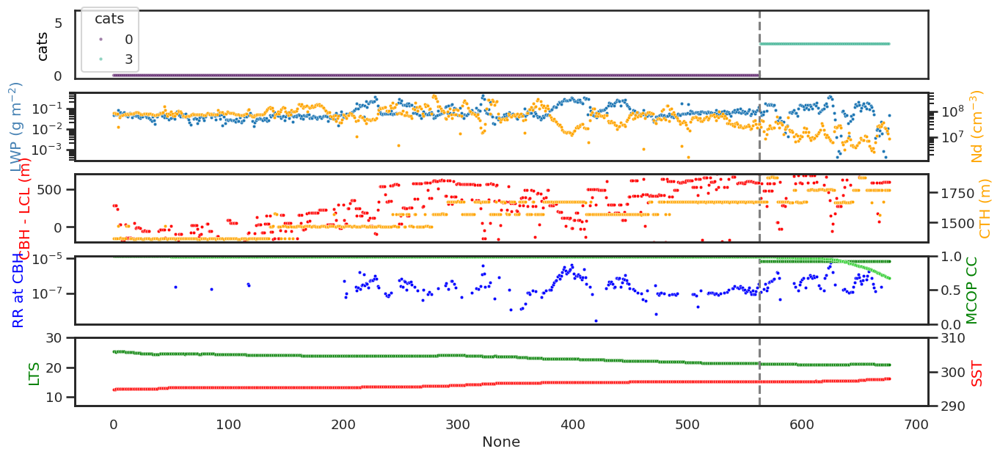

Orbit_base 05928
Transition 2 at scene_id 4148 at latitude 26.62094878421131








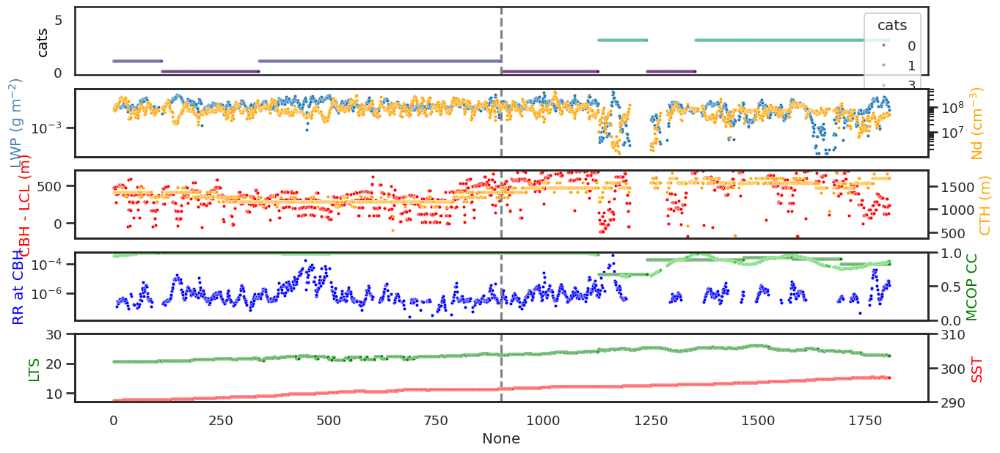

Orbit_base 05974
Transition 3 at scene_id 4249 at latitude 18.277383218976418








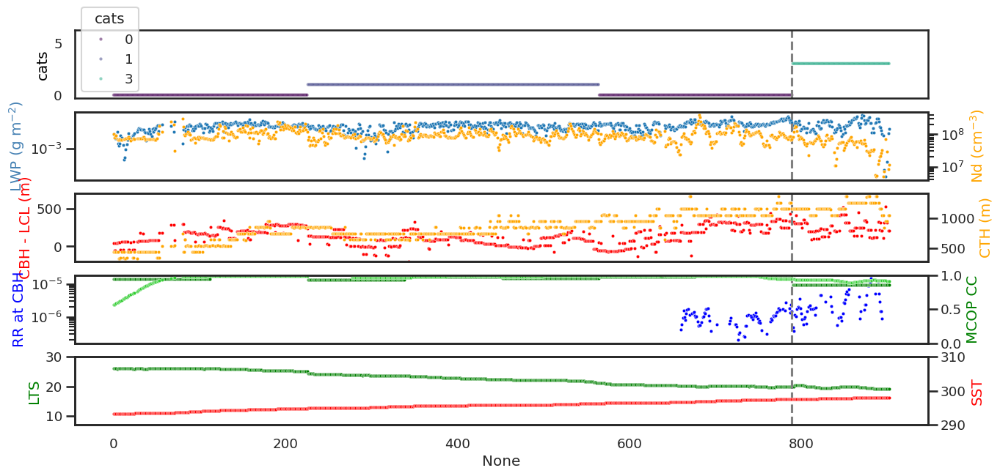

Orbit_base 06141
Transition 4 at scene_id 2898 at latitude 15.307737430227755





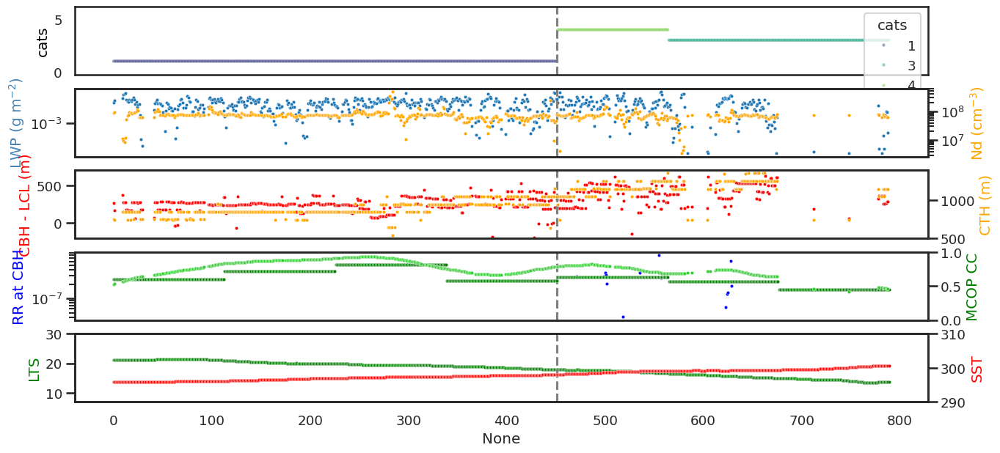

Orbit_base 06159
Transition 5 at scene_id 1735 at latitude -19.659856068205432





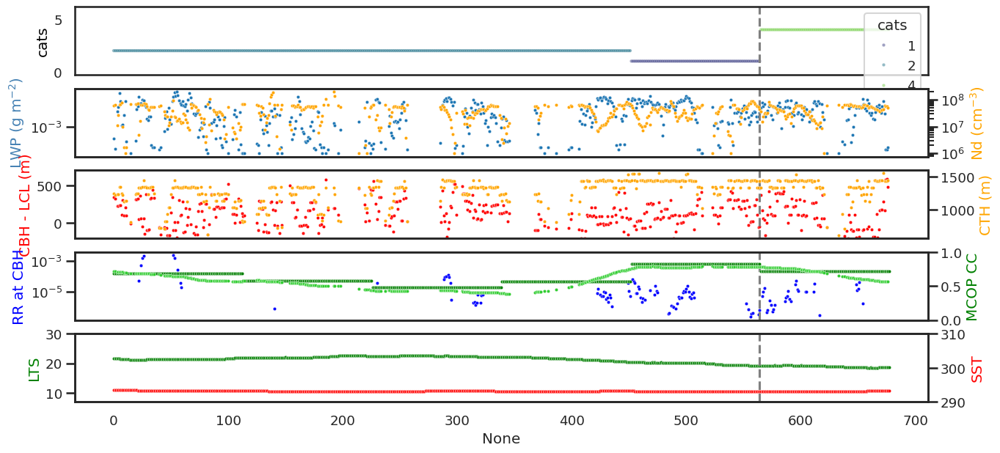

Orbit_base 06171
Transition 6 at scene_id 512 at latitude -15.487046127057488





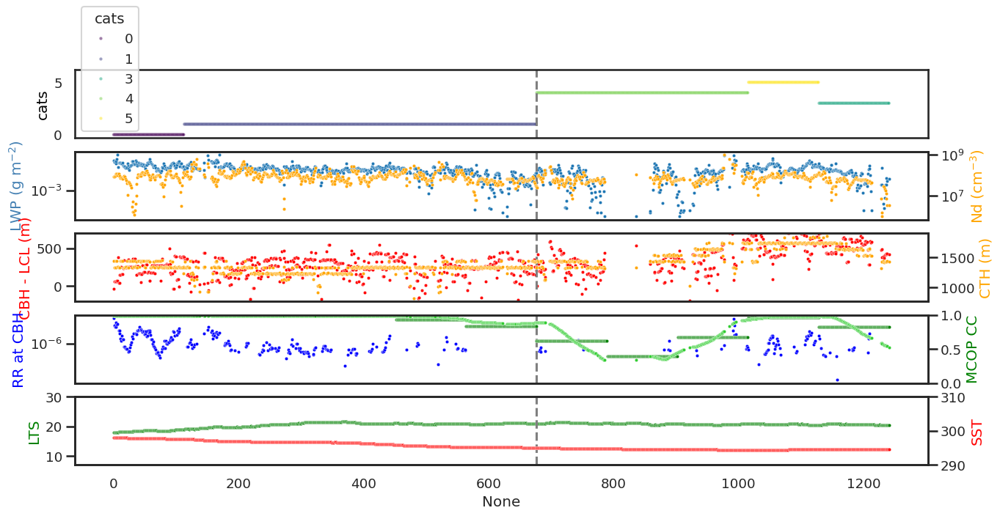

In [ ]:
from PIL import Image
for i in range(len(trans_cd)):

    orbit_base = trans_cd.loc[i, 'orbit_base']
    scene_id_trans = trans_cd.loc[i, 'scene_id_trans']
    lat = df[df.scene_id == scene_id_trans].latitude.iloc[0]

    print(f'Orbit_base {orbit_base}')
    print(f'Transition {i+1} at scene_id {trans_cd.loc[i, 'scene_id_trans']} at latitude {lat}')
    dforbit = df[df.orbit_base == orbit_base]
    df_trans_cd = dforbit[(dforbit.scene_id >= trans_cd.loc[i, 'scene_id_stcu'])].reset_index(drop=True)

    imgages = glob.glob(f'./../figures_judge/judge_{orbit_base}*_*.png'.format(orbit_base=orbit_base))
    for img in imgages:
        Image.open(img).show()

    fig, axs = plt.subplots(5,1, figsize=(15,7), sharex=True)

    ax=axs[0]
    sns.scatterplot(ax=ax, data=df_trans_cd, x=df_trans_cd.index, y='cats', hue='cats', palette=palette_catscolors, s=10, alpha=0.5).set(ylim=(-0.3,6.2))
    ax.set_ylabel('cats', color='black')
    
    ax=axs[1]
    sns.scatterplot(ax=ax, data=df_trans_cd[df_trans_cd['lwp']>0], x=df_trans_cd[df_trans_cd['lwp']>0].index, y='lwp', s=10).set(yscale='log')
    ax.set_ylabel('LWP (g m$^{-2}$)', color='steelblue')
    ax2 = ax.twinx()
    sns.scatterplot(ax=ax2, data=df_trans_cd[df_trans_cd['lwp']>0], x=df_trans_cd[df_trans_cd['lwp']>0].index, y='Nd', color='orange', s=10).set(yscale='log')
    ax2.set_ylabel('Nd (cm$^{-3}$)', color='orange')
    
    ax=axs[2]
    sns.scatterplot(ax=ax, data=df_trans_cd, x=df_trans_cd.index, y='cbh_minus_lcl', color='red', s=10).set(ylim=(-200,700))
    ax.set_ylabel('CBH - LCL (m)', color='red')
    ax2=ax.twinx()
    sns.scatterplot(ax=ax2, data=df_trans_cd, x=df_trans_cd.index, y='cth_m', color='orange', s=10)
    ax2.set_ylabel('CTH (m)', color='orange')
    
    ax=axs[3]
    sns.scatterplot(ax=ax, data=df_trans_cd[df_trans_cd['rain_rate_cbh']>0], x=df_trans_cd[df_trans_cd['rain_rate_cbh']>0].index, y='rain_rate_cbh', color='blue', s=10).set(yscale='log')
    ax.set_ylabel('RR at CBH', color='blue')
    ax2 = ax.twinx()
    sns.scatterplot(ax=ax2, data=df_trans_cd, x=df_trans_cd.index, y='MCOP_cloud_cover_judge', color='green', s=10).set(ylim=(0,1))
    ax2.set_ylabel('MCOP CC', color='green')
    sns.scatterplot(ax=ax2, data=df_trans_cd, x=df_trans_cd.index, y='MCOP_cloud_cover_256', color='limegreen', s=10).set(ylim=(0,1))

    ax=axs[4]
    sns.scatterplot(ax=ax, data=df_trans_cd, x=df_trans_cd.index, y='lower_tropospheric_stability', color='green', s=10).set(ylim=(7,30))
    ax.set_ylabel('LTS', color='green')
    ax2 = ax.twinx()
    sns.scatterplot(ax=ax2, data=df_trans_cd, x=df_trans_cd.index, y='sea_surface_temperature', color='red', s=10).set(ylim=(290,310))
    ax2.set_ylabel('SST', color='red')
    # vertical line at transition
    for ax in axs:
        ax.axvline(x=df_trans_cd[(df_trans_cd.scene_id == scene_id_trans)].index[-1], color='gray', linestyle='--')
    plt.show()

    if i == 5:
        break

Orbit 05891E
Transition 1 at scene_id 272 at latitude -13.403429205811737





KeyError: 0

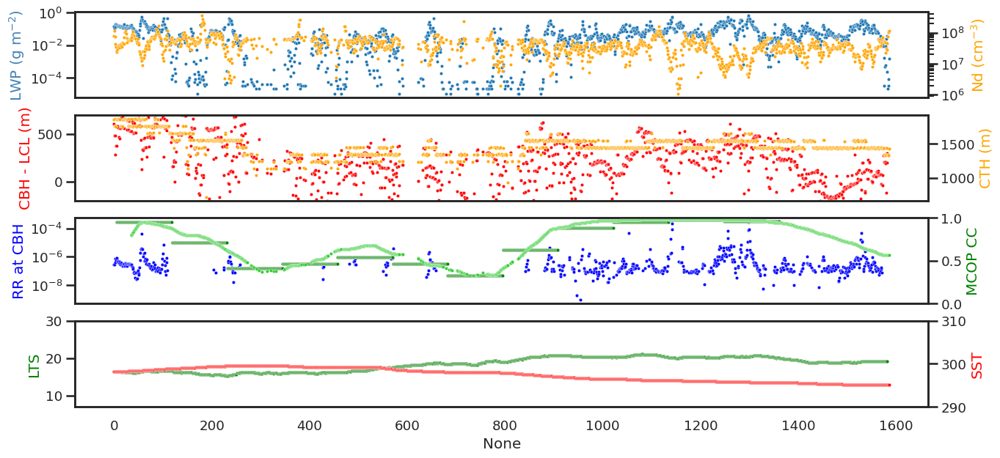

In [ ]:
from PIL import Image
for i in range(len(trans_dc)):
    orbit = trans_dc.loc[i, 'orbit']
    scene_id_trans = trans_dc.loc[i, 'scene_id_trans']
    lat = df[df.scene_id == scene_id_trans].latitude.iloc[0]

    print(f'Orbit {orbit}')
    print(f'Transition {i+1} at scene_id {trans_dc.loc[i, 'scene_id_trans']} at latitude {lat}')
    dforbit = df[df.orbit == orbit]
    df_trans_dc = dforbit[(dforbit.scene_id <= trans_dc.loc[i, 'scene_id_stcu'])].reset_index(drop=True)

    img = glob.glob(f'./../figures_judge/judge_{orbit}_*.png'.format(orbit=orbit))[0]
    Image.open(img).show()
    
    fig, ax = plt.subplots(4,1, figsize=(15,7), sharex=True)
    sns.scatterplot(ax=ax[0], data=df_trans_dc[df_trans_dc['lwp']>0], x=df_trans_dc[df_trans_dc['lwp']>0].index, y='lwp', s=10).set(yscale='log')
    ax[0].set_ylabel('LWP (g m$^{-2}$)', color='steelblue')
    ax2 = ax[0].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_dc[df_trans_dc['lwp']>0], x=df_trans_dc[df_trans_dc['lwp']>0].index, y='Nd', color='orange', s=10).set(yscale='log')
    ax2.set_ylabel('Nd (cm$^{-3}$)', color='orange')
    
    sns.scatterplot(ax=ax[1], data=df_trans_dc, x=df_trans_dc.index, y='cbh_minus_lcl', color='red', s=10).set(ylim=(-200,700))
    ax[1].set_ylabel('CBH - LCL (m)', color='red')
    ax2=ax[1].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_dc, x=df_trans_dc.index, y='cth_m', color='orange', s=10)
    ax2.set_ylabel('CTH (m)', color='orange')

    sns.scatterplot(ax=ax[2], data=df_trans_dc[df_trans_dc['rain_rate_cbh']>0], x=df_trans_dc[df_trans_dc['rain_rate_cbh']>0].index, y='rain_rate_cbh', color='blue', s=10).set(yscale='log')
    ax[2].set_ylabel('RR at CBH', color='blue')
    ax2 = ax[2].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_dc, x=df_trans_dc.index, y='MCOP_cloud_cover_judge', color='green', s=10).set(ylim=(0,1))
    ax2.set_ylabel('MCOP CC', color='green')
    sns.scatterplot(ax=ax2, data=df_trans_dc, x=df_trans_dc.index, y='MCOP_cloud_cover_256', color='limegreen', s=10).set(ylim=(0,1))

    sns.scatterplot(ax=ax[3], data=df_trans_dc, x=df_trans_dc.index, y='lower_tropospheric_stability', color='green', s=10).set(ylim=(7,30))
    ax[3].set_ylabel('LTS', color='green')
    ax2 = ax[3].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_dc, x=df_trans_dc.index, y='sea_surface_temperature', color='red', s=10).set(ylim=(290,310))
    ax2.set_ylabel('SST', color='red')
    # vertical line at transition
    for a in ax:
        a.axvline(x=df_trans_dc[(df_trans_dc.scene_id == scene_id_trans)].index[-1], color='gray', linestyle='--')
    plt.show()

In [ ]:
# create a new dataframe combining all transitions
for i in range(len(trans_cd)):

    orbit_base = trans_cd.loc[i, 'orbit_base']
    scene_id_trans = trans_cd.loc[i, 'scene_id_trans']
    scene_id_stcu = trans_cd.loc[i, 'scene_id_stcu']
    lat = df[df.scene_id == scene_id_trans].latitude.iloc[0]

    print(f'Orbit_base {orbit_base}')
    print(f'Transition {i+1} at scene_id {trans_cd.loc[i, 'scene_id_trans']} at latitude {lat}')
    dforbit = df[df.orbit_base == orbit_base]
    df_trans_cd = dforbit[(dforbit.scene_id >= scene_id_stcu)].reset_index(drop=True)

    # make a column for the index
    trans_index = df_trans_cd[(df_trans_cd.scene_id == scene_id_trans)].index[-1]
    df_trans_cd['transition'] = df_trans_cd.index - trans_index
    df_trans_cd['transition_id'] = i
    if i == 0:
        dfall_trans_cd = df_trans_cd
    else:
        dfall_trans_cd = pd.concat([dfall_trans_cd, df_trans_cd], axis=0)
dfall_trans_cd.reset_index(inplace=True)

Orbit_base 05850
Transition 1 at scene_id 4042 at latitude 18.275784249985882
Orbit_base 05928
Transition 2 at scene_id 4148 at latitude 26.62094878421131
Orbit_base 05974
Transition 3 at scene_id 4249 at latitude 18.277383218976418
Orbit_base 06141
Transition 4 at scene_id 2898 at latitude 15.307737430227755
Orbit_base 06159
Transition 5 at scene_id 1735 at latitude -19.659856068205432
Orbit_base 06171
Transition 6 at scene_id 512 at latitude -15.487046127057488
Orbit_base 06192
Transition 7 at scene_id 4378 at latitude 21.399999595850222
Orbit_base 06206
Transition 8 at scene_id 1813 at latitude -18.61163257380886
Orbit_base 06280
Transition 9 at scene_id 647 at latitude -10.269715547406529
Orbit_base 06346
Transition 10 at scene_id 2033 at latitude -12.359855757301832
Orbit_base 06348
Transition 11 at scene_id 4649 at latitude 20.355979430217054
Orbit_base 06377
Transition 12 at scene_id 2103 at latitude -15.488627172710322
Orbit_base 06379
Transition 13 at scene_id 4702 at latitude

In [ ]:
dfall_trans_cd

,level_0,index,along_track,time,latitude,longitude,stratus_region_index,lwp,ER,ER_passive_perspective,...,MCOP_cwp_inhomogeneity_judge_1,ocean_mask,cats,cert,scene_id,ice_flag,MCOP_cloud_cover_judge,orbit_base,transition,transition_id
0,0,505017,15,2025-06-08 22:41:40.144052480,22.440415,-128.305392,3,0.048002,0.000008,0.000009,...,-1.0,True,0,0.668946,4034,0.000000,0.999939,05850,-563,0
1,1,505018,16,2025-06-08 22:41:40.279988352,22.431629,-128.307217,3,0.051033,0.000008,0.000009,...,-1.0,True,0,0.668946,4034,0.000000,0.999939,05850,-562,0
2,2,505019,17,2025-06-08 22:41:40.415924352,22.422844,-128.309041,3,0.051083,0.000009,0.000010,...,-1.0,True,0,0.668946,4034,0.000000,0.999939,05850,-561,0
3,3,505020,18,2025-06-08 22:41:40.551862400,22.414058,-128.310865,3,0.052783,0.000009,0.000010,...,-1.0,True,0,0.668946,4034,0.000000,0.999939,05850,-560,0
4,4,505021,19,2025-06-08 22:41:40.736252800,22.402140,-128.313338,3,0.080630,0.000010,0.000012,...,-1.0,True,0,0.668946,4034,0.000000,0.999939,05850,-559,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36678,1688,219346,4857,2025-08-31 19:43:31.644929152,-22.326833,-89.689277,2,0.006571,0.000005,0.000005,...,-1.0,True,3,0.957699,6914,0.011719,0.827515,07155,1125,27
36679,1689,219347,4858,2025-08-31 19:43:31.782063360,-22.335681,-89.691115,2,0.006328,0.000005,0.000007,...,-1.0,True,3,0.957699,6914,0.011719,0.827515,07155,1126,27
36680,1690,219348,4859,2025-08-31 19:43:31.919203328,-22.344528,-89.692953,2,0.013514,0.000010,0.000010,...,-1.0,True,3,0.957699,6914,0.011719,0.827515,07155,1127,27
36681,1691,219349,4860,2025-08-31 19:43:32.056346240,-22.353375,-89.694790,2,0.013129,0.000009,0.000010,...,-1.0,True,3,0.957699,6914,0.011719,0.827515,07155,1128,27


<Axes: title={'center': 'StCu -> disorg. MCC / Cu transitions'}, xlabel='longitude', ylabel='latitude'>

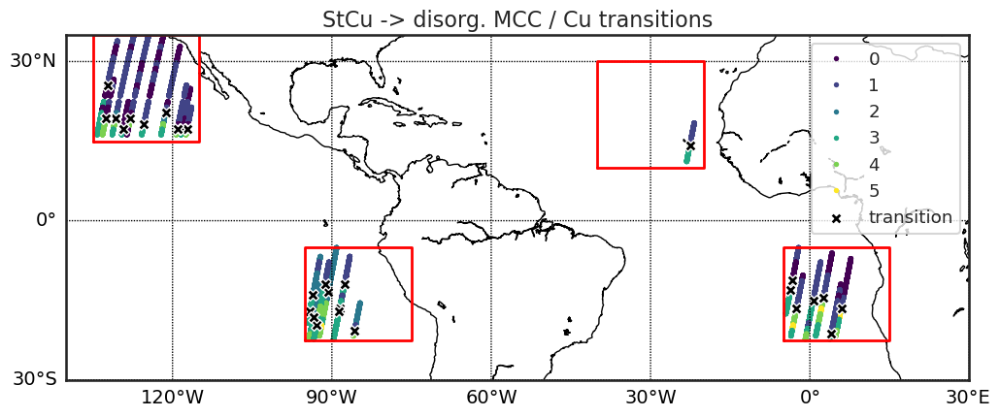

<Figure size 2000x800 with 0 Axes>

In [ ]:
# global map with 4 rectangles for stratus regions 
fig, ax = plt.subplots(figsize=(12, 6))
b = bmap(ax=ax, llr={'lat': (-30, 35), 'lon': (-140, 30)}, merspace=30, parspace=30)
for sr in stratus_region_names.values():
    llr = stratus_regions[sr]
    lats = [llr['lat'][0], llr['lat'][0], llr['lat'][1], llr['lat'][1], llr['lat'][0]]
    lons = [llr['lon'][0], llr['lon'][1], llr['lon'][1], llr['lon'][0], llr['lon'][0]]
    x, y = b(lons, lats)
    b.plot(x, y, marker=None, color='red', linewidth=2)
ax.set_title('StCu -> disorg. MCC / Cu transitions', fontsize=16)

plt.figure(figsize=(20,8))
sns.scatterplot(ax=ax, data=dfall_trans_cd, x='longitude', y='latitude', hue='cats', palette=catcolors, lw=0, s=15)
sns.scatterplot(ax=ax, data=dfall_trans_cd[dfall_trans_cd.transition == 0], x='longitude', y='latitude', color='black', lw=1, s=70, marker='X', label='transition')

<Axes: title={'center': 'StCu -> disorg. MCC / Cu transitions'}, xlabel='longitude', ylabel='latitude'>

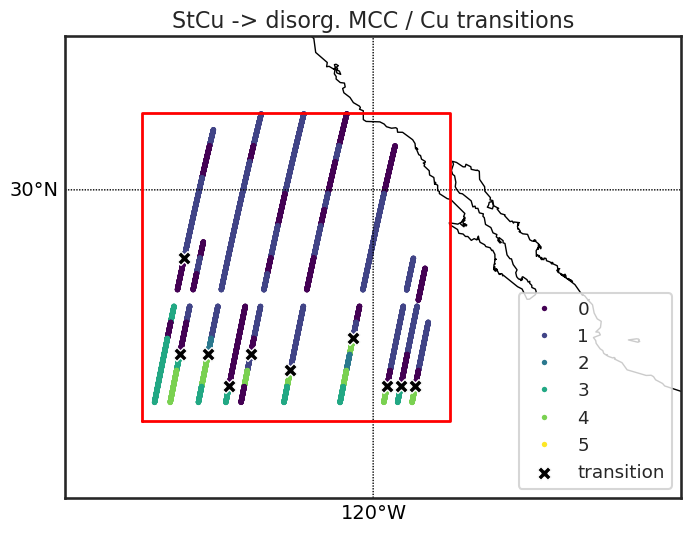

<Figure size 2000x800 with 0 Axes>

In [ ]:
# global map with 4 rectangles for stratus regions 
fig, ax = plt.subplots(figsize=(12, 6))
b = bmap(ax=ax, llr={'lat': (10, 40), 'lon': (-140, -100)}, merspace=30, parspace=30)
for sr in stratus_region_names.values():
    llr = stratus_regions[sr]
    lats = [llr['lat'][0], llr['lat'][0], llr['lat'][1], llr['lat'][1], llr['lat'][0]]
    lons = [llr['lon'][0], llr['lon'][1], llr['lon'][1], llr['lon'][0], llr['lon'][0]]
    x, y = b(lons, lats)
    b.plot(x, y, marker=None, color='red', linewidth=2)
ax.set_title('StCu -> disorg. MCC / Cu transitions', fontsize=16)

plt.figure(figsize=(20,8))
sns.scatterplot(ax=ax, data=dfall_trans_cd, x='longitude', y='latitude', hue='cats', palette=catcolors, lw=0, s=15)
sns.scatterplot(ax=ax, data=dfall_trans_cd[dfall_trans_cd.transition == 0], x='longitude', y='latitude', color='black', lw=1, s=100, marker='X', label='transition')

In [ ]:
dfall_trans_cd['cth_m_113'] = dfall_trans_cd.groupby(['orbit', 'scene_id'])['cth_m'].transform(lambda x: np.nanmean(x))
dfall_trans_cd['cbh_minus_lcl_113'] = dfall_trans_cd.groupby(['orbit', 'scene_id'])['cbh_minus_lcl'].transform(lambda x: np.nanmean(x))
dfall_trans_cd['cbh_max_minus_min_113'] = dfall_trans_cd.groupby(['orbit', 'scene_id'])['cbh_m'].transform(lambda x: np.nanmax(x) - np.nanmin(x))
dfall_trans_cd['lwp_113'] = dfall_trans_cd.groupby(['orbit', 'scene_id'])['lwp'].transform(lambda x: np.nanmean(x))
dfall_trans_cd['rain_rate_cbh_113'] = dfall_trans_cd.groupby(['orbit', 'scene_id'])['rain_rate_cbh'].transform(lambda x: np.nanmean(x))
dfall_trans_cd['rain_rate_cbh_everywhere_113'] = dfall_trans_cd.groupby(['orbit', 'scene_id'])['rain_rate_cbh'].transform(lambda x: np.mean(x.fillna(0)))

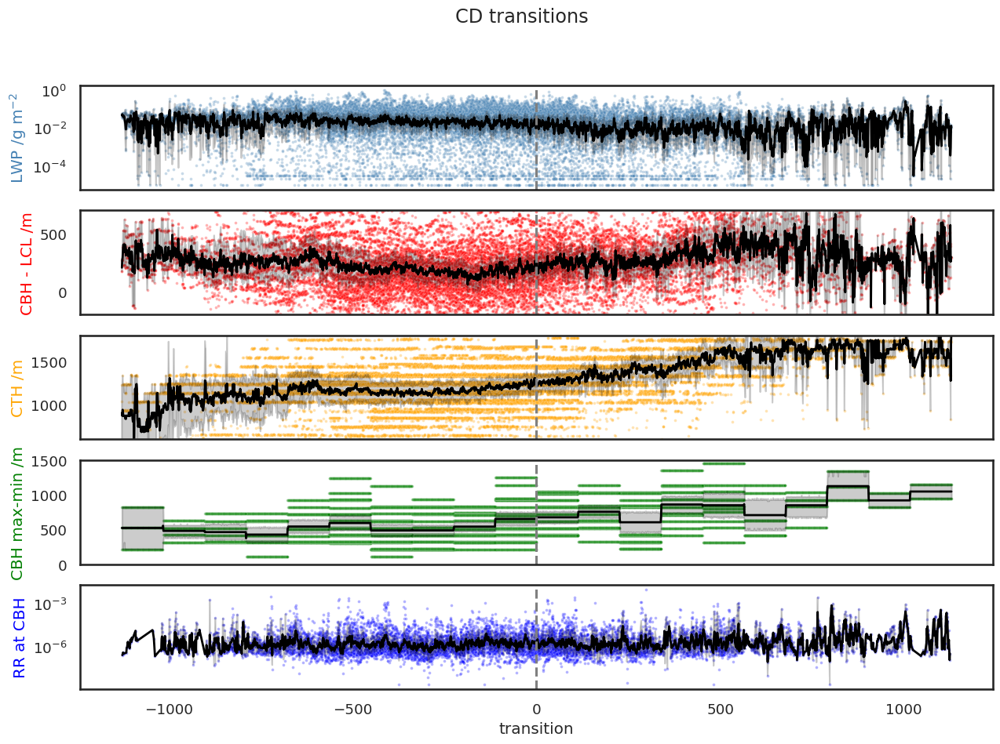

In [ ]:
fig, axs = plt.subplots(5,1, figsize=(15,10), sharex=True)
plt.suptitle('CD transitions')
ax=axs[0]
sns.scatterplot(ax=ax, data=dfall_trans_cd[dfall_trans_cd['lwp']>0], x='transition', y='lwp', color='steelblue', s=7, alpha=0.3).set(yscale='log')
sns.lineplot(ax=ax, data=dfall_trans_cd[dfall_trans_cd['lwp']>0], x='transition', y='lwp', color='black', linewidth=2)
ax.set_ylabel('LWP /g m$^{-2}$', color='steelblue')

ax=axs[1]
sns.scatterplot(ax=ax, data=dfall_trans_cd, x='transition', y='cbh_minus_lcl', color='red', s=7, alpha=0.3).set(ylim=(-200,700))
sns.lineplot(ax=ax, data=dfall_trans_cd, x='transition', y='cbh_minus_lcl', color='black', linewidth=2)
ax.set_ylabel('CBH - LCL /m', color='red')

#ax=axs[2]
#sns.scatterplot(ax=ax, data=dfall_trans_cd, x='transition', y='coupled_fraction', color='red', s=7, alpha=0.3).set(ylim=(-0.1,1.1))
#sns.lineplot(ax=ax, data=dfall_trans_cd, x='transition', y='coupled_fraction', color='black', linewidth=2)
#ax.set_ylabel('Coupled Fraction', color='red')

ax=axs[2]
sns.scatterplot(ax=ax, data=dfall_trans_cd, x='transition', y='cth_m', color='orange', s=7, alpha=0.3).set(ylim=(600,1800))
sns.lineplot(ax=ax, data=dfall_trans_cd, x='transition', y='cth_m', color='black', linewidth=2)
ax.set_ylabel('CTH /m', color='orange')

ax=axs[3]
sns.scatterplot(ax=ax, data=dfall_trans_cd, x='transition', y='cbh_max_minus_min_113', color='green', s=7, alpha=0.3).set(ylim=(0,1500))
sns.lineplot(ax=ax, data=dfall_trans_cd, x='transition', y='cbh_max_minus_min_113', color='black', linewidth=2)
ax.set_ylabel('CBH max-min /m', color='green')
#sns.scatterplot(ax=ax, data=dfall_trans_cd, x='transition', y='multilayer', color='red', s=7, alpha=0.3).set(ylim=(-0.1,1.1))
#sns.lineplot(ax=ax, data=dfall_trans_cd, x='transition', y='multilayer', color='black', linewidth=2)
#ax.set_ylabel('Multilayer', color='red')

ax=axs[4]
sns.scatterplot(ax=ax, data=dfall_trans_cd[dfall_trans_cd['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='blue', s=7, alpha=0.3).set(yscale='log')
sns.lineplot(ax=ax, data=dfall_trans_cd[dfall_trans_cd['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='black', linewidth=2)
ax.set_ylabel('RR at CBH', color='blue')

for ax in axs:
    ax.axvline(x=0, color='gray', linestyle='--')
plt.show()

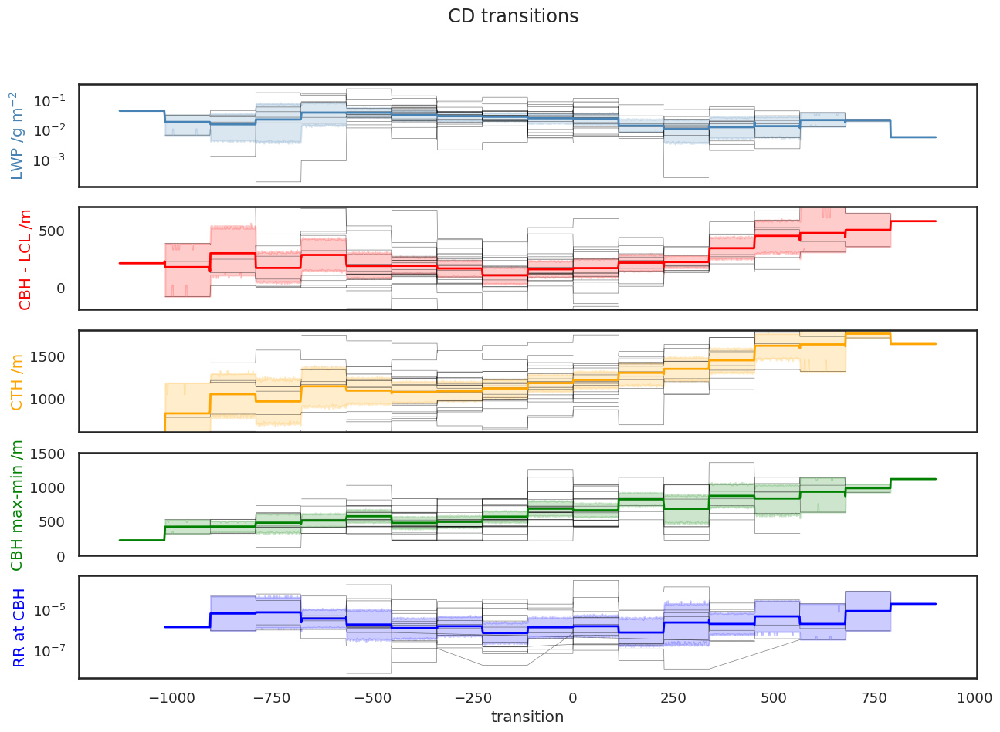

In [ ]:
fig, axs = plt.subplots(5,1, figsize=(15,10), sharex=True)
plt.suptitle('CD transitions')
for i in dfall_trans_cd.transition_id.unique():
    df_tmp = dfall_trans_cd[dfall_trans_cd['transition_id'] == i]
    ax=axs[0]
    sns.lineplot(ax=ax, data=df_tmp[df_tmp['lwp_113']>0], x='transition', y='lwp_113', color='black', linewidth=0.8, alpha=0.5).set(yscale='log')
    ax.set_ylabel('LWP /g m$^{-2}$', color='steelblue')

    ax=axs[1]
    sns.lineplot(ax=ax, data=df_tmp, x='transition', y='cbh_minus_lcl_113', color='black', linewidth=0.8, alpha=0.5).set(ylim=(-200,700))
    ax.set_ylabel('CBH - LCL /m', color='red')

    ax=axs[2]
    sns.lineplot(ax=ax, data=df_tmp, x='transition', y='cth_m_113', color='black', linewidth=0.8, alpha=0.5).set(ylim=(600,1800))
    ax.set_ylabel('CTH /m', color='orange')

    ax=axs[3]
    sns.lineplot(ax=ax, data=df_tmp, x='transition', y='cbh_max_minus_min_113', color='black', linewidth=0.8, alpha=0.5).set(ylim=(0,1500))
    ax.set_ylabel('CBH max-min /m', color='green')

    ax=axs[4]
    sns.lineplot(ax=ax, data=df_tmp[df_tmp['rain_rate_cbh_113']>0], x='transition', y='rain_rate_cbh_113', color='black', linewidth=0.8, alpha=0.5).set(yscale='log')
    ax.set_ylabel('RR at CBH', color='blue')

sns.lineplot(ax=axs[0], data=dfall_trans_cd[dfall_trans_cd['lwp_113']>0], x='transition', y='lwp_113', color='steelblue', linewidth=2)
sns.lineplot(ax=axs[1], data=dfall_trans_cd, x='transition', y='cbh_minus_lcl_113', color='red', linewidth=2)
sns.lineplot(ax=axs[2], data=dfall_trans_cd, x='transition', y='cth_m_113', color='orange', linewidth=2)
sns.lineplot(ax=axs[3], data=dfall_trans_cd, x='transition', y='cbh_max_minus_min_113', color='green', linewidth=2)
sns.lineplot(ax=axs[4], data=dfall_trans_cd[dfall_trans_cd['rain_rate_cbh_113']>0], x='transition', y='rain_rate_cbh_113', color='blue', linewidth=2)
plt.show()

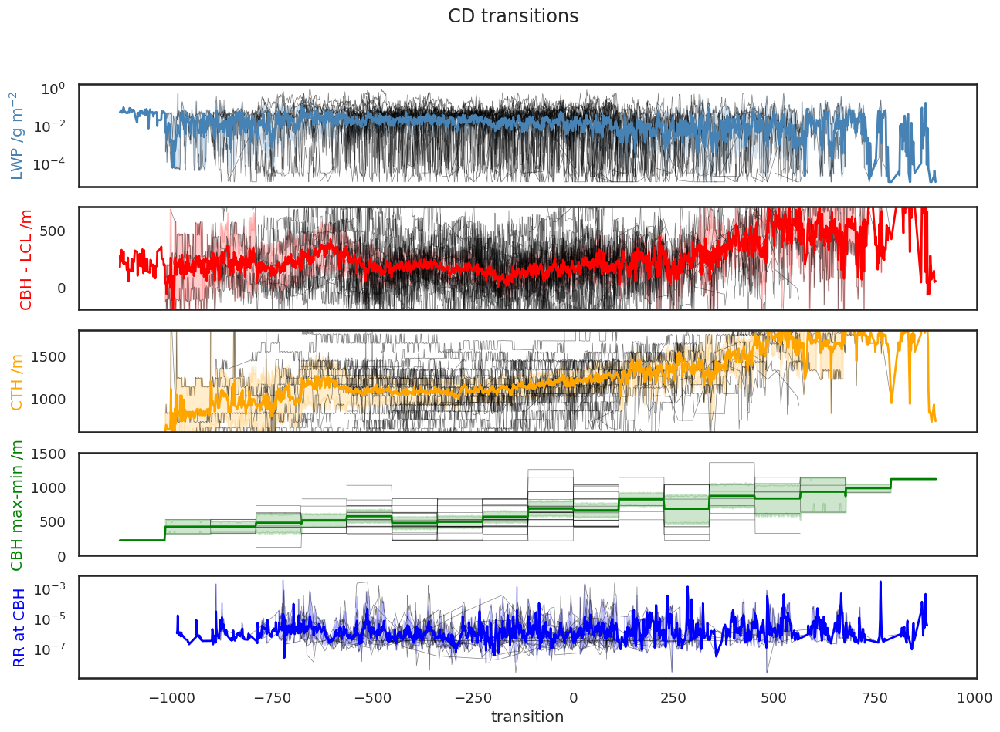

In [ ]:
fig, axs = plt.subplots(5,1, figsize=(15,10), sharex=True)
plt.suptitle('CD transitions')
for i in dfall_trans_cd.transition_id.unique():
    df_tmp = dfall_trans_cd[dfall_trans_cd['transition_id'] == i]
    ax=axs[0]
    sns.lineplot(ax=ax, data=df_tmp[df_tmp['lwp']>0], x='transition', y='lwp', color='black', linewidth=0.5, alpha=0.5).set(yscale='log')
    ax.set_ylabel('LWP /g m$^{-2}$', color='steelblue')

    ax=axs[1]
    sns.lineplot(ax=ax, data=df_tmp, x='transition', y='cbh_minus_lcl', color='black', linewidth=0.5, alpha=0.5).set(ylim=(-200,700))
    ax.set_ylabel('CBH - LCL /m', color='red')

    ax=axs[2]
    sns.lineplot(ax=ax, data=df_tmp, x='transition', y='cth_m', color='black', linewidth=0.5, alpha=0.5).set(ylim=(600,1800))
    ax.set_ylabel('CTH /m', color='orange')

    ax=axs[3]
    sns.lineplot(ax=ax, data=df_tmp, x='transition', y='cbh_max_minus_min_113', color='black', linewidth=0.5, alpha=0.5).set(ylim=(0,1500))
    ax.set_ylabel('CBH max-min /m', color='green')

    ax=axs[4]
    sns.lineplot(ax=ax, data=df_tmp[df_tmp['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='black', linewidth=0.5, alpha=0.5).set(yscale='log')
    ax.set_ylabel('RR at CBH', color='blue')

sns.lineplot(ax=axs[0], data=dfall_trans_cd[dfall_trans_cd['lwp']>0], x='transition', y='lwp', color='steelblue', linewidth=2)
sns.lineplot(ax=axs[1], data=dfall_trans_cd, x='transition', y='cbh_minus_lcl', color='red', linewidth=2)
sns.lineplot(ax=axs[2], data=dfall_trans_cd, x='transition', y='cth_m', color='orange', linewidth=2)
sns.lineplot(ax=axs[3], data=dfall_trans_cd, x='transition', y='cbh_max_minus_min_113', color='green', linewidth=2)
sns.lineplot(ax=axs[4], data=dfall_trans_cd[dfall_trans_cd['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='blue', linewidth=2)
plt.show()

Text(0, 0.5, 'LTS')

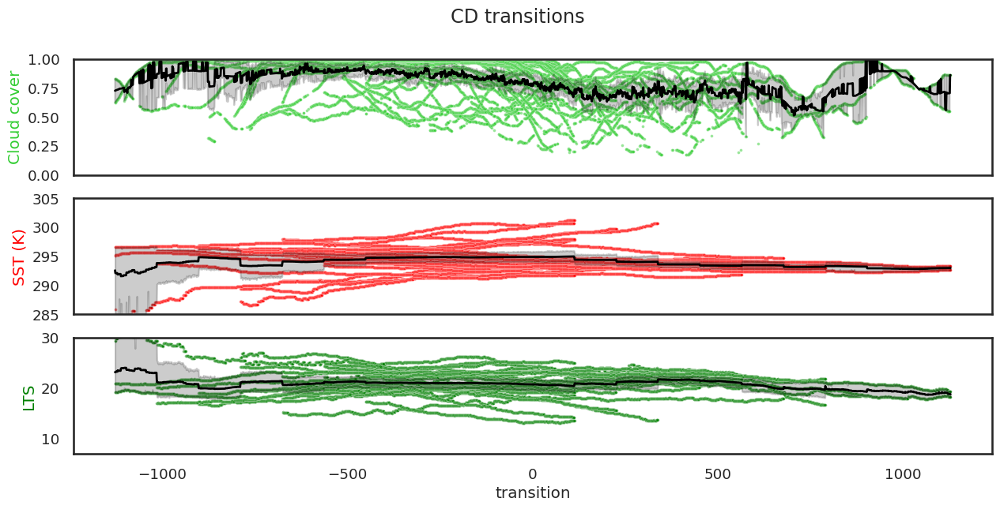

In [ ]:
fig, axs = plt.subplots(3,1, figsize=(15,6.5), sharex=True)
plt.suptitle('CD transitions')
ax=axs[0]
sns.scatterplot(ax=ax, data=dfall_trans_cd, x='transition', y='MCOP_cloud_cover_256', color='limegreen', s=7, alpha=0.5).set(ylim=(0,1))
sns.lineplot(ax=ax, data=dfall_trans_cd, x='transition', y='MCOP_cloud_cover_256', color='black', linewidth=2)
ax.set_ylabel('Cloud cover', color='limegreen')

ax=axs[1]
sns.scatterplot(ax=ax, data=dfall_trans_cd, x='transition', y='sea_surface_temperature', color='red', s=7, alpha=0.5).set(ylim=(285,305))
sns.lineplot(ax=ax, data=dfall_trans_cd, x='transition', y='sea_surface_temperature', color='black', linewidth=2)
ax.set_ylabel('SST (K)', color='red')

ax=axs[2]
sns.scatterplot(ax=ax, data=dfall_trans_cd, x='transition', y='lower_tropospheric_stability', color='green', s=7, alpha=0.5).set(ylim=(7,30))
sns.lineplot(ax=ax, data=dfall_trans_cd, x='transition', y='lower_tropospheric_stability', color='black', linewidth=2)
ax.set_ylabel('LTS', color='green')

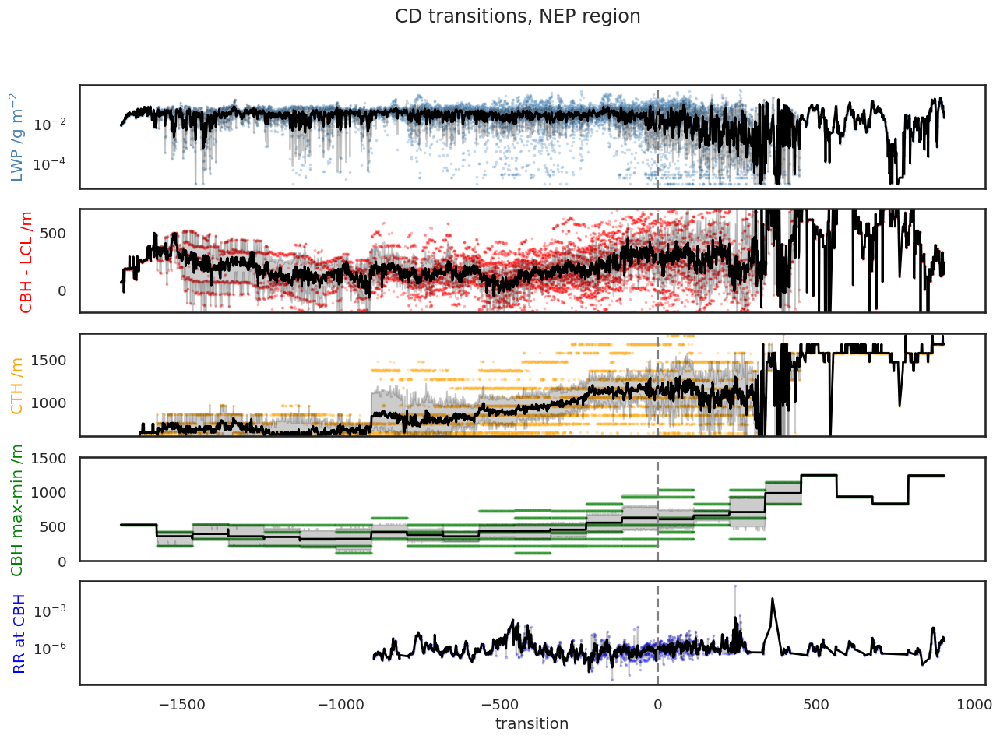

In [ ]:
dfall_trans_cd_NEP = dfall_trans_cd[dfall_trans_cd['stratus_region_index'] == 3]

fig, axs = plt.subplots(5,1, figsize=(15,10), sharex=True)
plt.suptitle('CD transitions, NEP region')
ax=axs[0]
sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP[dfall_trans_cd_NEP['lwp']>0], x='transition', y='lwp', color='steelblue', s=7, alpha=0.3).set(yscale='log')
sns.lineplot(ax=ax, data=dfall_trans_cd_NEP[dfall_trans_cd_NEP['lwp']>0], x='transition', y='lwp', color='black', linewidth=2)
ax.set_ylabel('LWP /g m$^{-2}$', color='steelblue')

ax=axs[1]
sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='cbh_minus_lcl', color='red', s=7, alpha=0.3).set(ylim=(-200,700))
sns.lineplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='cbh_minus_lcl', color='black', linewidth=2)
ax.set_ylabel('CBH - LCL /m', color='red')

#ax=axs[2]
#sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='coupled_fraction', color='red', s=7, alpha=0.3).set(ylim=(-0.1,1.1))
#sns.lineplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='coupled_fraction', color='black', linewidth=2)
#ax.set_ylabel('Coupled Fraction', color='red')

ax=axs[2]
sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='cth_m', color='orange', s=7, alpha=0.3).set(ylim=(600,1800))
sns.lineplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='cth_m', color='black', linewidth=2)
ax.set_ylabel('CTH /m', color='orange')

ax=axs[3]
sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='cbh_max_minus_min_113', color='green', s=7, alpha=0.3).set(ylim=(0,1500))
sns.lineplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='cbh_max_minus_min_113', color='black', linewidth=2)
ax.set_ylabel('CBH max-min /m', color='green')
#sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='multilayer', color='red', s=7, alpha=0.3).set(ylim=(-0.1,1.1))
#sns.lineplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='multilayer', color='black', linewidth=2)
#ax.set_ylabel('Multilayer', color='red')

ax=axs[4]
sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP[dfall_trans_cd_NEP['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='blue', s=7, alpha=0.3).set(yscale='log')
sns.lineplot(ax=ax, data=dfall_trans_cd_NEP[dfall_trans_cd_NEP['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='black', linewidth=2)
ax.set_ylabel('RR at CBH', color='blue')

for ax in axs:
    ax.axvline(x=0, color='gray', linestyle='--')
plt.show()

Text(0, 0.5, 'LTS')

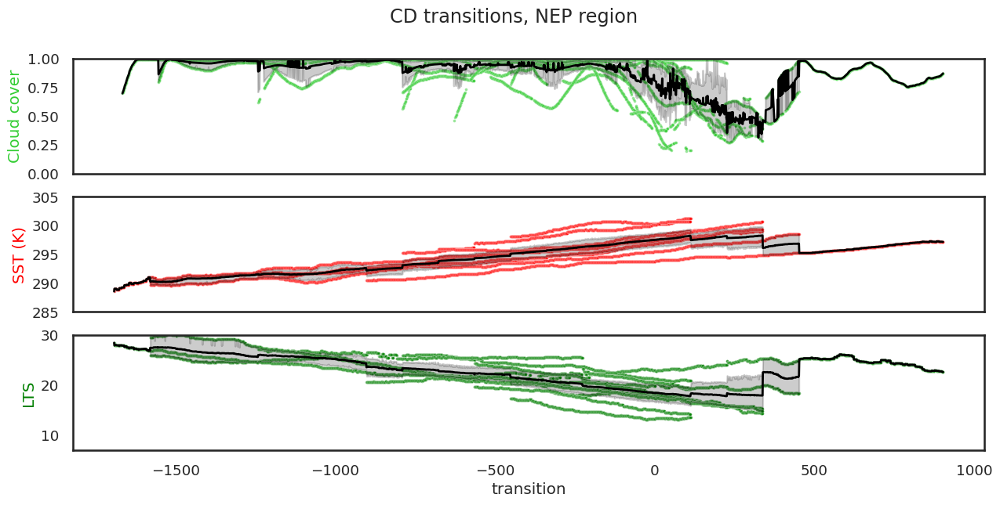

In [ ]:
dfall_trans_cd_NEP = dfall_trans_cd[dfall_trans_cd['stratus_region_index'] == 3]

fig, axs = plt.subplots(3,1, figsize=(15,6.5), sharex=True)
plt.suptitle('CD transitions, NEP region')
ax=axs[0]
sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='MCOP_cloud_cover_256', color='limegreen', s=7, alpha=0.5).set(ylim=(0,1))
sns.lineplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='MCOP_cloud_cover_256', color='black', linewidth=2)
ax.set_ylabel('Cloud cover', color='limegreen')

ax=axs[1]
sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='sea_surface_temperature', color='red', s=7, alpha=0.5).set(ylim=(285,305))
sns.lineplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='sea_surface_temperature', color='black', linewidth=2)
ax.set_ylabel('SST (K)', color='red')

ax=axs[2]
sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='lower_tropospheric_stability', color='green', s=7, alpha=0.5).set(ylim=(7,30))
sns.lineplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='lower_tropospheric_stability', color='black', linewidth=2)
ax.set_ylabel('LTS', color='green')

Text(0, 0.5, 'CTH - LCL /m')

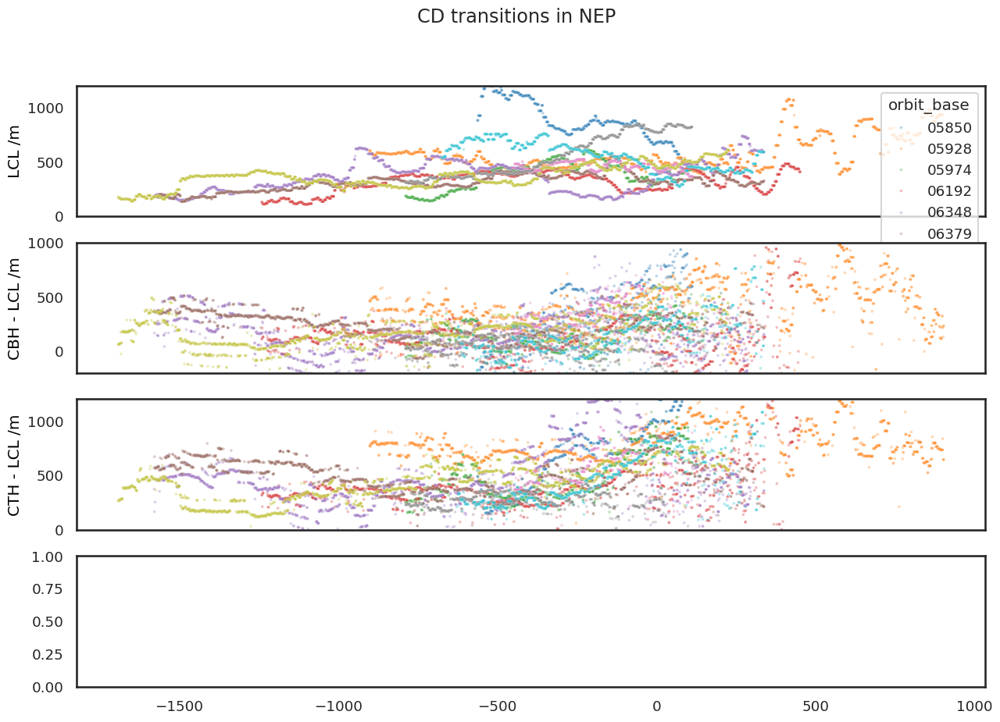

In [ ]:
dfall_trans_cd_NEP = dfall_trans_cd[dfall_trans_cd['stratus_region_index'] == 3]

fig, axs = plt.subplots(4,1, figsize=(15,10), sharex=True)
plt.suptitle('CD transitions in NEP')

ax=axs[0]
sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='lcl', hue='orbit_base', s=7, alpha=0.3, legend=True).set(ylim=(0,1200))
#sns.lineplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='cbh_minus_lcl', color='black', linewidth=2)
ax.set_ylabel('LCL /m', color='black')

ax=axs[1]
sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='cbh_minus_lcl', hue='orbit_base', s=7, alpha=0.3, legend=False).set(ylim=(-200,1000))
#sns.lineplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='cbh_minus_lcl', color='black', linewidth=2)
ax.set_ylabel('CBH - LCL /m', color='black')

ax=axs[2]
sns.scatterplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y=dfall_trans_cd_NEP['cth_m'] - dfall_trans_cd_NEP['lcl'], hue='orbit_base', s=7, alpha=0.3, legend=False).set(ylim=(0,1200))
#sns.lineplot(ax=ax, data=dfall_trans_cd_NEP, x='transition', y='cbh_minus_lcl', color='black', linewidth=2)
ax.set_ylabel('CTH - LCL /m', color='black')

#### compare transitions to all data

In [ ]:
dfall_trans_cd_at_trans = dfall_trans_cd[(dfall_trans_cd['transition'] > - 500) & (dfall_trans_cd['transition'] < 500)]

In [ ]:
tmp[(tmp['cats'] == i)].lower_tropospheric_stability

5870     20.990692
5871     20.990692
5872     20.990692
5873     20.971741
5874     20.975311
           ...    
20989    20.879089
20990    20.801727
20991    20.801727
20992    20.801727
20993    20.801727
Name: lower_tropospheric_stability, Length: 452, dtype: float32

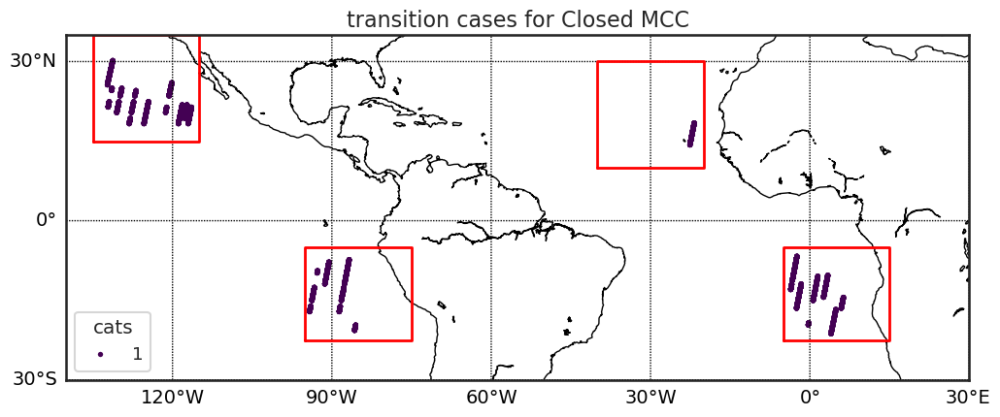

<Figure size 2000x800 with 0 Axes>

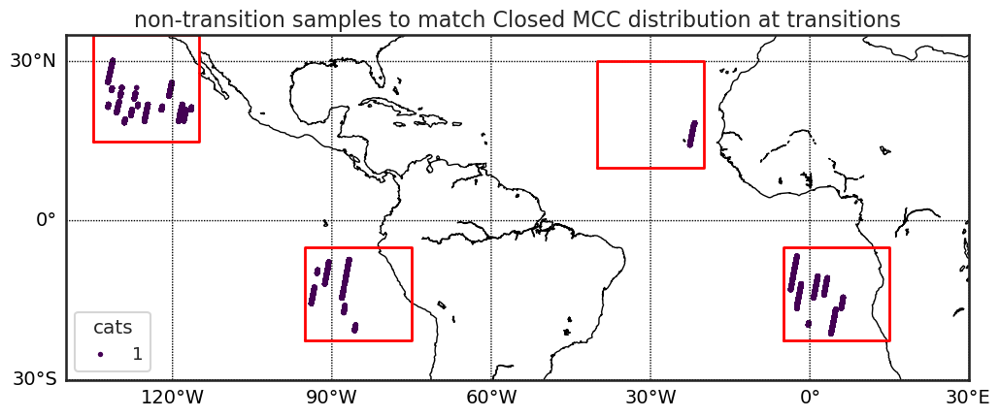

<Figure size 2000x800 with 0 Axes>

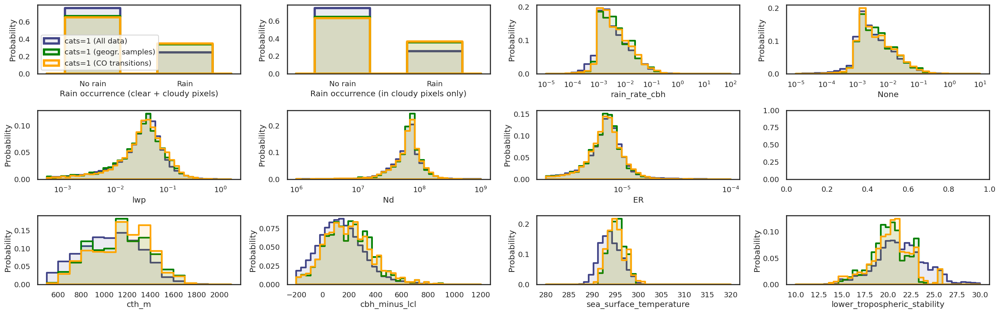

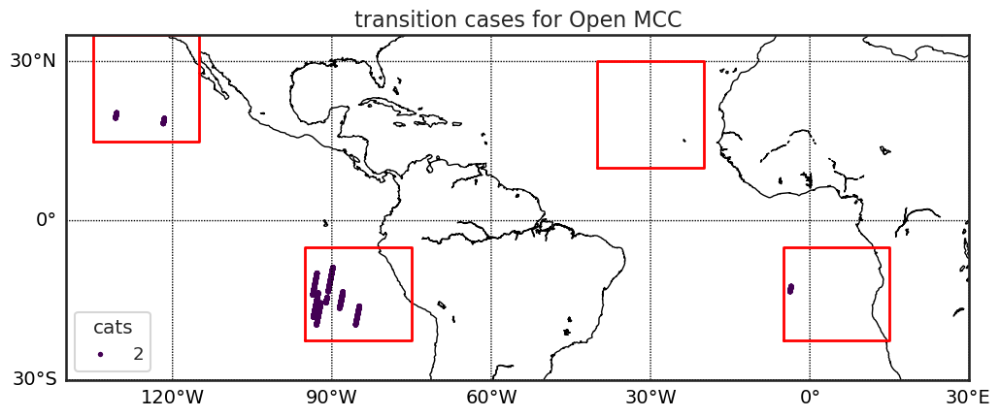

<Figure size 2000x800 with 0 Axes>

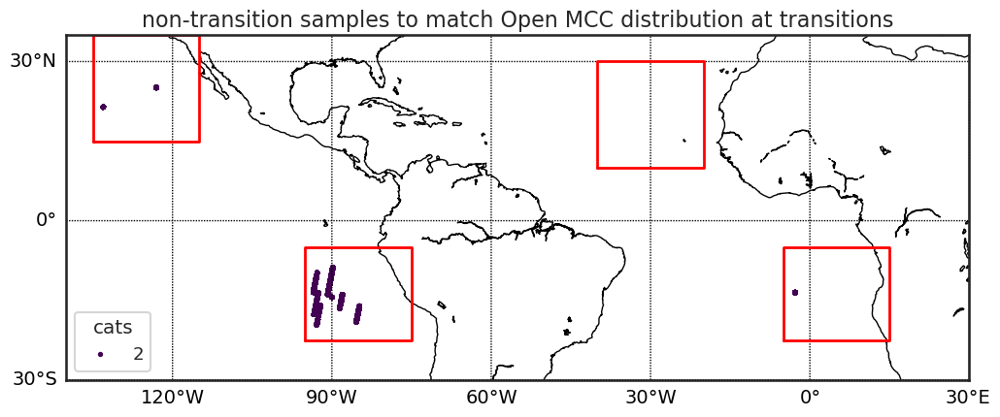

<Figure size 2000x800 with 0 Axes>

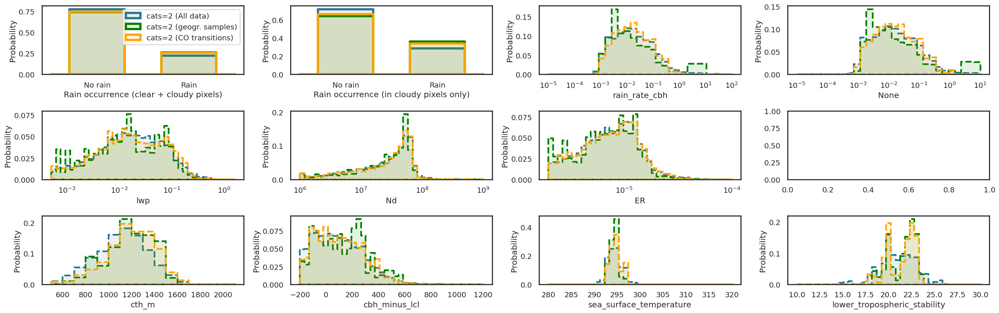

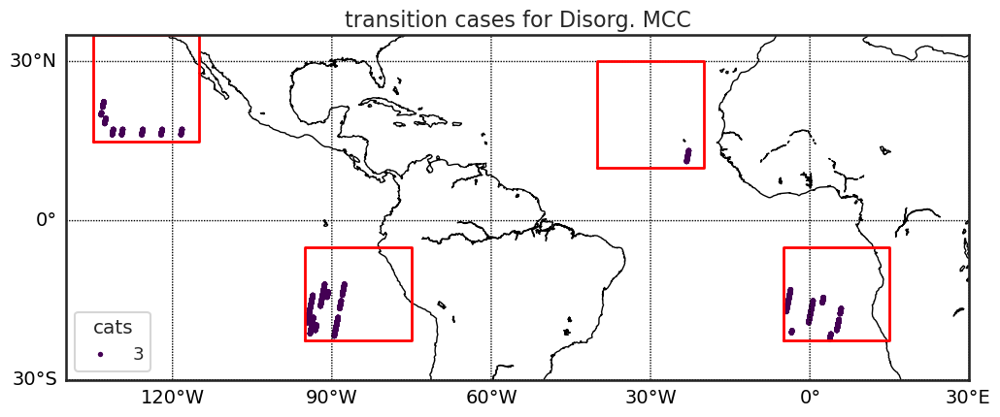

<Figure size 2000x800 with 0 Axes>

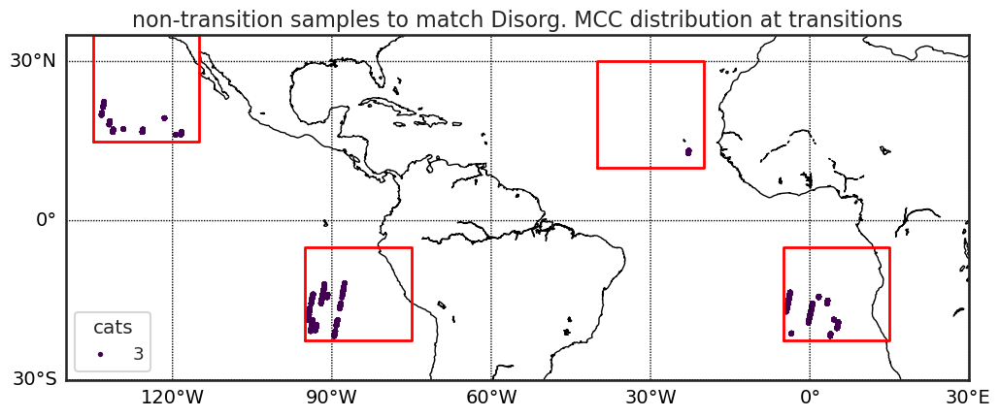

<Figure size 2000x800 with 0 Axes>

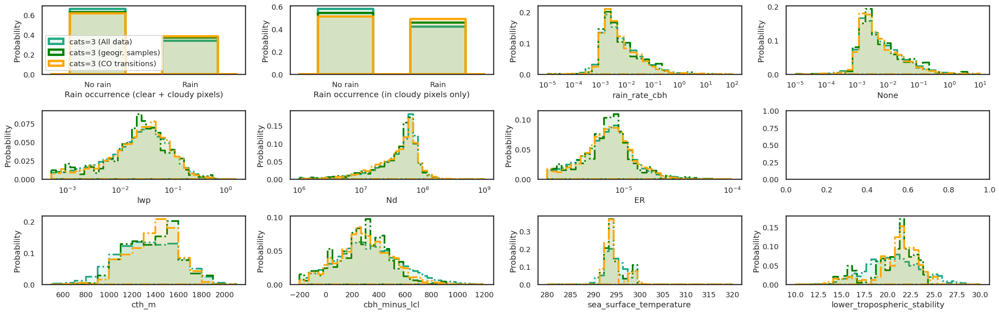

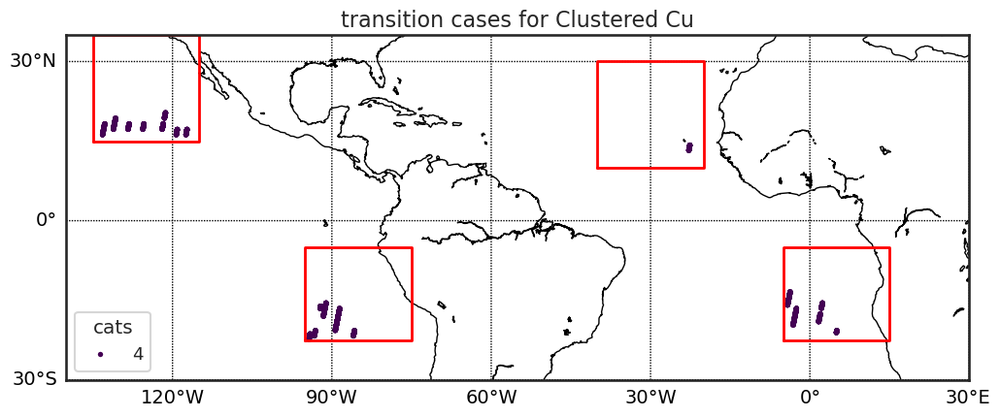

<Figure size 2000x800 with 0 Axes>

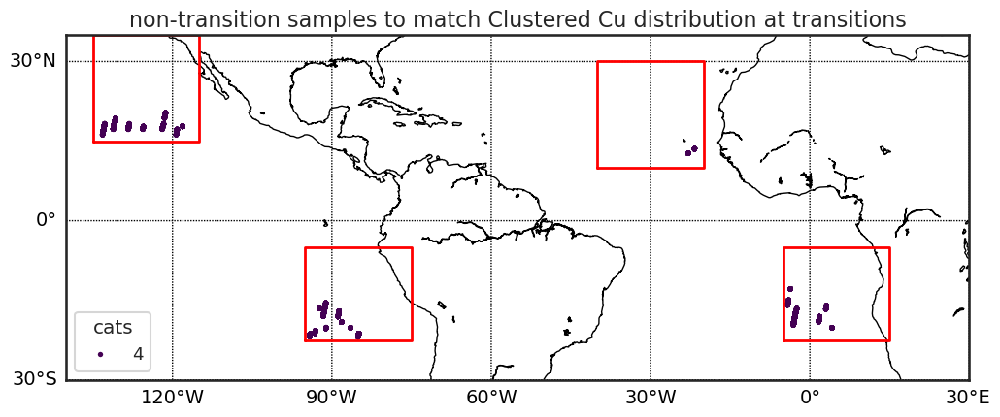

<Figure size 2000x800 with 0 Axes>

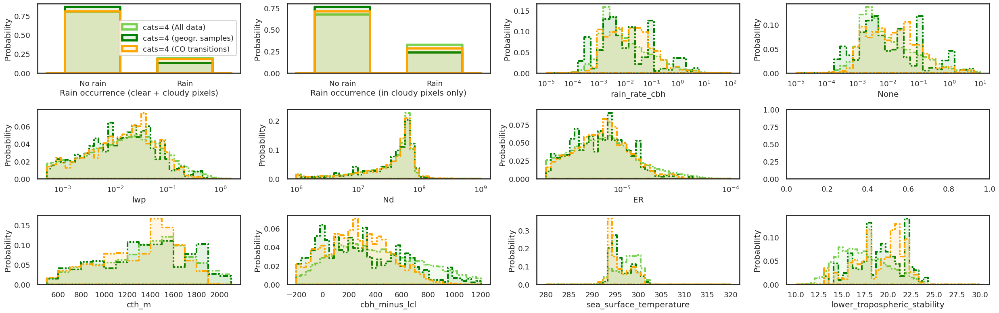

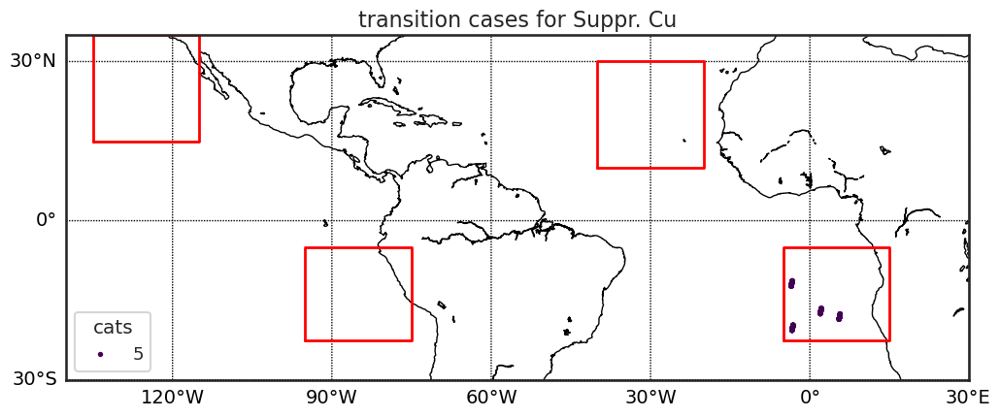

<Figure size 2000x800 with 0 Axes>

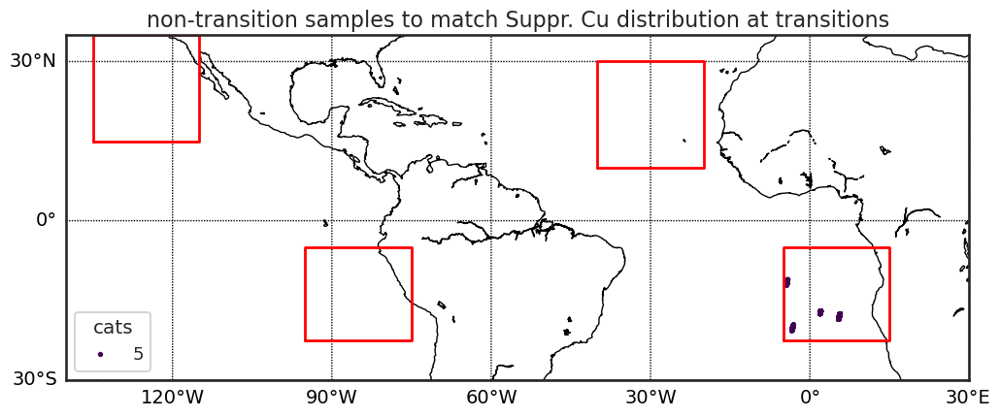

<Figure size 2000x800 with 0 Axes>

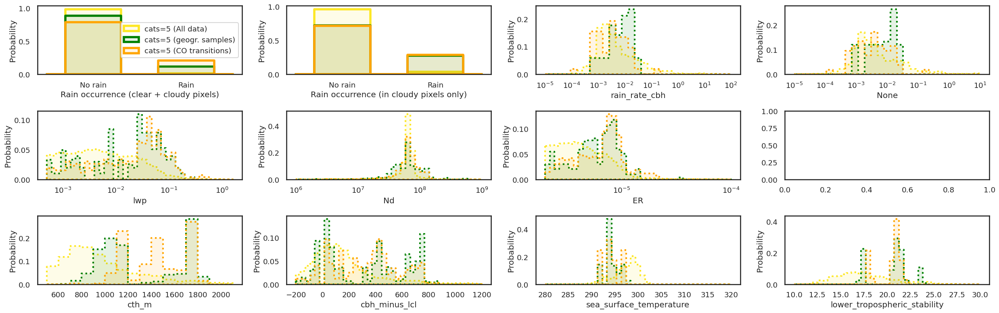

In [ ]:
# sample data fram dffil, that is not in the same orbits as dfall_trans_cd_at_trans, but has the same geographic distribution, as given by similar latitude longitude values, as the data points in dfall_trans_cd_at_trans
for cat in [1,2,3,4,5]: 
    dffil_sample = dffil[~dffil.scene_id_0.isin(dfall_trans_cd_at_trans.scene_id) & (dffil.cats == cat)]

    from sklearn.neighbors import NearestNeighbors
    import numpy as np
    nbrs = NearestNeighbors(n_neighbors=5, algorithm='ball_tree').fit(dffil_sample[['latitude', 'longitude']])
    distances, indices = nbrs.kneighbors(dfall_trans_cd_at_trans[dfall_trans_cd_at_trans.cats == cat][['latitude', 'longitude']])
    dffil_matched = dffil_sample.iloc[indices.flatten()]
    dffil_matched = dffil_matched.reset_index(drop=True)
    dffil_matched

    # global map with 4 rectangles for stratus regions 
    fig, ax = plt.subplots(figsize=(12, 6))
    b = bmap(ax=ax, llr={'lat': (-30, 35), 'lon': (-140, 30)}, merspace=30, parspace=30)
    for sr in stratus_region_names.values():
        llr = stratus_regions[sr]
        lats = [llr['lat'][0], llr['lat'][0], llr['lat'][1], llr['lat'][1], llr['lat'][0]]
        lons = [llr['lon'][0], llr['lon'][1], llr['lon'][1], llr['lon'][0], llr['lon'][0]]
        x, y = b(lons, lats)
        b.plot(x, y, marker=None, color='red', linewidth=2)
    ax.set_title(f'transition cases for {cats_names[cat]}', fontsize=16)

    plt.figure(figsize=(20,8))
    sns.scatterplot(ax=ax, data=dfall_trans_cd_at_trans[dfall_trans_cd_at_trans.cats == cat], x='longitude', y='latitude', hue='cats', palette=catcolors, lw=0, s=15)
    plt.show()

    # global map with 4 rectangles for stratus regions 
    fig, ax = plt.subplots(figsize=(12, 6))
    b = bmap(ax=ax, llr={'lat': (-30, 35), 'lon': (-140, 30)}, merspace=30, parspace=30)
    for sr in stratus_region_names.values():
        llr = stratus_regions[sr]
        lats = [llr['lat'][0], llr['lat'][0], llr['lat'][1], llr['lat'][1], llr['lat'][0]]
        lons = [llr['lon'][0], llr['lon'][1], llr['lon'][1], llr['lon'][0], llr['lon'][0]]
        x, y = b(lons, lats)
        b.plot(x, y, marker=None, color='red', linewidth=2)
    ax.set_title(f'non-transition samples to match {cats_names[cat]} distribution at transitions', fontsize=16)

    plt.figure(figsize=(20,8))
    sns.scatterplot(ax=ax, data=dffil_matched, x='longitude', y='latitude', hue='cats', palette=catcolors, lw=0, s=15)
    plt.show()




    fig, ax = plt.subplots(3,4, figsize=(25, 8))

    for j,tmp in enumerate([dffil, dffil_matched, dfall_trans_cd_at_trans]):
        if j == 0:
            color = catcolors[cat]
            label = 'All data'
        elif j == 1:
            color = 'green'
            label = 'geogr. samples'
        elif j == 2:
            color = 'orange'
            label = 'CO transitions'
        for i in [cat]: #6
            sns.histplot(ax=ax[0,0], x=(tmp[tmp['cats'] == i]['rain_rate_subcloud'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=color, lw=4, label = f'cats={i} ({label})')
            sns.histplot(ax=ax[0,1], x=(tmp[tmp['cats'] == i][tmp.lwp>0]['rain_rate_subcloud'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=color, lw=4)
            sns.histplot(
                ax=ax[0,2], x=tmp[tmp['cats'] == i]['rain_rate_cbh']*3600, bins=np.logspace(-5,2,30),
                element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
                color=color)
            sns.histplot(
                ax=ax[0,3], x=tmp[tmp['cats'] == i]['rain_rate_cbh']*3600 - tmp[tmp['cats'] == i]['rain_rate_surface']*3600, bins=np.logspace(-5,1,30),
                element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
                color=color)
            
            # TODO lwp and Nd errors are not taken into account
            sns.histplot(
                ax=ax[1,0], data=tmp[(tmp['cats'] == i) & (tmp['lwp'] > 0)], x='lwp', bins=np.logspace(-3.3,0.2,40),
                element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
                color=color)
            sns.histplot(
                ax=ax[1,1], data=tmp[(tmp['cats'] == i) & (tmp['lwp'] > 0)], x='Nd', bins=np.logspace(6,9,40),
                element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
                color=color)
            sns.histplot(
                ax=ax[1,2], data=tmp[(tmp['cats'] == i) & (tmp['lwp'] > 0)], x='ER', bins=np.logspace(-5.7,-4,40),
                element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
                color=color)
            
            sns.histplot(
                ax=ax[2,0], data=tmp[(tmp['cats'] == i)], x='cth_m', bins=np.arange(500,2200,100),
                element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
                color=color)
            sns.histplot(
                ax=ax[2,1], data=tmp[(tmp['cats'] == i)], x='cbh_minus_lcl', bins=np.linspace(-200,1200,40),
                element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
                color=color)
            sns.histplot(
                ax=ax[2,2], data=tmp[(tmp['cats'] == i)], x='sea_surface_temperature', bins=np.linspace(280,320,40),
                element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
                color=color)
            sns.histplot(
                ax=ax[2,3], data=tmp[(tmp['cats'] == i)], x='lower_tropospheric_stability', bins=np.linspace(10,30,40),
                element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
                color=color)
            
    ax[0,0].legend()
    for a in ax.flatten()[2:7]:
        a.set_xscale('log')

    for a in ax.flatten()[0:2]:
        a.set_xticks([0,1])
        a.set_xticklabels(['No rain', 'Rain'])
    ax[0,0].set_xlabel('Rain occurrence (clear + cloudy pixels)')
    ax[0,1].set_xlabel('Rain occurrence (in cloudy pixels only)')
    fig.tight_layout()

### CO

In [30]:
trans_co = []
trans_oc = []
trans_co_nonvalid = []
trans_oc_nonvalid = []
for _, dforbit in df.groupby('orbit_base'):
    dfscenes = dforbit.groupby('scene_id')[['orbit_base','scene_id','cats','cert','ice_flag','ocean_mask']].first()
    dfscenes['cats'] = np.where((dfscenes.cert > 0.5) & (dfscenes.ice_flag == 0) & (dfscenes.ocean_mask == 1), dfscenes.cats, -1) # set uncertain scenes to -1
    for i in range(1, len(dfscenes)-1):
        if (dfscenes.cats.iloc[i-1] == 1 and dfscenes.cats.iloc[i] == 2):
            #if not dfscenes.cats.iloc[max(1,i-2) : i].isin([0,1,-1,6]).all(): # before the transiton there should be at least 2 consecutive scenes of cats = 0,1
            #    trans_co_nonvalid.append(dfscenes.scene_id.iloc[i])
            #    continue
            #if not dfscenes.cats.iloc[i : min(len(dfscenes), i+2)].isin([2,-1,6]).all(): # after the transition there should be at least 2 consecutive scenes of cats = 2 (or uncertain)
            #    trans_co_nonvalid.append(dfscenes.scene_id.iloc[i])
            #    continue
            trans_co.append(dfscenes.scene_id.iloc[i])
        elif (dfscenes.cats.iloc[i-1] == 2 and dfscenes.cats.iloc[i] == 1):
            if not dfscenes.cats.iloc[max(1,i-2) : i].isin([2,-1,6]).all():
                trans_oc_nonvalid.append(dfscenes.scene_id.iloc[i])
                continue
            if not dfscenes.cats.iloc[i : min(len(dfscenes), i+2)].isin([0,1,-1,6]).all(): 
                trans_oc_nonvalid.append(dfscenes.scene_id.iloc[i])
                continue
            trans_oc.append(dfscenes.scene_id.iloc[i])

In [31]:
trans_co

[np.int64(3961),
 np.int64(2882),
 np.int64(1713),
 np.int64(4346),
 np.int64(4416),
 np.int64(1933),
 np.int64(4557),
 np.int64(4649),
 np.int64(4754),
 np.int64(2169),
 np.int64(2183),
 np.int64(2215),
 np.int64(2263),
 np.int64(2267),
 np.int64(2312),
 np.int64(2322),
 np.int64(2380),
 np.int64(2423),
 np.int64(6120),
 np.int64(6180),
 np.int64(6262),
 np.int64(6291),
 np.int64(6452),
 np.int64(6460),
 np.int64(8195),
 np.int64(7368),
 np.int64(6673),
 np.int64(6754)]

In [32]:
trans_oc

[np.int64(4758),
 np.int64(2175),
 np.int64(2271),
 np.int64(2427),
 np.int64(6149),
 np.int64(6198),
 np.int64(6266),
 np.int64(6464),
 np.int64(6801)]

In [33]:
df[df.scene_id.isin(trans_co)].orbit.unique()

array(['05819D', '05970E', '06159E', '06177D', '06208E', '06299E',
       '06317D', '06348E', '06426D', '06439E', '06455E', '06486E',
       '06517E', '06564E', '06595E', '06688E', '06719E', '06766E',
       '06797E', '06906E', '06939D', '06966E', '07046E', '07093E'],
      dtype=object)

In [ ]:
from PIL import Image
for i in range(len(trans_co)):
    orbit = df[df.scene_id == trans_co[i]].orbit.iloc[0]
    print(f'Orbit {orbit}')
    print(f'Transition {i+1} at scene_id {trans_co[i]}')
    dforbit = df[df.orbit == orbit]
    df_trans_co = dforbit[(dforbit.scene_id >= trans_co[i]-5) & (df.scene_id <= trans_co[i]+5)].reset_index(drop=True)

    img = glob.glob(f'./../figures_judge/judge_{orbit}_*.png'.format(orbit=orbit))[0]
    Image.open(img).show()
    
    fig, ax = plt.subplots(4,1, figsize=(15,7), sharex=True)
    sns.scatterplot(ax=ax[0], data=df_trans_co[df_trans_co['lwp']>0], x=df_trans_co[df_trans_co['lwp']>0].index, y='lwp', s=10).set(yscale='log')
    ax[0].set_ylabel('LWP (g m$^{-2}$)', color='steelblue')
    ax2 = ax[0].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_co[df_trans_co['lwp']>0], x=df_trans_co[df_trans_co['lwp']>0].index, y='Nd', color='orange', s=10).set(yscale='log')
    ax2.set_ylabel('Nd (cm$^{-3}$)', color='orange')
    
    sns.scatterplot(ax=ax[1], data=df_trans_co, x=df_trans_co.index, y='cbh_minus_lcl', color='red', s=10).set(ylim=(-200,700))
    ax[1].set_ylabel('CBH - LCL (m)', color='red')
    ax2=ax[1].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_co, x=df_trans_co.index, y='cth_m', color='orange', s=10)
    ax2.set_ylabel('CTH (m)', color='orange')

    sns.scatterplot(ax=ax[2], data=df_trans_co[df_trans_co['rain_rate_cbh']>0], x=df_trans_co[df_trans_co['rain_rate_cbh']>0].index, y='rain_rate_cbh', color='blue', s=10).set(yscale='log')
    ax[2].set_ylabel('RR at CBH', color='blue')
    ax2 = ax[2].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_co, x=df_trans_co.index, y='MCOP_cloud_cover_judge', color='green', s=10).set(ylim=(0,1))
    ax2.set_ylabel('MCOP CC', color='green')
    sns.scatterplot(ax=ax2, data=df_trans_co, x=df_trans_co.index, y='MCOP_cloud_cover_200', color='limegreen', s=10).set(ylim=(0,1))

    sns.scatterplot(ax=ax[3], data=df_trans_co, x=df_trans_co.index, y='lower_tropospheric_stability', color='green', s=10).set(ylim=(7,30))
    ax[3].set_ylabel('LTS', color='green')
    ax2 = ax[3].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_co, x=df_trans_co.index, y='sea_surface_temperature', color='red', s=10).set(ylim=(290,310))
    ax2.set_ylabel('SST', color='red')
    # vertical line at transition
    for a in ax:
        a.axvline(x=df_trans_co[(df_trans_co.scene_id == trans_co[i])].index[0], color='gray', linestyle='--')
    plt.show()

In [ ]:
from PIL import Image
for i in range(len(trans_oc)):
    orbit = df[df.scene_id == trans_oc[i]].orbit.iloc[0]
    print(f'Orbit {orbit}')
    print(f'Transition {i+1} at scene_id {trans_oc[i]}')
    dforbit = df[df.orbit == orbit]
    df_trans_oc = dforbit[(dforbit.scene_id >= trans_oc[i]-5) & (df.scene_id <= trans_oc[i]+5)].reset_index(drop=True)

    img = glob.glob(f'./../figures_judge/judge_{orbit}_*.png'.format(orbit=orbit))[0]
    Image.open(img).show()
    
    fig, ax = plt.subplots(4,1, figsize=(15,7), sharex=True)
    sns.scatterplot(ax=ax[0], data=df_trans_oc[df_trans_oc['lwp']>0], x=df_trans_oc[df_trans_oc['lwp']>0].index, y='lwp', s=10).set(yscale='log')
    ax[0].set_ylabel('LWP (g m$^{-2}$)', color='steelblue')
    ax2 = ax[0].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_oc[df_trans_oc['lwp']>0], x=df_trans_oc[df_trans_oc['lwp']>0].index, y='Nd', color='orange', s=10).set(yscale='log')
    ax2.set_ylabel('Nd (cm$^{-3}$)', color='orange')
    
    sns.scatterplot(ax=ax[1], data=df_trans_oc, x=df_trans_oc.index, y='cbh_minus_lcl', color='red', s=10).set(ylim=(-200,700))
    ax[1].set_ylabel('CBH - LCL (m)', color='red')
    ax2=ax[1].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_oc, x=df_trans_oc.index, y='cth_m', color='orange', s=10)
    ax2.set_ylabel('CTH (m)', color='orange')

    sns.scatterplot(ax=ax[2], data=df_trans_oc[df_trans_oc['rain_rate_cbh']>0], x=df_trans_oc[df_trans_oc['rain_rate_cbh']>0].index, y='rain_rate_cbh', color='blue', s=10).set(yscale='log')
    ax[2].set_ylabel('RR at CBH', color='blue')
    ax2 = ax[2].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_oc, x=df_trans_oc.index, y='MCOP_cloud_cover_judge', color='green', s=10).set(ylim=(0,1))
    ax2.set_ylabel('MCOP CC', color='green')
    sns.scatterplot(ax=ax2, data=df_trans_oc, x=df_trans_oc.index, y='MCOP_cloud_cover_200', color='limegreen', s=10).set(ylim=(0,1))

    sns.scatterplot(ax=ax[3], data=df_trans_oc, x=df_trans_oc.index, y='lower_tropospheric_stability', color='green', s=10).set(ylim=(7,30))
    ax[3].set_ylabel('LTS', color='green')
    ax2 = ax[3].twinx()
    sns.scatterplot(ax=ax2, data=df_trans_oc, x=df_trans_oc.index, y='sea_surface_temperature', color='red', s=10).set(ylim=(290,310))
    ax2.set_ylabel('SST', color='red')
    # vertical line at transition
    for a in ax:
        a.axvline(x=df_trans_oc[(df_trans_oc.scene_id == trans_oc[i])].index[0], color='gray', linestyle='--')
    plt.show()

In [34]:
# create a new dataframe combining all transitions
for i in range(len(trans_co)):
    orbit = df[df.scene_id == trans_co[i]].orbit.iloc[0]
    if orbit == '06575E': # skip this orbit, because the transition is at the very beginning and over land
        continue
    dforbit = df[df.orbit == orbit]
    print(f'Transition {i} at orbit {orbit} and scene_id {trans_co[i]}')
    df_trans_co = dforbit[(dforbit.scene_id >= trans_co[i]-2) & (dforbit.scene_id <= trans_co[i]+2)].reset_index(drop=True)
    # make a column for the index
    trans_index = df_trans_co[(df_trans_co.scene_id == trans_co[i])].index[0]
    df_trans_co['transition'] = df_trans_co.index - trans_index
    if i == 0:
        dfall_trans_co = df_trans_co
    else:
        dfall_trans_co = pd.concat([dfall_trans_co, df_trans_co], axis=0)
dfall_trans_co = dfall_trans_co.reset_index(drop=True)

# same for OC transitions
print('\n... processing OC transitions')
for i in range(len(trans_oc)):
    orbit = df[df.scene_id == trans_oc[i]].orbit.iloc[0]
    if orbit == '06575E': # skip this orbit, because the transition is at the very beginning and over land
        continue
    dforbit = df[df.orbit == orbit]
    print(f'Transition {i} at orbit {orbit} and scene_id {trans_oc[i]}')
    df_trans_oc = dforbit[(dforbit.scene_id >= trans_oc[i]-2) & (dforbit.scene_id <= trans_oc[i]+2)].reset_index(drop=True)
    # make a column for the index: reverse the index in the same step
    trans_index = df_trans_oc[(df_trans_oc.scene_id == trans_oc[i])].index[0]
    df_trans_oc['transition'] = (df_trans_oc.index - trans_index)[::-1]
    
    # now that the index is reversed, we can append the OC transitions to the CO transition dataframe
    dfall_trans_co = pd.concat([dfall_trans_co, df_trans_oc], axis=0)
dfall_trans_co = dfall_trans_co.reset_index(drop=True)

Transition 0 at orbit 05819D and scene_id 3961
Transition 1 at orbit 05970E and scene_id 2882
Transition 2 at orbit 06159E and scene_id 1713
Transition 3 at orbit 06177D and scene_id 4346
Transition 4 at orbit 06208E and scene_id 4416
Transition 5 at orbit 06299E and scene_id 1933
Transition 6 at orbit 06317D and scene_id 4557
Transition 7 at orbit 06348E and scene_id 4649
Transition 8 at orbit 06426D and scene_id 4754
Transition 9 at orbit 06439E and scene_id 2169
Transition 10 at orbit 06439E and scene_id 2183
Transition 11 at orbit 06455E and scene_id 2215
Transition 12 at orbit 06486E and scene_id 2263
Transition 13 at orbit 06486E and scene_id 2267
Transition 14 at orbit 06517E and scene_id 2312
Transition 15 at orbit 06517E and scene_id 2322
Transition 16 at orbit 06564E and scene_id 2380
Transition 17 at orbit 06595E and scene_id 2423
Transition 18 at orbit 06688E and scene_id 6120
Transition 19 at orbit 06719E and scene_id 6180
Transition 20 at orbit 06766E and scene_id 6262
Tr

In [35]:
dfall_trans_co

,index,along_track,time,latitude,longitude,stratus_region_index,lwp,ER,ER_passive_perspective,Nd,...,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1,ocean_mask,cats,cert,scene_id,ice_flag,MCOP_cloud_cover_judge,orbit_base,transition
0,495951,4056,2025-06-06 22:50:35.298924544,30.787521,-129.246587,3,0.074502,0.000014,0.000015,18733856.0,...,0.672174,0.720841,True,1,0.538756,3959,0.0,0.937622,05819,-113
1,495952,4057,2025-06-06 22:50:35.435271808,30.778732,-129.248616,3,0.096035,0.000014,0.000016,18842014.0,...,0.672174,0.720841,True,1,0.538756,3959,0.0,0.937622,05819,-112
2,495953,4058,2025-06-06 22:50:35.617192320,30.767006,-129.251322,3,0.134422,0.000018,0.000020,13838050.0,...,0.672174,0.720841,True,1,0.538756,3959,0.0,0.937622,05819,-111
3,495954,4059,2025-06-06 22:50:35.753545344,30.758218,-129.253350,3,0.095079,0.000016,0.000017,18209348.0,...,0.672174,0.720841,True,1,0.538756,3959,0.0,0.937622,05819,-110
4,495955,4060,2025-06-06 22:50:35.889892352,30.749429,-129.255379,3,0.203191,0.000017,0.000020,19377522.0,...,0.672174,0.720841,True,1,0.538756,3959,0.0,0.937622,05819,-109
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12411,206129,4632,2025-08-28 19:13:27.704482048,-20.242092,-81.875000,2,0.007530,0.000004,0.000004,66295264.0,...,0.633959,0.772829,True,1,0.987835,6803,0.0,0.956726,07108,-109
12412,206130,4633,2025-08-28 19:13:27.882260352,-20.253569,-81.877337,2,0.020627,0.000010,0.000010,13841331.0,...,0.633959,0.772829,True,1,0.987835,6803,0.0,0.956726,07108,-110
12413,206131,4634,2025-08-28 19:13:28.019300352,-20.262414,-81.879138,2,0.022488,0.000010,0.000010,21794072.0,...,0.633959,0.772829,True,1,0.987835,6803,0.0,0.956726,07108,-111
12414,206132,4635,2025-08-28 19:13:28.156339072,-20.271261,-81.880940,2,0.027076,0.000008,0.000009,32062884.0,...,0.633959,0.772829,True,1,0.987835,6803,0.0,0.956726,07108,-112


<Axes: title={'center': 'closed MCC -> open MCC'}, xlabel='longitude', ylabel='latitude'>

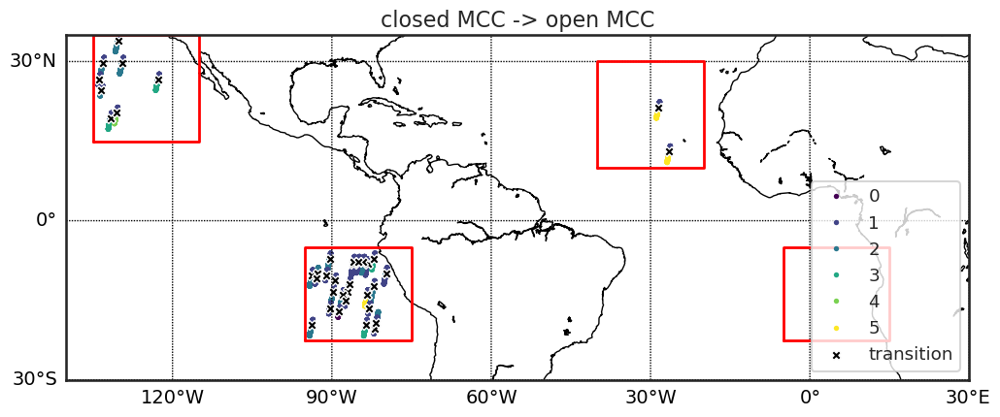

<Figure size 2000x800 with 0 Axes>

In [36]:
# global map with 4 rectangles for stratus regions 
fig, ax = plt.subplots(figsize=(12, 6))
b = bmap(ax=ax, llr={'lat': (-30, 35), 'lon': (-140, 30)}, merspace=30, parspace=30)
for sr in stratus_region_names.values():
    llr = stratus_regions[sr]
    lats = [llr['lat'][0], llr['lat'][0], llr['lat'][1], llr['lat'][1], llr['lat'][0]]
    lons = [llr['lon'][0], llr['lon'][1], llr['lon'][1], llr['lon'][0], llr['lon'][0]]
    x, y = b(lons, lats)
    b.plot(x, y, marker=None, color='red', linewidth=2)
ax.set_title('closed MCC -> open MCC', fontsize=16)

plt.figure(figsize=(20,8))
sns.scatterplot(ax=ax, data=dfall_trans_co, x='longitude', y='latitude', hue='cats', palette=catcolors, lw=0, s=15)
sns.scatterplot(ax=ax, data=dfall_trans_co[dfall_trans_co.transition == 0], x='longitude', y='latitude', color='black', lw=1, s=50, marker='X', label='transition')

In [37]:
dfall_trans_co['cth_m_113'] = dfall_trans_co.groupby(['orbit', 'scene_id'])['cth_m'].transform(lambda x: np.nanmean(x))
dfall_trans_co['cbh_minus_lcl_113'] = dfall_trans_co.groupby(['orbit', 'scene_id'])['cbh_minus_lcl'].transform(lambda x: np.nanmean(x))
dfall_trans_co['cbh_max_minus_min_113'] = dfall_trans_co.groupby(['orbit', 'scene_id'])['cbh_m'].transform(lambda x: np.nanmax(x) - np.nanmin(x))
dfall_trans_co['lwp_113'] = dfall_trans_co.groupby(['orbit', 'scene_id'])['lwp'].transform(lambda x: np.nanmean(x))
dfall_trans_co['rain_rate_cbh_113'] = dfall_trans_co.groupby(['orbit', 'scene_id'])['rain_rate_cbh'].transform(lambda x: np.nanmean(x))
dfall_trans_co['rain_rate_cbh_everywhere_113'] = dfall_trans_co.groupby(['orbit', 'scene_id'])['rain_rate_cbh'].transform(lambda x: np.mean(x.fillna(0)))
dfall_trans_co['rain_rate_cbh_std_113'] = dfall_trans_co.groupby(['orbit', 'scene_id'])['rain_rate_cbh'].transform(lambda x: np.nanstd(x.fillna(0)))

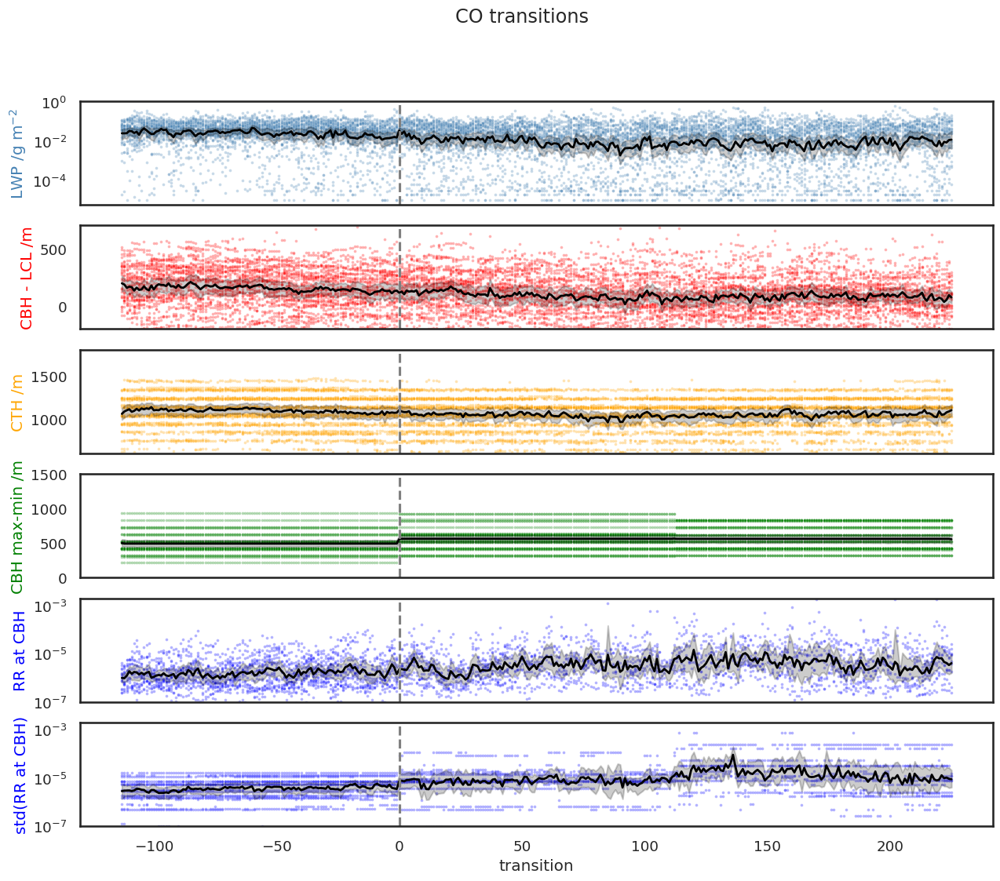

In [64]:
fig, axs = plt.subplots(6,1, figsize=(15,12), sharex=True)
plt.suptitle('CO transitions')
ax=axs[0]
sns.scatterplot(ax=ax, data=dfall_trans_co[dfall_trans_co['lwp']>0], x='transition', y='lwp', color='steelblue', s=7, alpha=0.3).set(yscale='log')
sns.lineplot(ax=ax, data=dfall_trans_co[dfall_trans_co['lwp']>0], x='transition', y='lwp', color='black', linewidth=2)
ax.set_ylabel('LWP /g m$^{-2}$', color='steelblue')

ax=axs[1]
sns.scatterplot(ax=ax, data=dfall_trans_co, x='transition', y='cbh_minus_lcl', color='red', s=7, alpha=0.3).set(ylim=(-200,700))
sns.lineplot(ax=ax, data=dfall_trans_co, x='transition', y='cbh_minus_lcl', color='black', linewidth=2)
ax.set_ylabel('CBH - LCL /m', color='red')

#ax=axs[2]
#sns.scatterplot(ax=ax, data=dfall_trans_co, x='transition', y='coupled_fraction', color='red', s=7, alpha=0.3).set(ylim=(-0.1,1.1))
#sns.lineplot(ax=ax, data=dfall_trans_co, x='transition', y='coupled_fraction', color='black', linewidth=2)
#ax.set_ylabel('Coupled Fraction', color='red')

ax=axs[2]
sns.scatterplot(ax=ax, data=dfall_trans_co, x='transition', y='cth_m', color='orange', s=7, alpha=0.3).set(ylim=(600,1800))
sns.lineplot(ax=ax, data=dfall_trans_co, x='transition', y='cth_m', color='black', linewidth=2)
ax.set_ylabel('CTH /m', color='orange')

ax=axs[3]
sns.scatterplot(ax=ax, data=dfall_trans_co, x='transition', y='cbh_max_minus_min_113', color='green', s=7, alpha=0.3).set(ylim=(0,1500))
sns.lineplot(ax=ax, data=dfall_trans_co, x='transition', y='cbh_max_minus_min_113', color='black', linewidth=2)
ax.set_ylabel('CBH max-min /m', color='green')
#sns.scatterplot(ax=ax, data=dfall_trans_co, x='transition', y='multilayer', color='red', s=7, alpha=0.3).set(ylim=(-0.1,1.1))
#sns.lineplot(ax=ax, data=dfall_trans_co, x='transition', y='multilayer', color='black', linewidth=2)
#ax.set_ylabel('Multilayer', color='red')

ax=axs[4]
sns.scatterplot(ax=ax, data=dfall_trans_co[dfall_trans_co['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='blue', s=7, alpha=0.3).set(yscale='log', ylim=(1e-7,2e-3))
sns.lineplot(ax=ax, data=dfall_trans_co[dfall_trans_co['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='black', linewidth=2)
ax.set_ylabel('RR at CBH', color='blue')

ax=axs[5]
sns.scatterplot(ax=ax, data=dfall_trans_co[dfall_trans_co['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh_std_113', color='blue', s=7, alpha=0.3).set(yscale='log', ylim=(1e-7,2e-3))
sns.lineplot(ax=ax, data=dfall_trans_co[dfall_trans_co['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh_std_113', color='black', linewidth=2)
ax.set_ylabel('std(RR at CBH)', color='blue')

for ax in axs:
    ax.axvline(x=0, color='gray', linestyle='--')
plt.show()

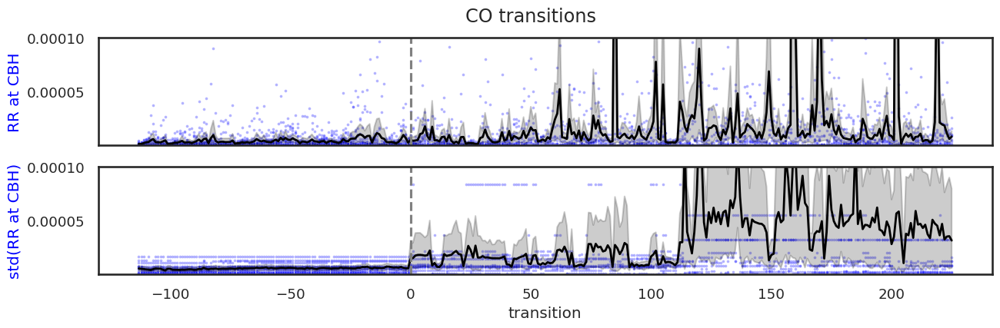

In [46]:
fig, axs = plt.subplots(2,1, figsize=(15,4), sharex=True)
plt.suptitle('CO transitions')

ax=axs[0]
sns.scatterplot(ax=ax, data=dfall_trans_co[dfall_trans_co['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='blue', s=7, alpha=0.3).set(ylim=(1e-7,1e-4))
sns.lineplot(ax=ax, data=dfall_trans_co[dfall_trans_co['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh', color='black', linewidth=2)
ax.set_ylabel('RR at CBH', color='blue')

ax=axs[1]
sns.scatterplot(ax=ax, data=dfall_trans_co[dfall_trans_co['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh_std_113', color='blue', s=7, alpha=0.3).set(ylim=(1e-7,1e-4))
sns.lineplot(ax=ax, data=dfall_trans_co[dfall_trans_co['rain_rate_cbh']>0], x='transition', y='rain_rate_cbh_std_113', color='black', linewidth=2)
ax.set_ylabel('std(RR at CBH)', color='blue')

for ax in axs:
    ax.axvline(x=0, color='gray', linestyle='--')
plt.show()

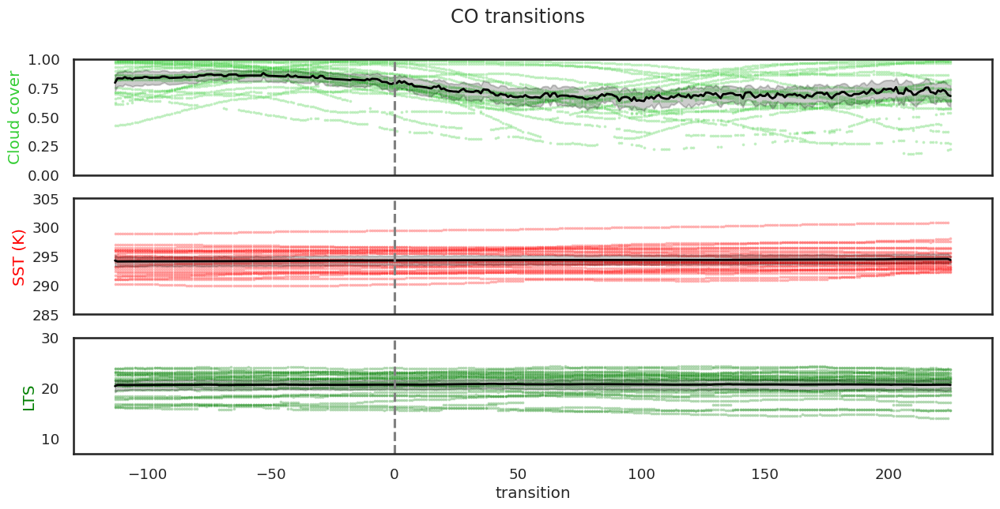

In [ ]:
fig, axs = plt.subplots(3,1, figsize=(15,6.5), sharex=True)
plt.suptitle('CO transitions')
ax=axs[0]
sns.scatterplot(ax=ax, data=dfall_trans_co, x='transition', y='MCOP_cloud_cover_200', color='limegreen', s=7, alpha=0.3).set(ylim=(0,1))
sns.lineplot(ax=ax, data=dfall_trans_co, x='transition', y='MCOP_cloud_cover_200', color='black', linewidth=2)
ax.set_ylabel('Cloud cover', color='limegreen')

ax=axs[1]
sns.scatterplot(ax=ax, data=dfall_trans_co, x='transition', y='sea_surface_temperature', color='red', s=7, alpha=0.3).set(ylim=(285,305))
sns.lineplot(ax=ax, data=dfall_trans_co, x='transition', y='sea_surface_temperature', color='black', linewidth=2)
ax.set_ylabel('SST (K)', color='red')

ax=axs[2]
sns.scatterplot(ax=ax, data=dfall_trans_co, x='transition', y='lower_tropospheric_stability', color='green', s=7, alpha=0.3).set(ylim=(7,30))
sns.lineplot(ax=ax, data=dfall_trans_co, x='transition', y='lower_tropospheric_stability', color='black', linewidth=2)
ax.set_ylabel('LTS', color='green')

for ax in axs:
    ax.axvline(x=0, color='gray', linestyle='--')

In [42]:
dfall_trans_co.transition

0       -113
1       -112
2       -111
3       -110
4       -109
        ... 
12411   -109
12412   -110
12413   -111
12414   -112
12415   -113
Name: transition, Length: 12416, dtype: int64

#### compare transitions to all data

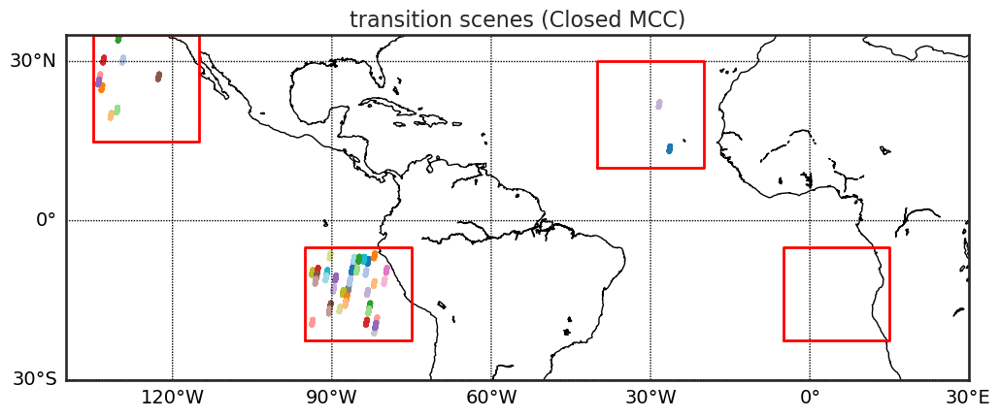

<Figure size 2000x800 with 0 Axes>

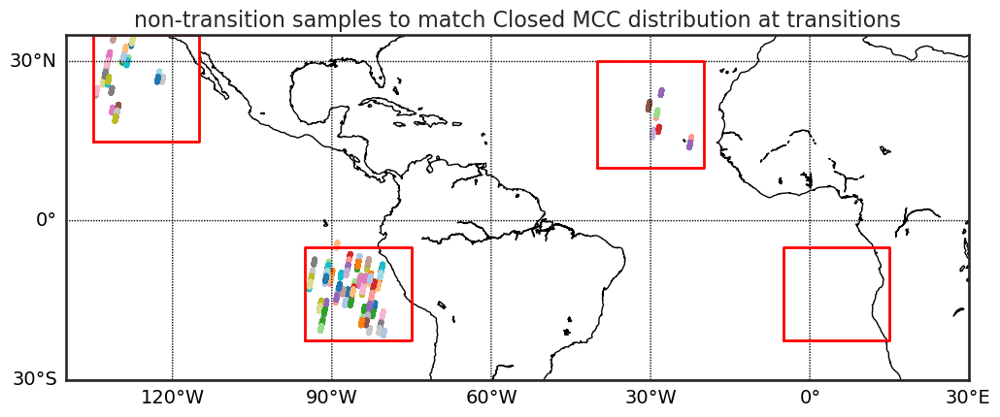

<Figure size 2000x800 with 0 Axes>

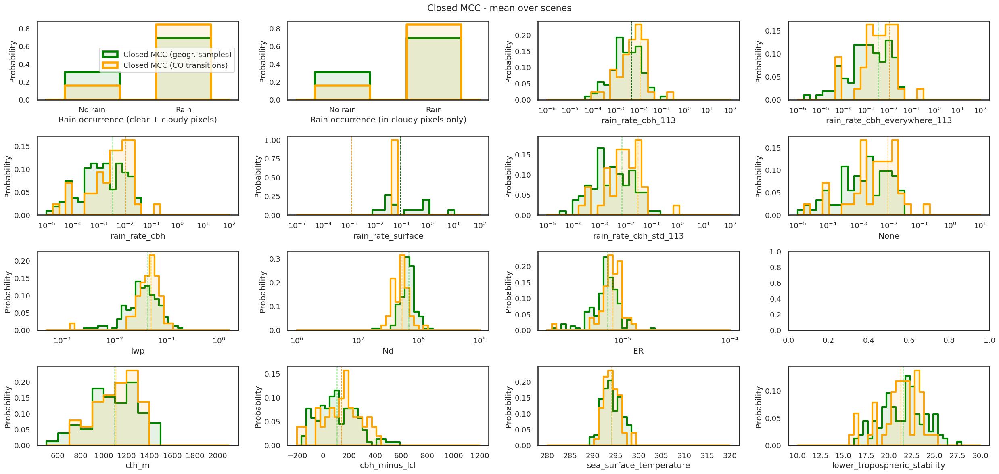

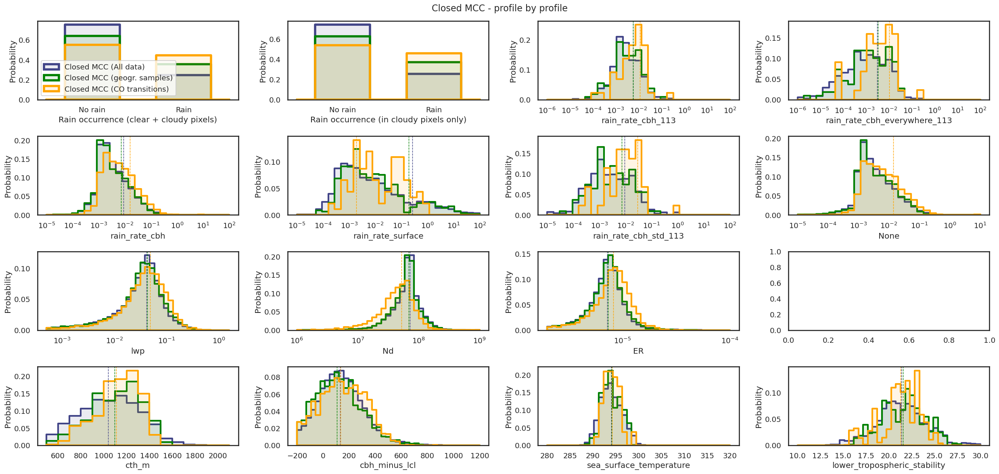

In [38]:
# sample data fram dffil, that is not in the same orbits as tmp_trans_co, but has the same geographic distribution, as given by similar latitude longitude values, as the data points in tmp_trans_co
for cat in [1]: 
    dffil_sample = dffil[~dffil.orbit.isin(dfall_trans_co.orbit) & (dffil.cats == cat)]
    dffil_sample_scene_latlon = dffil_sample[['scene_id','latitude', 'longitude']].groupby('scene_id').mean().reset_index()
    # only consider the scenes closest to the C-O transition (i.e. transition > -113) (actually this is anyways the case in dfall_trans_co...)
    tmp_trans_co = dfall_trans_co[(dfall_trans_co.transition > -113) & (dfall_trans_co.cats == cat)]
    trans_co_scene_latlon = tmp_trans_co[['scene_id','latitude', 'longitude']].groupby('scene_id').mean().reset_index()

    # choose scenes that have similar lat lon values as the scenes in tmp_trans_co
    from sklearn.neighbors import NearestNeighbors
    import numpy as np
    nbrs = NearestNeighbors(n_neighbors=5, algorithm='ball_tree').fit(dffil_sample_scene_latlon[['latitude', 'longitude']])
    distances, indices = nbrs.kneighbors(trans_co_scene_latlon[['latitude', 'longitude']])
    matched_scene_ids = dffil_sample_scene_latlon.iloc[indices.flatten()].scene_id
    dffil_matched = dffil_sample[dffil_sample.scene_id.isin(matched_scene_ids)]
    dffil_matched = dffil_matched.reset_index(drop=True)

    # global map with 4 rectangles for stratus regions 
    fig, ax = plt.subplots(figsize=(12, 6))
    b = bmap(ax=ax, llr={'lat': (-30, 35), 'lon': (-140, 30)}, merspace=30, parspace=30)
    for sr in stratus_region_names.values():
        llr = stratus_regions[sr]
        lats = [llr['lat'][0], llr['lat'][0], llr['lat'][1], llr['lat'][1], llr['lat'][0]]
        lons = [llr['lon'][0], llr['lon'][1], llr['lon'][1], llr['lon'][0], llr['lon'][0]]
        x, y = b(lons, lats)
        b.plot(x, y, marker=None, color='red', linewidth=2)
    ax.set_title(f'transition scenes ({cats_names[cat]})', fontsize=16)
    plt.figure(figsize=(20,8))
    sns.scatterplot(ax=ax, data=tmp_trans_co, x='longitude', y='latitude', hue='scene_id', palette='tab20', legend=False, lw=0, s=15)
    plt.show()

    # global map with 4 rectangles for stratus regions 
    fig, ax = plt.subplots(figsize=(12, 6))
    b = bmap(ax=ax, llr={'lat': (-30, 35), 'lon': (-140, 30)}, merspace=30, parspace=30)
    for sr in stratus_region_names.values():
        llr = stratus_regions[sr]
        lats = [llr['lat'][0], llr['lat'][0], llr['lat'][1], llr['lat'][1], llr['lat'][0]]
        lons = [llr['lon'][0], llr['lon'][1], llr['lon'][1], llr['lon'][0], llr['lon'][0]]
        x, y = b(lons, lats)
        b.plot(x, y, marker=None, color='red', linewidth=2)
    ax.set_title(f'non-transition samples to match {cats_names[cat]} distribution at transitions', fontsize=16)
    plt.figure(figsize=(20,8))
    sns.scatterplot(ax=ax, data=dffil_matched, x='longitude', y='latitude', hue='scene_id', palette='tab20', legend=False, lw=0, s=15)
    plt.show()


    for taking_mean in [True, False]:
        fig, ax = plt.subplots(4,4, figsize=(25, 12))

        for j,tmp in enumerate([dffil, dffil_matched, tmp_trans_co]): # , tmp_trans_co[tmp_trans_co.transition > -50]
            tmp = tmp[(tmp['cats'] == i)]
            if taking_mean:
                tmp = tmp[tmp.lwp > 0].fillna(0)
                tmp = tmp[['scene_id', 'rain_rate_subcloud', 'rain_rate_cbh', 'rain_rate_surface', 
                           'rain_rate_cbh_113', 'rain_rate_cbh_everywhere_113', 'rain_rate_cbh_std_113',
                           'lwp', 'ER', 'Nd', 'cth_m', 'cbh_minus_lcl', 
                           'sea_surface_temperature', 'lower_tropospheric_stability']].groupby('scene_id').mean()
                fig.suptitle(f'{cats_names[cat]} - mean over scenes', fontsize=16)
            else:
                fig.suptitle(f'{cats_names[cat]} - profile by profile', fontsize=16)
            if j == 0:
                color = catcolors[cat]
                label = 'All data'
            elif j == 1:
                color = 'green'
                label = 'geogr. samples'
            elif j == 2:
                color = 'orange'
                label = 'CO transitions'
            elif j == 3:
                color = 'purple'
                label = 'CO transitions (±50 scenes)'
            for i in [cat]: #6
                sns.histplot(ax=ax[0,0], x=(tmp['rain_rate_subcloud'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=color, lw=4, label = f'{cats_names[cat]} ({label})')
                sns.histplot(ax=ax[0,1], x=(tmp[tmp.lwp>0]['rain_rate_subcloud'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=color, lw=4)
                sns.histplot(
                    ax=ax[0,2], x=tmp['rain_rate_cbh_113']*3600, bins=np.logspace(-6,2,30),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[0,2].axvline(x=tmp['rain_rate_cbh_113'].mean()*3600, color=color, lw=1, ls='--')
                sns.histplot(
                    ax=ax[0,3], x=tmp['rain_rate_cbh_everywhere_113']*3600, bins=np.logspace(-6,2,30),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[0,3].axvline(x=tmp['rain_rate_cbh_everywhere_113'].mean()*3600, color=color, lw=1, ls='--')
                sns.histplot(
                    ax=ax[1,0], x=tmp['rain_rate_cbh']*3600, bins=np.logspace(-5,2,30),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[1,0].axvline(x=tmp['rain_rate_cbh'].mean()*3600, color=color, lw=1, ls='--')
                sns.histplot(
                    ax=ax[1,1], x=tmp['rain_rate_surface']*3600, bins=np.logspace(-5,2,30),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[1,1].axvline(x=tmp['rain_rate_surface'].mean()*3600, color=color, lw=1, ls='--')
                sns.histplot(
                    ax=ax[1,2], x=tmp['rain_rate_cbh_std_113']*3600, bins=np.logspace(-5,2,30),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[1,2].axvline(x=tmp['rain_rate_cbh_std_113'].mean()*3600, color=color, lw=1, ls='--')
                
                sns.histplot(
                    ax=ax[1,3], x=tmp['rain_rate_cbh']*3600 - tmp['rain_rate_surface']*3600, bins=np.logspace(-5,1,30),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[1,3].axvline(x=(tmp['rain_rate_cbh'] - tmp['rain_rate_surface']).mean()*3600, color=color, lw=1, ls='--')
                
                # TODO lwp and Nd errors are not taken into account
                sns.histplot(
                    ax=ax[2,0], data=tmp[(tmp['lwp'] > 0)], x='lwp', bins=np.logspace(-3.3,0.2,40),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[2,0].axvline(x=tmp['lwp'].mean(), color=color, lw=1, ls='--')
                sns.histplot(
                    ax=ax[2,1], data=tmp[(tmp['lwp'] > 0)], x='Nd', bins=np.logspace(6,9,40),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[2,1].axvline(x=tmp['Nd'].mean(), color=color, lw=1, ls='--')
                sns.histplot(
                    ax=ax[2,2], data=tmp[(tmp['lwp'] > 0)], x='ER', bins=np.logspace(-5.7,-4,40),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[2,2].axvline(x=tmp['ER'].mean(), color=color, lw=1, ls='--')
                
                sns.histplot(
                    ax=ax[3,0], data=tmp, x='cth_m', bins=np.arange(500,2200,100),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[3,0].axvline(x=tmp['cth_m'].mean(), color=color, lw=1, ls='--')
                sns.histplot(
                    ax=ax[3,1], data=tmp, x='cbh_minus_lcl', bins=np.linspace(-200,1200,40),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[3,1].axvline(x=tmp['cbh_minus_lcl'].mean(), color=color, lw=1, ls='--')
                sns.histplot(
                    ax=ax[3,2], data=tmp, x='sea_surface_temperature', bins=np.linspace(280,320,40),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[3,2].axvline(x=tmp['sea_surface_temperature'].mean(), color=color, lw=1, ls='--')
                sns.histplot(
                    ax=ax[3,3], data=tmp, x='lower_tropospheric_stability', bins=np.linspace(10,30,40),
                    element='step', stat='probability', fill=True, alpha=0.1, lw=3,
                    color=color)
                ax[3,3].axvline(x=tmp['lower_tropospheric_stability'].mean(), color=color, lw=1, ls='--')

        ax[0,0].legend()
        for a in ax.flatten()[2:11]:
            a.set_xscale('log')

        for a in ax.flatten()[0:2]:
            a.set_xticks([0,1])
            a.set_xticklabels(['No rain', 'Rain'])
        ax[0,0].set_xlabel('Rain occurrence (clear + cloudy pixels)')
        ax[0,1].set_xlabel('Rain occurrence (in cloudy pixels only)')
        fig.tight_layout()

##### statistical significance

In [96]:
from scipy.stats import mannwhitneyu

vars = ['rain_rate_cbh', 'lwp', 'ER', 'Nd', 'cth_m', 'cbh_minus_lcl', 'sea_surface_temperature', 'lower_tropospheric_stability']

df_significance = pd.DataFrame(columns=['variable', 'u_statistic', 'p_value', 'cliffs_delta', 'rank_biserial'])
for var in vars:
    print(var)
    # taking the mean per scene_id to have independent samples
    # Is the mean or the median better here???
    # We look at cloudy profiles only and fill na values with 0 for the mean calculation (mainly important for rain rate)
    df1 = dfall_trans_co[(dfall_trans_co.cats == 1) & (dfall_trans_co.lwp > 0)][['scene_id', var]].fillna(0).groupby('scene_id').mean()
    df2 = dffil_matched[(dffil_matched.cats == 1) & (dffil_matched.lwp > 0)][['scene_id', var]].fillna(0).groupby('scene_id').mean()
    df1 = df1.dropna()
    df2 = df2.dropna()

    u_statistic, p_value = mannwhitneyu(df1[var], df2[var], alternative='two-sided')

    # Sample sizes
    n1 = len(df1)
    n2 = len(df2)

    # Compute Cliff's delta
    # Formula: delta = (number of times x > y - number of times x < y) / (n1 * n2)
    greater = sum([1 for x in df1[var] for y in df2[var] if x > y])
    less = sum([1 for x in df1[var] for y in df2[var] if x < y])
    cliffs_delta = (greater - less) / (n1 * n2)

    # Compute Rank-Biserial Correlation
    # Formula: r_rb = 1 - (2 * U) / (n1 * n2)
    rank_biserial = 1 - (2 * u_statistic) / (n1 * n2)

    # Print results
    print(f"Mann-Whitney U statistic: {u_statistic}")
    print(f"P-value: {p_value}")
    print(f"Cliff's delta: {cliffs_delta}")
    print(f"Rank-biserial correlation: {rank_biserial}")
    df_significance = pd.concat([df_significance, pd.DataFrame({'variable': [var], 'u_statistic': [u_statistic], 'p_value': [p_value], 'cliffs_delta': [cliffs_delta], 'rank_biserial': [rank_biserial]})], ignore_index=True)

rain_rate_cbh
Mann-Whitney U statistic: 5322.0
P-value: 0.000364805390564079
Cliff's delta: 0.3293368302735107
Rank-biserial correlation: -0.3293368302735107
lwp
Mann-Whitney U statistic: 4923.0
P-value: 0.013857999080791538
Cliff's delta: 0.22967403521918323
Rank-biserial correlation: -0.22967403521918328
ER
Mann-Whitney U statistic: 5313.0
P-value: 0.00045613425160121623
Cliff's delta: 0.32708879730236046
Rank-biserial correlation: -0.3270887973023604
Nd
Mann-Whitney U statistic: 1822.0
P-value: 5.20939722015706e-09
Cliff's delta: -0.5448982140626951
Rank-biserial correlation: 0.5448982140626951
cth_m
Mann-Whitney U statistic: 4084.0
P-value: 0.8303706777996246
Cliff's delta: 0.020107406019732734
Rank-biserial correlation: -0.02010740601973282
cbh_minus_lcl
Mann-Whitney U statistic: 4589.0
P-value: 0.11722483102715406
Cliff's delta: 0.1462470338453853
Rank-biserial correlation: -0.14624703384538518
sea_surface_temperature
Mann-Whitney U statistic: 4059.0
P-value: 0.8829106219437021
C

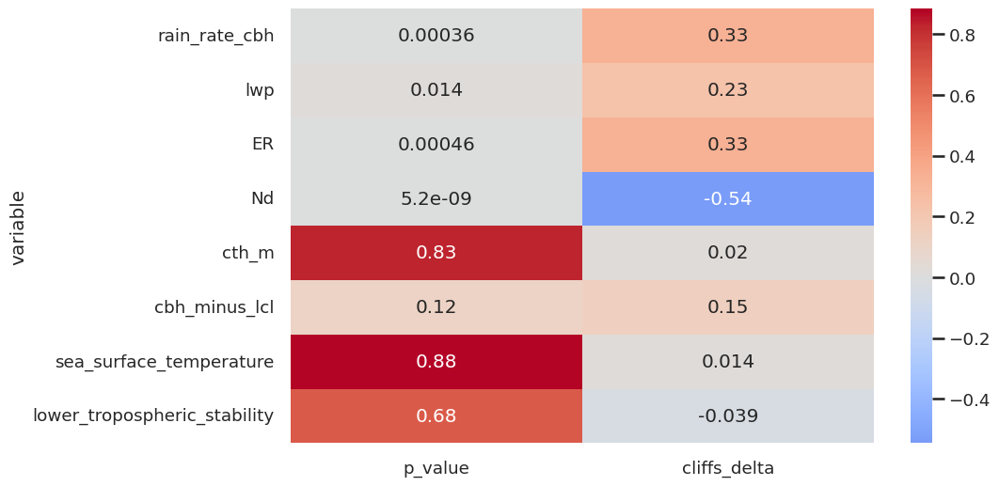

In [97]:
# heatmap of the significance results
fig, ax = plt.subplots(figsize=(10,6))
sns.heatmap(df_significance.set_index('variable')[['p_value', 'cliffs_delta']], annot=True, cmap='coolwarm', center=0, ax=ax)
plt.show()

In [ ]:
import statsmodels.formula.api as smf

var = 'rain_rate_cbh'
df1 = dfall_trans_co[(dfall_trans_co.cats == 1) & (dfall_trans_co.lwp > 0)][['scene_id', var]].fillna(0)
df2 = dffil_matched[(dffil_matched.cats == 1) & (dffil_matched.lwp > 0)][['scene_id', var]].fillna(0)

if var == 'rain_rate_cbh':
    df1[var] = df1[var] * 3600 * 24  # convert to mm/day
    df2[var] = df2[var] * 3600 * 24  # convert to mm/day
if var == 'Nd':
    df1[var] = df1[var] / 1e6  # convert to cm^-3
    df2[var] = df2[var] / 1e6  # convert to cm^-3
if var == 'ER':
    df1[var] = df1[var] * 1e6  # convert to microns
    df2[var] = df2[var] * 1e6  # convert to microns
df1['transition'] = 1
df2['transition'] = 0
df_tmp = pd.concat([df1, df2], ignore_index=True)

# Mixed-effects model:
# rain_rate_cbh ~ transition (fixed effect)
# scene_id as random intercept
model = smf.mixedlm(f"{var} ~ transition", df_tmp, groups=df_tmp["scene_id"])
result = model.fit()

print(result.summary())


           Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: rain_rate_cbh
No. Observations: 22784   Method:             REML         
No. Groups:       208     Scale:              2.4173       
Min. group size:  61      Log-Likelihood:     -42582.0646  
Max. group size:  226     Converged:          Yes          
Mean group size:  109.5                                    
------------------------------------------------------------
               Coef.  Std.Err.    z    P>|z|  [0.025  0.975]
------------------------------------------------------------
Intercept      0.081     0.030  2.676  0.007   0.022   0.140
transition     0.170     0.061  2.786  0.005   0.050   0.289
Group Var      0.121     0.009                              



2025-10-09 16:22:39,101 - matplotlib.category - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-10-09 16:22:39,107 - matplotlib.category - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


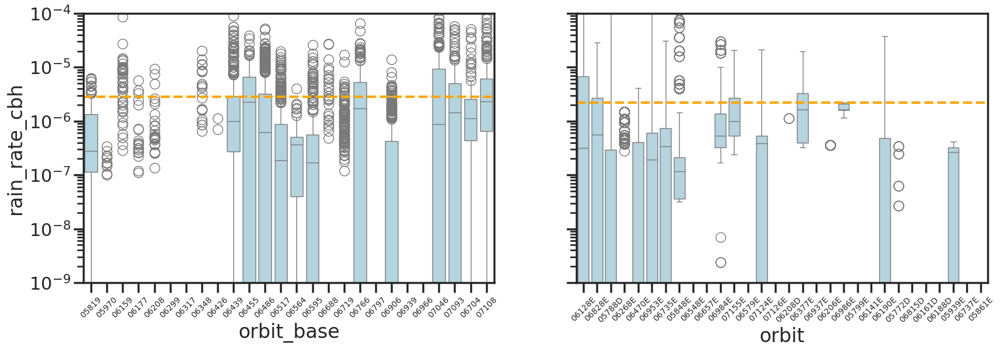

In [ ]:
yvar = 'rain_rate_cbh'
ylim = (1e-9, 1e-4)
fig, axs = plt.subplots(1,2,figsize=(20,6), sharey=True)
ax=axs[0]
sns.boxplot(ax=ax, data=dfall_trans_co[dfall_trans_co.cats == 1].fillna(0), x='orbit_base', y=yvar, color='lightblue')
ax.set_ylim(ylim)
ax.set_yscale('log')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, fontsize=10)
ax.axhline(y=dfall_trans_co[dfall_trans_co.cats == 1][yvar].fillna(0).median(), color='red', linestyle='--', label='median C-O transitions')
ax.axhline(y=dfall_trans_co[dfall_trans_co.cats == 1][yvar].fillna(0).mean(), color='orange', linestyle='--', label='mean C-O transitions')

ax=axs[1]
sns.boxplot(ax=ax, data=dffil_matched[(dffil_matched.cats == 1)].fillna(0), x='orbit', y=yvar, color='lightblue')
ax.set_yscale('log')
ax.set_ylim(ylim)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, fontsize=10)
ax.axhline(y=dffil_matched[dffil_matched.cats == 1][yvar].fillna(0).median(), color='red', linestyle='--', label='median non-transitions')
ax.axhline(y=dffil_matched[dffil_matched.cats == 1][yvar].fillna(0).mean(), color='orange', linestyle='--', label='mean non-transitions')

In [41]:
dffil['stratus_region_index'] == 0

0          True
1          True
2          True
3          True
4          True
          ...  
508328    False
508329    False
508330    False
508331    False
508332    False
Name: stratus_region_index, Length: 508333, dtype: bool

In [ ]:
dffil[(dffil['stratus_region_index'] == sr)]

ValueError: operands could not be broadcast together with shapes (508333,) (2,) 

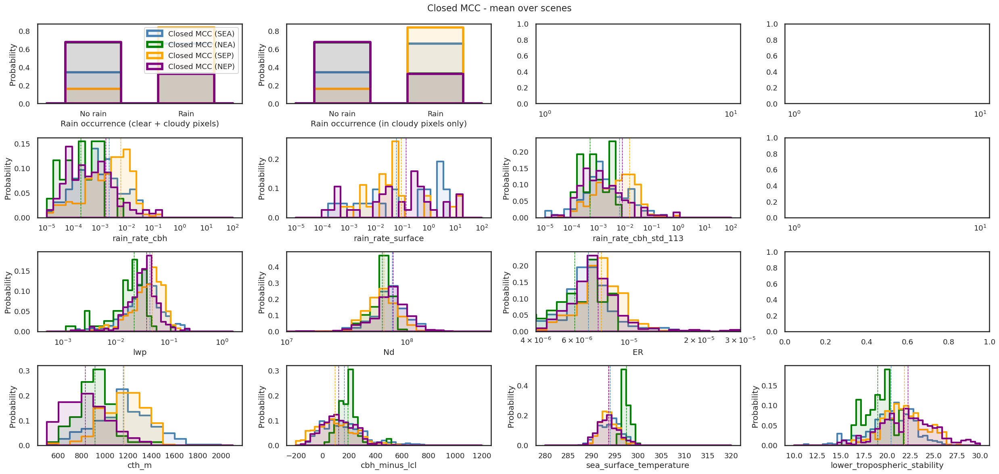

In [46]:
taking_mean = True
fig, ax = plt.subplots(4,4, figsize=(25, 12))

cat = 1
for sr in [0,1,2,3]: 
    tmp = dffil[(dffil['cats'] == i) & (dffil['stratus_region_index'] == sr)]
    if taking_mean:
        tmp = tmp[tmp.lwp > 0].fillna(0)
        tmp = tmp[['scene_id', 'rain_rate_subcloud', 'rain_rate_cbh', 'rain_rate_surface', 
                    'rain_rate_cbh_113', 'rain_rate_cbh_everywhere_113', 'rain_rate_cbh_std_113',
                    'lwp', 'ER', 'Nd', 'cth_m', 'cbh_minus_lcl', 
                    'sea_surface_temperature', 'lower_tropospheric_stability']].groupby('scene_id').mean()
        fig.suptitle(f'{cats_names[cat]} - mean over scenes', fontsize=16)
    else:
        fig.suptitle(f'{cats_names[cat]} - profile by profile', fontsize=16)
    if sr == 0:
        color = 'steelblue'
    elif sr == 1:
        color = 'green'
    elif sr == 2:
        color = 'orange'
    elif sr == 3:
        color = 'purple'
    for i in [cat]: #6
        sns.histplot(ax=ax[0,0], x=(tmp['rain_rate_subcloud'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=color, lw=4, label = f'{cats_names[cat]} ({stratus_region_names[sr]})')
        sns.histplot(ax=ax[0,1], x=(tmp[tmp.lwp>0]['rain_rate_subcloud'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=color, lw=4)

        sns.histplot(
            ax=ax[1,0], x=tmp['rain_rate_cbh']*3600, bins=np.logspace(-5,2,30),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3,
            color=color)
        ax[1,0].axvline(x=tmp['rain_rate_cbh'].mean()*3600, color=color, lw=1, ls='--')
        sns.histplot(
            ax=ax[1,1], x=tmp['rain_rate_surface']*3600, bins=np.logspace(-5,2,30),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3,
            color=color)
        ax[1,1].axvline(x=tmp['rain_rate_surface'].mean()*3600, color=color, lw=1, ls='--')
        sns.histplot(
            ax=ax[1,2], x=tmp['rain_rate_cbh_std_113']*3600, bins=np.logspace(-5,2,30),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3,
            color=color)
        ax[1,2].axvline(x=tmp['rain_rate_cbh_std_113'].mean()*3600, color=color, lw=1, ls='--')
        
        # TODO lwp and Nd errors are not taken into account
        sns.histplot(
            ax=ax[2,0], data=tmp[(tmp['lwp'] > 0)], x='lwp', bins=np.logspace(-3.3,0.2,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3,
            color=color)
        ax[2,0].axvline(x=tmp['lwp'].mean(), color=color, lw=1, ls='--')
        sns.histplot(
            ax=ax[2,1], data=tmp[(tmp['lwp'] > 0)], x='Nd', bins=np.logspace(6,9,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3,
            color=color).set(xlim=(1e7,5e8))
        ax[2,1].axvline(x=tmp['Nd'].mean(), color=color, lw=1, ls='--')
        sns.histplot(
            ax=ax[2,2], data=tmp[(tmp['lwp'] > 0)], x='ER', bins=np.logspace(-5.7,-4,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3,
            color=color).set(xlim=(4e-6,3e-5))
        ax[2,2].axvline(x=tmp['ER'].mean(), color=color, lw=1, ls='--')
        
        sns.histplot(
            ax=ax[3,0], data=tmp, x='cth_m', bins=np.arange(500,2200,100),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3,
            color=color)
        ax[3,0].axvline(x=tmp['cth_m'].mean(), color=color, lw=1, ls='--')
        sns.histplot(
            ax=ax[3,1], data=tmp, x='cbh_minus_lcl', bins=np.linspace(-200,1200,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3,
            color=color)
        ax[3,1].axvline(x=tmp['cbh_minus_lcl'].mean(), color=color, lw=1, ls='--')
        sns.histplot(
            ax=ax[3,2], data=tmp, x='sea_surface_temperature', bins=np.linspace(280,320,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3,
            color=color)
        ax[3,2].axvline(x=tmp['sea_surface_temperature'].mean(), color=color, lw=1, ls='--')
        sns.histplot(
            ax=ax[3,3], data=tmp, x='lower_tropospheric_stability', bins=np.linspace(10,30,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3,
            color=color)
        ax[3,3].axvline(x=tmp['lower_tropospheric_stability'].mean(), color=color, lw=1, ls='--')

ax[0,0].legend()
for a in ax.flatten()[2:11]:
    a.set_xscale('log')

for a in ax.flatten()[0:2]:
    a.set_xticks([0,1])
    a.set_xticklabels(['No rain', 'Rain'])
ax[0,0].set_xlabel('Rain occurrence (clear + cloudy pixels)')
ax[0,1].set_xlabel('Rain occurrence (in cloudy pixels only)')
fig.tight_layout()

##### Plot example frames

Selecting frame from 6 to 4874


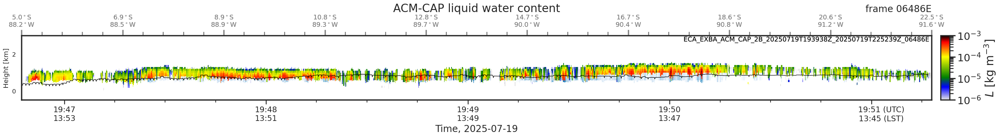

In [47]:
orbit = '06486E'

add_LCL = True

df_orbit = df[df.orbit == orbit].copy()

index_to_region = {
    0: 'SEA',
    1: 'NEA',
    2: 'SEP',
    3: 'NEP',
}
region = index_to_region[int(df_orbit['stratus_region_index'].iloc[0])]
(lat_min, lat_max) = stratus_regions[region]['lat']
(lon_min, lon_max) = stratus_regions[region]['lon']
month = pd.to_datetime(df_orbit['time'].iloc[0]).month
day = pd.to_datetime(df_orbit['time'].iloc[0]).day

filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/*{month}/*{day}/*_{orbit}.h5')[0]
ds = ecio.load_ACMCAP(filename)
ds = ds[['latitude', 'longitude', 'time', 'height', 'liquid_water_content', 'ice_water_content', 'liquid_classification', 'rain_rate']]

encoding = ds.encoding
ds = ds.where((ds.latitude > lat_min) & (ds.latitude < lat_max) & (ds.longitude > lon_min) & (ds.longitude < lon_max), drop=True)
ds.encoding = encoding.copy()

# plot
fig, ax = plt.subplots(1,1, figsize=(35,2.5))
ecplt.plot_EC_2D(ax, ds, 'rain_rate', "$R$", scale_factor=3600., units="mmh$^{-1}$", 
                    plot_scale='log', plot_range=[1e-3, 1e1], hmax=3000, cmap='Blues')
ax.collections[0].colorbar.remove()
ecplt.plot_EC_2D(ax, ds, 'liquid_water_content', "$L$", units="kg m$^{-3}$", 
                    plot_scale='log', plot_range=[1e-6, 1e-3], cmap='chiljet2', hmax=3000)
if add_LCL:
    df_orbit['time'] = pd.to_datetime(df_orbit.time)
    sns.lineplot(ax=ax, data=df_orbit, x='time', y='lcl', color='black', lw=1)

In [47]:
def plot_frames(orbit, df=df, add_LCL=True, highlight_timesteps=None, add_judge_results=True):
    df_orbit = df[df.orbit == orbit].copy()

    index_to_region = {
        0: 'SEA',
        1: 'NEA',
        2: 'SEP',
        3: 'NEP',
    }
    region = index_to_region[int(df_orbit['stratus_region_index'].iloc[0])]
    (lat_min, lat_max) = stratus_regions[region]['lat']
    (lon_min, lon_max) = stratus_regions[region]['lon']
    month = pd.to_datetime(df_orbit['time'].iloc[0]).month
    day = pd.to_datetime(df_orbit['time'].iloc[0]).day
    
    # load ACMCAP
    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/*{month}/*{day}/*_{orbit}.h5')[0]
    ds = ecio.load_ACMCAP(filename)
    ds = ds[['latitude', 'longitude', 'time', 'height', 'liquid_water_content', 'liquid_classification', 'rain_rate', 'CPR_doppler_velocity']]

    encoding = ds.encoding
    ds = ds.where((ds.latitude > lat_min) & (ds.latitude < lat_max) & (ds.longitude > lon_min) & (ds.longitude < lon_max), drop=True)
    ds.encoding = encoding.copy()

    # load MCOP
    try:
        filename = glob.glob(f'/home/jmayer/Object_Data/MSI_COP_2A/2025/*{month}/*{day}/*_{orbit}.h5')[0]
        MCOP = ecio.load_MCOP(filename)
        MCOP = MCOP.assign_coords(
            {
            'along_track': (
                ["along_track"],
                MCOP['along_track'].data,
                MCOP['along_track'].attrs
                ),
            'across_track': (
                ['across_track'],
                MCOP['across_track'].data,
                MCOP['across_track'].attrs
                )
            })
        MCOP2 = MCOP.where((MCOP.latitude > lat_min) & (MCOP.latitude < lat_max) & (MCOP.longitude > lon_min) & (MCOP.longitude < lon_max), drop=True)
        MCOP2 = MCOP2[['latitude','longitude','cloud_water_path','cloud_optical_thickness','cloud_effective_radius']]
        MCOP2['time'] = MCOP['time'].sel(along_track=MCOP2.along_track)
        MCOP2 = MCOP2.assign_coords(
            {
            'time': (
                ['along_track'],
                MCOP2.time.data,
                MCOP2.time.attrs
                )
            })
        MCOP2 = MCOP2.swap_dims({'along_track': 'time'})
    except:
        print(f'No MCOP data for {orbit}')
        MCOP2 = None

    # plot
    fig, axs = plt.subplots(3,1, figsize=(35,15), gridspec_kw={'height_ratios': [1, 1, 1.2]})
    df_orbit['time'] = pd.to_datetime(df_orbit.time)

    
    # background for selected times
    if highlight_timesteps is not None:
        for ax in axs:
            for ht in highlight_timesteps:
                ax.axvspan(ht - pd.to_timedelta('00:00:00.025'), ht + pd.to_timedelta('00:00:00.025'), 
                            color='yellow', alpha=0.3)
    #ax = axs[0]
    #ecplt.plot_EC_2D(ax, ds, 'CPR_doppler_velocity', "$w$", hmax=3000, cmap='RdBu', plot_range=[-1,1])

    ax = axs[0]
    ecplt.plot_EC_2D(ax, ds, 'rain_rate', "$R$", scale_factor=3600., units="mmh$^{-1}$", 
                        plot_scale='log', plot_range=[1e-3, 1e1], hmax=3000, cmap='Blues')
    sns.lineplot(ax=ax, data=df_orbit, x='time', y='cth_m', color='grey', lw=1)
    sns.lineplot(ax=ax, data=df_orbit, x='time', y='cbh_m', color='grey', lw=1)
    #ax.collections[0].colorbar.remove()

    ax = axs[1]
    ecplt.plot_EC_2D(ax, ds, 'liquid_water_content', "$L$", units="kg m$^{-3}$", 
                        plot_scale='log', plot_range=[1e-6, 1e-3], cmap='chiljet2', hmax=3000)

    if add_LCL:
        sns.lineplot(ax=ax, data=df_orbit, x='time', y='lcl', color='black', lw=1)

    if MCOP2 is not None:
        ax = axs[2]
        ax.sharex(axs[0])
        (np.log(MCOP2.cloud_water_path*1000)).T.plot(ax=ax, cmap='viridis', vmax=7, vmin=2.5, add_colorbar=False)
        ax.axhline(284, color='k', linestyle='--', lw=2)
        ax.set_title('MCOP liquid water path')
        # add cbar to the right
        cbar_ax = fig.add_axes([0.99, 0.11, 0.009, 0.18])  # [left, bottom, width, height]
        cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
        cbar.set_label('LWP [kg m$^{-2}$]')
        cbar.set_ticks([3,4,5,6])

    if add_judge_results:
        ax = axs[2]
        colors = ['#1f77b4', '#2ca02c', '#ff7f0e',  '#d62728', '#e377c2', '#8c564b', 'white'] # last color is for ice
        palette = {0: colors[0], 1: colors[1], 2: colors[2], 3: colors[3], 4: colors[4], 5: colors[5], 6: colors[6]}
        tmp = df_orbit[['scene_id', 'cats', 'cert', 'time']].groupby('scene_id').first()
        tmp2 = df_orbit[['scene_id', 'time']].groupby('scene_id').last()
        timedelta = (tmp2['time'] - tmp['time']) / 2
        tmp['time_mid'] = (tmp['time'] + timedelta)
        sns.scatterplot(ax=ax, data=tmp, x='time_mid', y=284, hue='cats', size=tmp.cert.values, palette=palette, size_norm=(0.3,1), legend=False)

    for ax in axs:
        ax.set_title('')
    fig.tight_layout()
    plt.show()

In [40]:
dfall_trans_co.orbit.unique()

array(['05819D', '05970E', '06159E', '06177D', '06208E', '06299E',
       '06317D', '06348E', '06426D', '06439E', '06455E', '06486E',
       '06517E', '06564E', '06595E', '06688E', '06719E', '06766E',
       '06797E', '06906E', '06939D', '06966E', '07046E', '07093E',
       '06704E', '07108E'], dtype=object)

In [41]:
dffil_matched.orbit.unique()

array(['05817E', '06190E', '06206E', '06237E', '06268E', '06408E',
       '06470E', '06548E', '06579E', '06610E', '06626E', '06657E',
       '05799E', '06188D', '06188E', '06297E', '05788D', '05928D',
       '05959D', '06161D', '06208D', '06348D', '06735E', '06828E',
       '06937E', '06953E', '06984E', '07077E', '07124E', '07155E',
       '06737E', '06815D', '06986E', '07126E', '05801E', '05848E',
       '06128E', '06377E', '05939E', '06141E', '05772D', '05912D',
       '06846D'], dtype=object)

In [42]:
dffil_matched['sample_size'] = dffil_matched.groupby('orbit').transform('size')
dffil_matched.sort_values('sample_size', ascending=False, inplace=True)
dffil_matched

,time,N_high_cc,along_track,latitude,longitude,daytime,lwp,ER,Nd,lwp_error,...,scene_id_0,MCOP_cloud_cover_judge,MCOP_cwp_skew_judge,MCOP_cwp_inhomogeneity_judge,scene_id_1,scene_id,rain_rate_cbh_113,rain_rate_cbh_everywhere_113,rain_rate_cbh_std_113,sample_size
12658,2025-06-04 23:01:28.781621632,6.0,4015,31.166755,-131.901017,1,0.019845,7.109535e-06,36953724.0,0.297469,...,NaN,0.881775,1.534323,0.575503,3896.0,12494.0,0.000003,2.515044e-08,2.661673e-07,1130
12659,2025-06-04 23:01:28.918043648,6.0,4016,31.157963,-131.903059,1,0.005832,4.294719e-06,44449032.0,0.450634,...,NaN,0.881775,1.534323,0.575503,3896.0,12494.0,0.000003,2.515044e-08,2.661673e-07,1130
12660,2025-06-04 23:01:29.054465664,6.0,4017,31.149171,-131.905100,1,0.000066,9.099478e-07,51809792.0,0.508722,...,NaN,0.881775,1.534323,0.575503,3896.0,12494.0,0.000003,2.515044e-08,2.661673e-07,1130
12661,2025-06-04 23:01:29.190887808,6.0,4018,31.140379,-131.907140,1,0.000063,9.237505e-07,56745960.0,0.299922,...,NaN,0.881775,1.534323,0.575503,3896.0,12494.0,0.000003,2.515044e-08,2.661673e-07,1130
12662,2025-06-04 23:01:29.327309568,6.0,4019,31.131587,-131.909181,1,0.000123,1.060654e-06,57555932.0,0.407027,...,NaN,0.881775,1.534323,0.575503,3896.0,12494.0,0.000003,2.515044e-08,2.661673e-07,1130
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12994,2025-06-12 22:18:15.637565568,4.0,4464,27.030955,-121.779469,1,0.010753,5.611951e-06,72126792.0,0.381083,...,NaN,0.996399,0.636899,0.383174,4113.0,12711.0,NaN,0.000000e+00,0.000000e+00,112
12995,2025-06-12 22:18:15.773717888,4.0,4465,27.022168,-121.781397,1,0.004777,2.852298e-06,70387816.0,0.275456,...,NaN,0.996399,0.636899,0.383174,4113.0,12711.0,NaN,0.000000e+00,0.000000e+00,112
12996,2025-06-12 22:18:15.956821888,4.0,4466,27.010350,-121.783989,1,0.000722,1.854465e-06,68317048.0,0.438754,...,NaN,0.996399,0.636899,0.383174,4113.0,12711.0,NaN,0.000000e+00,0.000000e+00,112
12997,2025-06-12 22:18:16.092975616,4.0,4467,27.001563,-121.785916,1,0.013978,4.898985e-06,69058352.0,0.155220,...,NaN,0.996399,0.636899,0.383174,4113.0,12711.0,NaN,0.000000e+00,0.000000e+00,112


In [43]:
dffil_matched.orbit

12658    05788D
12659    05788D
12660    05788D
12661    05788D
12662    05788D
          ...  
12994    05912D
12995    05912D
12996    05912D
12997    05912D
12998    05912D
Name: orbit, Length: 17724, dtype: object

In [ ]:
for orbit in dffil_matched.orbit.unique():
    plot_frames(orbit=orbit, highlight_timesteps=dffil_matched[dffil_matched.orbit == orbit].time)

In [ ]:
for orbit in dfall_trans_co.orbit.unique():
    plot_frames(orbit=orbit, highlight_timesteps=dfall_trans_co[dfall_trans_co.orbit == orbit].time)
sns.set_context("talk", font_scale=0.8)

## transitions as function of CTH

In [ ]:
df

,Unnamed: 0.1,time,N_high_cc,Unnamed: 0,along_track,latitude,longitude,daytime,lwp,ER,...,MCOP_cwp_skew_judge_0,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1,ocean_mask,cats,cert,scene_id,ice_flag,MCOP_cloud_cover_judge
1414,1414,2025-05-01 13:59:41.424672128,10,1414,2980,-5.000860,-1.220043,True,0.001366,0.000001,...,-1.0,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0
1415,1415,2025-05-01 13:59:41.561167744,11,1415,2981,-5.009697,-1.221703,True,0.001494,0.000001,...,-1.0,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0
1416,1416,2025-05-01 13:59:41.697661696,11,1416,2982,-5.018534,-1.223362,True,0.005736,0.000004,...,-1.0,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0
1417,1417,2025-05-01 13:59:41.834155776,11,1417,2983,-5.027372,-1.225021,True,0.009257,0.000013,...,-1.0,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0
1418,1418,2025-05-01 13:59:42.015209856,11,1418,2984,-5.039095,-1.227221,True,0.010426,0.000018,...,-1.0,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1013340,1013340,2025-07-31 23:09:46.311145728,0,1013340,4638,25.419477,-134.991371,True,0.000000,NaN,...,-1.0,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0
1013341,1013341,2025-07-31 23:09:46.446427520,0,1013341,4639,25.410741,-134.993248,True,0.000000,NaN,...,-1.0,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0
1013342,1013342,2025-07-31 23:09:46.581705600,0,1013342,4640,25.402005,-134.995125,True,0.000000,NaN,...,-1.0,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0
1013343,1013343,2025-07-31 23:09:46.716985856,0,1013343,4641,25.393270,-134.997002,True,0.000000,NaN,...,-1.0,-1.0,-1.0,-1.0,True,6,-1.0,-1,-1.0,-1.0


In [ ]:
df['cth_m_113'] = df.groupby(['orbit', 'scene_id'])['cth_m'].transform(lambda x: np.nanmean(x))

In [ ]:
import scipy
stcu_to_incr_cth = pd.DataFrame(columns=['orbit', 'scene_id_start_stcu', 'scene_id_end_stcu', 'cth_change', 'cth_max', 'cth_min'])
incr_cth_to_stcu = pd.DataFrame(columns=['orbit', 'scene_id_start_stcu', 'scene_id_end_stcu', 'cth_change', 'cth_max', 'cth_min'])

for orbit, dforbit in df.groupby('orbit'):
    dfscenes = dforbit.groupby('scene_id')[['orbit','scene_id','cats','cert','ice_flag','ocean_mask','cth_m_113']].first()

    # flag StCu regions, defined as at least 5 scenes of cats = 0,1,2 in a row
    dfscenes = dforbit.groupby('scene_id')[['orbit','scene_id','cats','cert','ice_flag','ocean_mask','cth_m_113']].first()

    dfscenes['stcu_cats'] = np.where(dfscenes.cats.isin([0,1,2]), 1, 0)
    # label stcu regions and get their sizes using scipy.ndimage
    stcu_regions, num_features = scipy.ndimage.label(dfscenes['stcu_cats'])
    # remove small regions < 4 consecutive scenes
    for i in range(1, num_features+1):
        region_indices = np.where(stcu_regions == i)[0]
        region_size = len(region_indices)
        if region_size < 4:
            stcu_regions[region_indices] = 0 
            num_features -= 1

    if num_features == 0:
        continue
    # first index of rightmost stcu region
    start_idx_rightmost_stcu = np.where(stcu_regions == stcu_regions.max())[0][0]
    end_idx_rightmost_stcu = np.where(stcu_regions == stcu_regions.max())[0][-1]
    scenes_right_of_stcu = dfscenes.iloc[start_idx_rightmost_stcu : ]
    # check if cth_m_113 is increasing to the right of the stcu region
    change_of_cth = scenes_right_of_stcu.cth_m_113.diff().dropna().sum()
    if (change_of_cth > 400):
        #if (scenes_right_of_stcu.cth_m_113.diff().dropna() >= -100).all():
        tmp = pd.DataFrame({
            'orbit': [orbit], 
            'scene_id_start_stcu': [dfscenes.iloc[start_idx_rightmost_stcu].scene_id], 
            'scene_id_end_stcu': [dfscenes.iloc[end_idx_rightmost_stcu].scene_id], 
            'cth_change': [change_of_cth],
            'cth_max': [scenes_right_of_stcu.cth_m_113.max()],
            'cth_min': [scenes_right_of_stcu.cth_m_113.min()]
        })
        stcu_to_incr_cth = pd.concat([stcu_to_incr_cth, tmp], ignore_index=True)

    # last index of leftmost stcu region
    start_idx_leftmost_stcu = np.where(stcu_regions > 0)[0][0]
    end_idx_leftmost_stcu = np.where(stcu_regions > 0)[0][-1]
    scenes_left_of_stcu = dfscenes.iloc[: end_idx_leftmost_stcu + 1]
    # check if cth_m_113 is increasing to the left of the stcu region (i.e., decreasing to the right)
    change_of_cth = scenes_left_of_stcu.cth_m_113.diff().dropna().sum()
    if (change_of_cth < -400):
        tmp = pd.DataFrame({
            'orbit': [orbit], 
            'scene_id_start_stcu': [dfscenes.iloc[start_idx_leftmost_stcu].scene_id], 
            'scene_id_end_stcu': [dfscenes.iloc[end_idx_leftmost_stcu].scene_id], 
            'cth_change': [change_of_cth],
            'cth_max': [scenes_left_of_stcu.cth_m_113.max()],
            'cth_min': [scenes_left_of_stcu.cth_m_113.min()]
        })
        incr_cth_to_stcu = pd.concat([incr_cth_to_stcu, tmp], ignore_index=True)

In [ ]:
stcu_to_incr_cth

,orbit,scene_id_start_stcu,scene_id_end_stcu,cth_change,cth_max,cth_min
0,05274D,5108,5126,456.272279,1128.476192,641.525272
1,05383D,5297,5307,515.688928,1028.295549,512.606621
2,05414E,5371,5381,647.635381,1187.118173,385.249367
3,05492D,5421,5427,681.256792,1316.475203,635.218412
4,05539D,5486,5498,620.424837,1138.905394,518.480558
5,05595E,262,278,408.427151,1183.702783,775.275632
6,05770E,2157,2187,499.745569,1438.522772,855.689930
7,05788D,5728,5748,927.441720,1546.391696,588.152011
8,05803D,5758,5776,504.553463,1463.443210,818.990627
9,05881D,5890,5910,576.264431,1027.125576,450.861146


In [ ]:
incr_cth_to_stcu

,orbit,scene_id_start_stcu,scene_id_end_stcu,cth_change,cth_max,cth_min
0,05332E,3448,3454,-414.728107,785.457873,331.021480
1,05539D,5486,5498,-579.698082,1443.193926,518.480558
2,05766E,442,450,-636.475175,2562.853888,719.273796
3,05972E,2483,2493,-602.071068,1943.610515,993.975681
4,06124E,805,811,-618.915451,1822.808591,880.014154
5,06130D,6092,6106,-410.740175,1275.668092,422.184457
6,06208E,6249,6255,-446.196380,1461.968453,1015.772073
7,06237E,2661,2669,-419.060313,1863.710166,787.471316
8,06295E,1056,1062,-560.220067,1020.447274,639.204546
9,06297E,4445,4451,-836.023574,1872.902163,946.390553


In [17]:
for i in stcu_to_incr_cth.index:  
    orbit = stcu_to_incr_cth.loc[i, 'orbit']
    scene_id_start_stcu = stcu_to_incr_cth.loc[i, 'scene_id_start_stcu']
    scene_id_end_stcu = stcu_to_incr_cth.loc[i, 'scene_id_end_stcu']
    cth_max = stcu_to_incr_cth.loc[i, 'cth_max']
    if cth_max > 1500:
        print(f'Orbit {orbit}')
        dforbit = df[df.orbit == orbit]
        dforbit = dforbit[(dforbit.scene_id >= scene_id_start_stcu)].reset_index(drop=True)
        
        fig, axs = plt.subplots(9,1, figsize=(15,10), sharex=True)
        ax=axs[0]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='cth_m', color='limegreen', s=10, alpha=0.5).set(ylim=(400,3000))
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='cth_m_113', color='green', s=10, alpha=0.5).set(ylim=(400,2500))
        #sns.lineplot(ax=ax, data=dforbit, x='time', y='cth_m', color='black', linewidth=2)
        ax.set_ylabel('CTH', color='limegreen')
        
        ax=axs[1]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='cats', hue='cats', palette=palette_catscolors, s=10, alpha=0.5).set(ylim=(-0.3,5.3))
        ax.set_ylabel('cats', color='black')

        ax=axs[2]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='cbh_minus_lcl', color='red', s=10, alpha=0.5).set(ylim=(-200,700))
        #sns.lineplot(ax=ax, data=dforbit, x='time', y='cbh_minus_lcl', color='black', linewidth=2)
        ax.set_ylabel('CBH - LCL (m)', color='red')

        ax=axs[3]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='cbh_min_max_100km', color='steelblue', s=10, alpha=0.5).set(ylim=(0,10))
        ax.set_ylabel('CBH min-max', color='steelblue')

        ax=axs[4]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='multilayer', color='red', s=10, alpha=0.5).set(ylim=(-0.1,1.1))
        ax.set_ylabel('Multilayer', color='red')

        ax=axs[5]
        sns.scatterplot(ax=ax, data=dforbit[dforbit['lwp']>0], x='time', y='lwp', color='steelblue', s=10, alpha=0.5).set(yscale='log')
        ax.set_ylabel('LWP (g m$^{-2}$)', color='steelblue')

        ax=axs[6]
        sns.scatterplot(ax=ax, data=dforbit[dforbit['rain_rate_cbh']>0], x='time', y='rain_rate_cbh', color='blue', s=10, alpha=0.5).set(yscale='log')
        ax.set_ylabel('RR at CBH', color='blue')

        ax=axs[7]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='lower_tropospheric_stability', color='green', s=10, alpha=0.5).set(ylim=(7,30))
        #sns.lineplot(ax=ax, data=dforbit, x='time', y='lower_tropospheric_stability', color='black', linewidth=2)
        ax.set_ylabel('LTS', color='green')

        ax=axs[8]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='sea_surface_temperature', color='orange', s=10, alpha=0.5).set(ylim=(285,300))
        ax.set_ylabel('SST', color='orange')

        for ax in axs:
            ax.axvline(x=dforbit[dforbit.scene_id == scene_id_end_stcu]['time'].values[-1], color='gray', linestyle='--')
        plt.show()

NameError: name 'stcu_to_incr_cth' is not defined

In [ ]:
for i in incr_cth_to_stcu.index:  
    orbit = incr_cth_to_stcu.loc[i, 'orbit']
    scene_id_start_stcu = incr_cth_to_stcu.loc[i, 'scene_id_start_stcu']
    scene_id_end_stcu = incr_cth_to_stcu.loc[i, 'scene_id_end_stcu']
    cth_max = incr_cth_to_stcu.loc[i, 'cth_max']
    if cth_max > 1500:
        print(f'Orbit {orbit}')
        dforbit = df[df.orbit == orbit]
        dforbit = dforbit[(dforbit.scene_id <= scene_id_end_stcu)].reset_index(drop=True)
        
        fig, axs = plt.subplots(9,1, figsize=(15,10), sharex=True)
        ax=axs[0]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='cth_m', color='limegreen', s=10, alpha=0.5).set(ylim=(400,3000))
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='cth_m_113', color='green', s=10, alpha=0.5).set(ylim=(400,2500))
        #sns.lineplot(ax=ax, data=dforbit, x='time', y='cth_m', color='black', linewidth=2)
        ax.set_ylabel('CTH', color='limegreen')
        
        ax=axs[1]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='cats', hue='cats', palette=palette_catscolors, s=10, alpha=0.5).set(ylim=(-0.3,5.3))
        ax.set_ylabel('cats', color='black')

        ax=axs[2]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='cbh_minus_lcl', color='red', s=10, alpha=0.5).set(ylim=(-200,700))
        #sns.lineplot(ax=ax, data=dforbit, x='time', y='cbh_minus_lcl', color='black', linewidth=2)
        ax.set_ylabel('CBH - LCL (m)', color='red')

        ax=axs[3]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='cbh_min_max_100km', color='steelblue', s=10, alpha=0.5).set(ylim=(0,10))
        ax.set_ylabel('CBH min-max', color='steelblue')

        ax=axs[4]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='multilayer', color='red', s=10, alpha=0.5).set(ylim=(-0.1,1.1))
        ax.set_ylabel('Multilayer', color='red')

        ax=axs[5]
        sns.scatterplot(ax=ax, data=dforbit[dforbit['lwp']>0], x='time', y='lwp', color='steelblue', s=10, alpha=0.5).set(yscale='log')
        ax.set_ylabel('LWP (g m$^{-2}$)', color='steelblue')

        ax=axs[6]
        sns.scatterplot(ax=ax, data=dforbit[dforbit['rain_rate_cbh']>0], x='time', y='rain_rate_cbh', color='blue', s=10, alpha=0.5).set(yscale='log')
        ax.set_ylabel('RR at CBH', color='blue')

        ax=axs[7]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='lower_tropospheric_stability', color='green', s=10, alpha=0.5).set(ylim=(7,30))
        #sns.lineplot(ax=ax, data=dforbit, x='time', y='lower_tropospheric_stability', color='black', linewidth=2)
        ax.set_ylabel('LTS', color='green')

        ax=axs[8]
        sns.scatterplot(ax=ax, data=dforbit, x='time', y='sea_surface_temperature', color='orange', s=10, alpha=0.5).set(ylim=(285,300))
        ax.set_ylabel('SST', color='orange')

        for ax in axs:
            ax.axvline(x=dforbit[dforbit.scene_id == scene_id_start_stcu]['time'].values[0], color='gray', linestyle='--')
        plt.show()